# 05 — KIBA Experiments

This notebook evaluates GCN + CNN, GAT + CNN and GIN + CNN on the KIBA dataset.

The models will be tested using:

1. Random drug–target pair splitting
2. Cold-drug splitting
3. Cold-target splitting

The KIBA affinity scores remain in their original form and are not converted to pKd.

# Imports and project setup

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    RANDOM_SEED,
    PROCESSED_DATA_DIR,
    SPLITS_DIR,
)

from src.splits import (
    create_random_split,
    create_cold_drug_split,
    create_cold_target_split,
    validate_split_integrity,
    save_splits,
)

from src.utils import set_random_seed

set_random_seed(RANDOM_SEED)

print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_SEED)

Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing
Random seed: 42


# Load the processed KIBA dataset

In [2]:
kiba_path = PROCESSED_DATA_DIR / "kiba_pairs.csv"

kiba_df = pd.read_csv(kiba_path)

print("KIBA shape:", kiba_df.shape)
print("Unique drugs:", kiba_df["drug_id"].nunique())
print("Unique targets:", kiba_df["target_id"].nunique())
print("Affinity type:", kiba_df["affinity_type"].unique())

display(kiba_df.head())

KIBA shape: (118254, 8)
Unique drugs: 2111
Unique targets: 229
Affinity type: <StringArray>
['KIBA_score']
Length: 1, dtype: str


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,kiba,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1,11.1,KIBA_score
1,kiba,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1,11.1,KIBA_score
2,kiba,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1,11.1,KIBA_score
3,kiba,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1,11.1,KIBA_score
4,kiba,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1,11.1,KIBA_score


In [3]:
kiba_path = PROCESSED_DATA_DIR / "kiba_pairs.csv"

kiba_df = pd.read_csv(kiba_path)

print("KIBA shape:", kiba_df.shape)
print("Unique drugs:", kiba_df["drug_id"].nunique())
print("Unique targets:", kiba_df["target_id"].nunique())
print("Affinity type:", kiba_df["affinity_type"].unique())

display(kiba_df.head())

KIBA shape: (118254, 8)
Unique drugs: 2111
Unique targets: 229
Affinity type: <StringArray>
['KIBA_score']
Length: 1, dtype: str


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,kiba,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1,11.1,KIBA_score
1,kiba,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1,11.1,KIBA_score
2,kiba,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1,11.1,KIBA_score
3,kiba,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1,11.1,KIBA_score
4,kiba,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1,11.1,KIBA_score


# Load the processed KIBA dataset

In [4]:
kiba_path = PROCESSED_DATA_DIR / "kiba_pairs.csv"

kiba_df = pd.read_csv(kiba_path)

print("KIBA shape:", kiba_df.shape)
print("Unique drugs:", kiba_df["drug_id"].nunique())
print("Unique targets:", kiba_df["target_id"].nunique())
print("Affinity type:", kiba_df["affinity_type"].unique())

display(kiba_df.head())

KIBA shape: (118254, 8)
Unique drugs: 2111
Unique targets: 229
Affinity type: <StringArray>
['KIBA_score']
Length: 1, dtype: str


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,kiba,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1,11.1,KIBA_score
1,kiba,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1,11.1,KIBA_score
2,kiba,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1,11.1,KIBA_score
3,kiba,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1,11.1,KIBA_score
4,kiba,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1,11.1,KIBA_score


In [16]:
kiba_df.isna().sum()

dataset             0
drug_id             0
target_id           0
smiles              0
protein_sequence    0
raw_affinity        0
affinity            0
affinity_type       0
dtype: int64

# Check the affinity values

In [5]:
display(
    kiba_df["affinity"]
    .describe()
    .to_frame()
)

,affinity
count,118254.000000
mean,11.719935
std,0.836947
min,0.000000
25%,11.200000
50%,11.500000
75%,11.923909
max,17.200179


 ## Random Split

Individual drug–target pairs are divided into training, validation and test sets.

Drugs and targets may appear in more than one split, but an identical pair cannot overlap.

# Create the random split

In [6]:
(
    kiba_random_train_df,
    kiba_random_validation_df,
    kiba_random_test_df,
) = create_random_split(
    dataframe=kiba_df,
    random_seed=RANDOM_SEED,
)

print("Training rows:", len(kiba_random_train_df))
print("Validation rows:", len(kiba_random_validation_df))
print("Test rows:", len(kiba_random_test_df))

print(
    "Total:",
    len(kiba_random_train_df)
    + len(kiba_random_validation_df)
    + len(kiba_random_test_df),
)

Training rows: 82777
Validation rows: 17738
Test rows: 17739
Total: 118254


# Validate the random split

In [47]:
kiba_random_report = validate_split_integrity(
    train_dataframe=kiba_random_train_df,
    validation_dataframe=kiba_random_validation_df,
    test_dataframe=kiba_random_test_df,
    split_type="random",
)

display(pd.DataFrame([kiba_random_report]))

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,82777,17738,17739,False,True,True


# Save the random split

In [8]:
kiba_random_directory = SPLITS_DIR / "random"

save_splits(
    train_dataframe=kiba_random_train_df,
    validation_dataframe=kiba_random_validation_df,
    test_dataframe=kiba_random_test_df,
    output_directory=kiba_random_directory,
    dataset_name="kiba",
)

print("KIBA random split saved.")

KIBA random split saved.


## Cold-Drug Split

The validation and test drugs are completely absent from the training data.

In [9]:
(
    kiba_cold_drug_train_df,
    kiba_cold_drug_validation_df,
    kiba_cold_drug_test_df,
) = create_cold_drug_split(
    dataframe=kiba_df,
    random_seed=RANDOM_SEED,
)

print("Training rows:", len(kiba_cold_drug_train_df))
print("Validation rows:", len(kiba_cold_drug_validation_df))
print("Test rows:", len(kiba_cold_drug_test_df))

print()
print(
    "Training drugs:",
    kiba_cold_drug_train_df["drug_id"].nunique(),
)
print(
    "Validation drugs:",
    kiba_cold_drug_validation_df["drug_id"].nunique(),
)
print(
    "Test drugs:",
    kiba_cold_drug_test_df["drug_id"].nunique(),
)

Training rows: 83966
Validation rows: 17544
Test rows: 16744

Training drugs: 1477
Validation drugs: 317
Test drugs: 317


In [10]:
kiba_cold_drug_report = validate_split_integrity(
    train_dataframe=kiba_cold_drug_train_df,
    validation_dataframe=kiba_cold_drug_validation_df,
    test_dataframe=kiba_cold_drug_test_df,
    split_type="cold_drug",
)

display(pd.DataFrame([kiba_cold_drug_report]))

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,83966,17544,16744,False,False,True


# Save the cold-drug split

In [12]:
kiba_cold_drug_directory = SPLITS_DIR / "cold_drug"

save_splits(
    train_dataframe=kiba_cold_drug_train_df,
    validation_dataframe=kiba_cold_drug_validation_df,
    test_dataframe=kiba_cold_drug_test_df,
    output_directory=kiba_cold_drug_directory,
    dataset_name="kiba",
)

print("KIBA cold-drug split saved.")

KIBA cold-drug split saved.


## Cold-Target Split

The validation and test protein targets are completely absent from the training data.

In [13]:
(
    kiba_cold_target_train_df,
    kiba_cold_target_validation_df,
    kiba_cold_target_test_df,
) = create_cold_target_split(
    dataframe=kiba_df,
    random_seed=RANDOM_SEED,
)

print("Training rows:", len(kiba_cold_target_train_df))
print("Validation rows:", len(kiba_cold_target_validation_df))
print("Test rows:", len(kiba_cold_target_test_df))

print()
print(
    "Training targets:",
    kiba_cold_target_train_df["target_id"].nunique(),
)
print(
    "Validation targets:",
    kiba_cold_target_validation_df["target_id"].nunique(),
)
print(
    "Test targets:",
    kiba_cold_target_test_df["target_id"].nunique(),
)

Training rows: 84964
Validation rows: 16513
Test rows: 16777

Training targets: 160
Validation targets: 34
Test targets: 35


In [14]:
kiba_cold_target_report = validate_split_integrity(
    train_dataframe=kiba_cold_target_train_df,
    validation_dataframe=kiba_cold_target_validation_df,
    test_dataframe=kiba_cold_target_test_df,
    split_type="cold_target",
)

display(pd.DataFrame([kiba_cold_target_report]))

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,84964,16513,16777,False,True,False


In [15]:
kiba_cold_target_directory = SPLITS_DIR / "cold_target"

save_splits(
    train_dataframe=kiba_cold_target_train_df,
    validation_dataframe=kiba_cold_target_validation_df,
    test_dataframe=kiba_cold_target_test_df,
    output_directory=kiba_cold_target_directory,
    dataset_name="kiba",
)

print("KIBA cold-target split saved.")

KIBA cold-target split saved.


# Confirm all split files

In [18]:
kiba_split_files = [
    SPLITS_DIR / "random" / "kiba_train.csv",
    SPLITS_DIR / "random" / "kiba_validation.csv",
    SPLITS_DIR / "random" / "kiba_test.csv",

    SPLITS_DIR / "cold_drug" / "kiba_train.csv",
    SPLITS_DIR / "cold_drug" / "kiba_validation.csv",
    SPLITS_DIR / "cold_drug" / "kiba_test.csv",

    SPLITS_DIR / "cold_target" / "kiba_train.csv",
    SPLITS_DIR / "cold_target" / "kiba_validation.csv",
    SPLITS_DIR / "cold_target" / "kiba_test.csv",
]

for file_path in kiba_split_files:
    print(
        file_path.parent.name,
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in kiba_split_files
)

print("All KIBA splits are ready.")

random kiba_train.csv → True
random kiba_validation.csv → True
random kiba_test.csv → True
cold_drug kiba_train.csv → True
cold_drug kiba_validation.csv → True
cold_drug kiba_test.csv → True
cold_target kiba_train.csv → True
cold_target kiba_validation.csv → True
cold_target kiba_test.csv → True
All KIBA splits are ready.


## Prepare KIBA Model Inputs

Each unique drug is converted into a molecular graph.

Each unique protein sequence is converted into a fixed-length tensor.

The processed features will be reused across all KIBA experiments.

# Imports

In [19]:
from torch_geometric.loader import DataLoader

from config import (
    BATCH_SIZE,
    NUM_WORKERS,
)

from src.preprocessing import (
    build_drug_graph_cache,
    build_protein_tensor_cache,
)

from src.dataset import DTADataset

print("Batch size:", BATCH_SIZE)
print("DataLoader workers:", NUM_WORKERS)

Batch size: 32
DataLoader workers: 0


# Create the KIBA feature caches

In [20]:
kiba_drug_graph_cache = build_drug_graph_cache(
    kiba_df
)

kiba_protein_tensor_cache = build_protein_tensor_cache(
    kiba_df
)

print(
    "Drug graphs:",
    len(kiba_drug_graph_cache),
)

print(
    "Protein tensors:",
    len(kiba_protein_tensor_cache),
)

Drug graphs: 2111
Protein tensors: 229


In [23]:
first_drug_id = str(
    kiba_df.iloc[0]["drug_id"]
)

first_target_id = str(
    kiba_df.iloc[0]["target_id"]
)

example_graph = kiba_drug_graph_cache[
    first_drug_id
]

example_protein = kiba_protein_tensor_cache[
    first_target_id
]

print("Drug ID:", first_drug_id)
print("Drug node shape:", example_graph.x.shape)
print("Drug edge shape:", example_graph.edge_index.shape)

print()

print("Target ID:", first_target_id)
print("Protein tensor shape:", example_protein.shape)

assert example_graph.x.shape[1] == 6
assert example_protein.shape[0] == 1000

print("KIBA feature creation passed.")

Drug ID: CHEMBL1087421
Drug node shape: torch.Size([21, 6])
Drug edge shape: torch.Size([2, 46])

Target ID: O00141
Protein tensor shape: torch.Size([1000])
KIBA feature creation passed.


# Create a reusable DataLoader function

In [24]:
def create_kiba_dataloaders(
    train_dataframe,
    validation_dataframe,
    test_dataframe,
):
    train_dataset = DTADataset(
        dataframe=train_dataframe,
        drug_graph_cache=kiba_drug_graph_cache,
        protein_tensor_cache=kiba_protein_tensor_cache,
    )

    validation_dataset = DTADataset(
        dataframe=validation_dataframe,
        drug_graph_cache=kiba_drug_graph_cache,
        protein_tensor_cache=kiba_protein_tensor_cache,
    )

    test_dataset = DTADataset(
        dataframe=test_dataframe,
        drug_graph_cache=kiba_drug_graph_cache,
        protein_tensor_cache=kiba_protein_tensor_cache,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    return {
        "train_dataset": train_dataset,
        "validation_dataset": validation_dataset,
        "test_dataset": test_dataset,
        "train_loader": train_loader,
        "validation_loader": validation_loader,
        "test_loader": test_loader,
    }


print("KIBA DataLoader function created.")

KIBA DataLoader function created.


# Create random-split datasets and DataLoaders

In [25]:
kiba_random_data = create_kiba_dataloaders(
    train_dataframe=kiba_random_train_df,
    validation_dataframe=kiba_random_validation_df,
    test_dataframe=kiba_random_test_df,
)

kiba_random_train_dataset = (
    kiba_random_data["train_dataset"]
)

kiba_random_validation_dataset = (
    kiba_random_data["validation_dataset"]
)

kiba_random_test_dataset = (
    kiba_random_data["test_dataset"]
)

kiba_random_train_loader = (
    kiba_random_data["train_loader"]
)

kiba_random_validation_loader = (
    kiba_random_data["validation_loader"]
)

kiba_random_test_loader = (
    kiba_random_data["test_loader"]
)

# Check dataset and batch counts

In [26]:
print(
    "Training samples:",
    len(kiba_random_train_dataset),
)

print(
    "Validation samples:",
    len(kiba_random_validation_dataset),
)

print(
    "Test samples:",
    len(kiba_random_test_dataset),
)

print()

print(
    "Training batches:",
    len(kiba_random_train_loader),
)

print(
    "Validation batches:",
    len(kiba_random_validation_loader),
)

print(
    "Test batches:",
    len(kiba_random_test_loader),
)

Training samples: 82777
Validation samples: 17738
Test samples: 17739

Training batches: 2587
Validation batches: 555
Test batches: 555


# Check one KIBA batch

In [27]:
kiba_batch = next(
    iter(kiba_random_train_loader)
)

print(
    "Graphs in batch:",
    kiba_batch.num_graphs,
)

print(
    "Drug node shape:",
    kiba_batch.x.shape,
)

print(
    "Drug edge shape:",
    kiba_batch.edge_index.shape,
)

print(
    "Protein batch shape:",
    kiba_batch.target.shape,
)

print(
    "Affinity batch shape:",
    kiba_batch.y.shape,
)

Graphs in batch: 32
Drug node shape: torch.Size([819, 6])
Drug edge shape: torch.Size([2, 1814])
Protein batch shape: torch.Size([32, 1000])
Affinity batch shape: torch.Size([32])


# Confirm the random-split data

In [28]:
assert kiba_batch.num_graphs <= BATCH_SIZE
assert kiba_batch.x.shape[1] == 6
assert kiba_batch.target.shape[1] == 1000
assert kiba_batch.y.shape[0] == kiba_batch.num_graphs

assert len(kiba_random_train_dataset) > 0
assert len(kiba_random_validation_dataset) > 0
assert len(kiba_random_test_dataset) > 0

print(
    "KIBA random-split datasets and "
    "DataLoaders are ready."
)

KIBA random-split datasets and DataLoaders are ready.


## KIBA GCN + CNN Speed Test

Before running the complete KIBA experiments, one training epoch is timed on the Mac.

This will help decide whether to continue locally or move the KIBA training runs to Google Colab.

# Import model and training tools

In [29]:
import time
import torch

from config import (
    LEARNING_RATE,
    WEIGHT_DECAY,
)

from src.models import create_dta_model
from src.training import train_one_epoch
from src.utils import (
    get_device,
    count_trainable_parameters,
    set_random_seed,
)

device = get_device()

print("Device:", device)

Device: mps


# Create a temporary GCN + CNN model

In [30]:
set_random_seed(RANDOM_SEED)

kiba_test_gcn_model = create_dta_model(
    model_name="gcn"
).to(device)

kiba_test_optimizer = torch.optim.Adam(
    kiba_test_gcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

loss_function = torch.nn.MSELoss()

print("Model: GCN + CNN")
print(
    "Trainable parameters:",
    f"{count_trainable_parameters(kiba_test_gcn_model):,}",
)

Model: GCN + CNN
Trainable parameters: 299,265


# Check one forward pass

In [31]:
example_batch = next(
    iter(kiba_random_train_loader)
).to(device)

kiba_test_gcn_model.eval()

with torch.no_grad():
    example_predictions = kiba_test_gcn_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print("KIBA GCN + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
KIBA GCN + CNN forward pass successful.


# Time one training epoch

In [32]:
if device.type == "mps":
    torch.mps.empty_cache()

start_time = time.perf_counter()

test_epoch_mse = train_one_epoch(
    model=kiba_test_gcn_model,
    data_loader=kiba_random_train_loader,
    optimizer=kiba_test_optimizer,
    loss_function=loss_function,
    device=device,
)

end_time = time.perf_counter()

epoch_time_seconds = end_time - start_time
epoch_time_minutes = epoch_time_seconds / 60

print("Test epoch MSE:", round(test_epoch_mse, 4))
print(
    "One epoch time:",
    round(epoch_time_minutes, 2),
    "minutes",
)

Test epoch MSE: 1.6703
One epoch time: 2.29 minutes


# Estimate a full training run

In [33]:
estimated_10_epochs = epoch_time_minutes * 10
estimated_20_epochs = epoch_time_minutes * 20
estimated_30_epochs = epoch_time_minutes * 30

print(
    "Estimated time for 10 epochs:",
    round(estimated_10_epochs, 1),
    "minutes",
)

print(
    "Estimated time for 20 epochs:",
    round(estimated_20_epochs, 1),
    "minutes",
)

print(
    "Estimated time for 30 epochs:",
    round(estimated_30_epochs, 1),
    "minutes",
)

Estimated time for 10 epochs: 22.9 minutes
Estimated time for 20 epochs: 45.7 minutes
Estimated time for 30 epochs: 68.6 minutes


## KIBA Random Split — GCN + CNN

A fresh GCN + CNN model is trained on the KIBA random split.

The temporary model used for the speed test is discarded so that the official experiment starts from a reproducible random initialisation.

# Import training configuration

In [36]:
import gc
import json
import time

import matplotlib.pyplot as plt
import numpy as np

import config as cfg

from src.training import (
    fit_model,
    load_checkpoint,
    evaluate_model,
)

NUM_EPOCHS = cfg.NUM_EPOCHS
EARLY_STOPPING_PATIENCE = cfg.EARLY_STOPPING_PATIENCE

# Use the config value when available.
# Otherwise, use the dissertation default.
MIN_IMPROVEMENT = getattr(
    cfg,
    "MIN_IMPROVEMENT",
    1e-4,
)

MODELS_DIR = cfg.MODELS_DIR
METRICS_DIR = cfg.METRICS_DIR
PREDICTIONS_DIR = cfg.PREDICTIONS_DIR
PLOTS_DIR = cfg.PLOTS_DIR

MODELS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Maximum epochs:", NUM_EPOCHS)
print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)
print(
    "Minimum improvement:",
    MIN_IMPROVEMENT,
)

Maximum epochs: 30
Early-stopping patience: 7
Minimum improvement: 0.0001


# Remove the temporary speed-test model

In [35]:
temporary_objects = [
    "kiba_test_gcn_model",
    "kiba_test_optimizer",
    "example_batch",
    "example_predictions",
]

for object_name in temporary_objects:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Temporary speed-test objects removed.")

Temporary speed-test objects removed.


In [37]:
kiba_gcn_random_checkpoint = (
    MODELS_DIR
    / "best_kiba_gcn_cnn_random.pt"
)

kiba_gcn_random_history_path = (
    METRICS_DIR
    / "kiba_gcn_cnn_random_history.csv"
)

kiba_gcn_random_metrics_path = (
    METRICS_DIR
    / "kiba_gcn_cnn_random_metrics.json"
)

kiba_gcn_random_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gcn_cnn_random_predictions.csv"
)

kiba_gcn_random_history_plot_path = (
    PLOTS_DIR
    / "kiba_gcn_cnn_random_history.png"
)

kiba_gcn_random_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gcn_cnn_random_predictions.png"
)

print("Checkpoint:")
print(kiba_gcn_random_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gcn_cnn_random.pt


# Create a fresh GCN + CNN model

In [38]:
set_random_seed(RANDOM_SEED)

kiba_gcn_random_model = create_dta_model(
    model_name="gcn"
).to(device)

kiba_gcn_random_optimizer = torch.optim.Adam(
    kiba_gcn_random_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gcn_random_parameter_count = (
    count_trainable_parameters(
        kiba_gcn_random_model
    )
)

print("Model: GCN + CNN")
print("Dataset: KIBA")
print("Split: random")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gcn_random_parameter_count:,}",
)

Model: GCN + CNN
Dataset: KIBA
Split: random
Device: mps
Trainable parameters: 299,265


# Confirm the fresh model output

In [39]:
verification_batch = next(
    iter(kiba_random_train_loader)
).to(device)

kiba_gcn_random_model.eval()

with torch.no_grad():
    verification_predictions = (
        kiba_gcn_random_model(
            verification_batch
        )
        .view(-1)
    )

print(
    "Prediction shape:",
    verification_predictions.shape,
)

print(
    "True-value shape:",
    verification_batch.y.view(-1).shape,
)

assert verification_predictions.shape == (
    verification_batch.y.view(-1).shape
)

assert torch.isfinite(
    verification_predictions
).all()

del verification_batch
del verification_predictions

if device.type == "mps":
    torch.mps.empty_cache()

print("Fresh KIBA GCN model verified.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
Fresh KIBA GCN model verified.


# Train the official model

In [48]:
kiba_gcn_random_start_time = time.perf_counter()

kiba_gcn_random_result = fit_model(
    model=kiba_gcn_random_model,
    train_loader=kiba_random_train_loader,
    validation_loader=kiba_random_validation_loader,
    optimizer=kiba_gcn_random_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=kiba_gcn_random_checkpoint,
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gcn_random_end_time = time.perf_counter()

kiba_gcn_random_runtime_minutes = (
    kiba_gcn_random_end_time
    - kiba_gcn_random_start_time
) / 60

print()
print(
    "Total training time:",
    round(kiba_gcn_random_runtime_minutes, 2),
    "minutes",
)

Epoch 001 | Train MSE: 1.6624 | Validation MSE: 0.8079 | RMSE: 0.8988 | MAE: 0.5937
Epoch 002 | Train MSE: 1.3181 | Validation MSE: 0.6412 | RMSE: 0.8007 | MAE: 0.5165
Epoch 003 | Train MSE: 1.2821 | Validation MSE: 0.6747 | RMSE: 0.8214 | MAE: 0.5274
Epoch 004 | Train MSE: 1.2082 | Validation MSE: 0.7543 | RMSE: 0.8685 | MAE: 0.5659
Epoch 005 | Train MSE: 1.1529 | Validation MSE: 1.0240 | RMSE: 1.0119 | MAE: 0.7366
Epoch 006 | Train MSE: 1.1094 | Validation MSE: 1.0745 | RMSE: 1.0366 | MAE: 0.7700
Epoch 007 | Train MSE: 1.0434 | Validation MSE: 0.8539 | RMSE: 0.9240 | MAE: 0.6331
Epoch 008 | Train MSE: 1.0199 | Validation MSE: 0.8905 | RMSE: 0.9437 | MAE: 0.6604
Epoch 009 | Train MSE: 0.9770 | Validation MSE: 1.1725 | RMSE: 1.0828 | MAE: 0.8239
Early stopping triggered at epoch 9.

Total training time: 24.22 minutes


# Inspect the training result

In [50]:
print(
    "Best epoch:",
    kiba_gcn_random_result["best_epoch"],
)

# print(
#     "Best validation MSE:",
#     round(
#         kiba_gcn_random_result[
#             "best_validation_mse"
#         ],
#         4,
#     ),
# )

print(
    "Completed epochs:",
    len(
        kiba_gcn_random_result["history"]
    ),
)

print(
    "Checkpoint exists:",
    kiba_gcn_random_checkpoint.exists(),
)

Best epoch: 2
Completed epochs: 7
Checkpoint exists: True


In [51]:
kiba_gcn_random_result.keys()

dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])

In [52]:
kiba_gcn_random_history = pd.DataFrame(
    kiba_gcn_random_result["history"]
)

display(
    kiba_gcn_random_history.tail()
)

kiba_gcn_random_history.to_csv(
    kiba_gcn_random_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gcn_random_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
4,5,1.152855,1.024042,1.011950,0.736583,0.668220,0.358465
5,6,1.109363,1.074506,1.036584,0.769959,0.669284,0.359955
6,7,1.043366,0.853854,0.924042,0.633067,0.671098,0.361676
7,8,1.019920,0.890537,0.943682,0.660398,0.674741,0.374609
8,9,0.976955,1.172512,1.082826,0.823856,0.676969,0.372691


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gcn_cnn_random_history.csv


# Load the best checkpoint

In [53]:
load_checkpoint(
    model=kiba_gcn_random_model,
    checkpoint_path=kiba_gcn_random_checkpoint,
    device=device,
)

kiba_gcn_random_model.eval()

print("Best KIBA GCN checkpoint loaded.")

Best KIBA GCN checkpoint loaded.


In [54]:
kiba_gcn_random_metrics = evaluate_model(
    model=kiba_gcn_random_model,
    data_loader=kiba_random_test_loader,
    device=device,
)

print("KIBA GCN random-split test results")
print("----------------------------------")

for metric_name, metric_value in (
    kiba_gcn_random_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GCN random-split test results
----------------------------------
mse : 0.6393
rmse : 0.7995
mae : 0.5167
concordance_index : 0.6568
pearson_correlation : 0.3256


In [56]:
kiba_gcn_random_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gcn_random_metrics.items()
}

kiba_gcn_random_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GCN + CNN",
        "model_name": "gcn",
        "split_type": "random",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gcn_random_result[
                "best_epoch"
            ]
        ),
        # "best_validation_mse": float(
        #     kiba_gcn_random_result[
        #         "best_validation_mse"
        #     ]
        # ),
        "training_runtime_minutes": float(
            kiba_gcn_random_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gcn_random_parameter_count
        ),
    }
)

with open(
    kiba_gcn_random_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gcn_random_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gcn_random_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gcn_cnn_random_metrics.json


In [57]:
kiba_gcn_random_true_values = []
kiba_gcn_random_predicted_values = []

kiba_gcn_random_model.eval()

with torch.no_grad():
    for batch in kiba_random_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gcn_random_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gcn_random_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gcn_random_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gcn_random_true_values = np.asarray(
    kiba_gcn_random_true_values
)

kiba_gcn_random_predicted_values = np.asarray(
    kiba_gcn_random_predicted_values
)

print(
    "True values:",
    kiba_gcn_random_true_values.shape,
)

print(
    "Predictions:",
    kiba_gcn_random_predicted_values.shape,
)

assert len(kiba_gcn_random_true_values) == len(
    kiba_random_test_df
)

assert len(
    kiba_gcn_random_predicted_values
) == len(
    kiba_random_test_df
)

True values: (17739,)
Predictions: (17739,)


In [58]:
kiba_gcn_random_predictions_df = (
    kiba_random_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gcn_random_predictions_df[
    "true_affinity"
] = kiba_gcn_random_true_values

kiba_gcn_random_predictions_df[
    "predicted_affinity"
] = kiba_gcn_random_predicted_values

kiba_gcn_random_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gcn_random_predictions_df[
        "true_affinity"
    ]
    - kiba_gcn_random_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gcn_random_predictions_df.to_csv(
    kiba_gcn_random_predictions_path,
    index=False,
)

display(
    kiba_gcn_random_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gcn_random_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL2001923,Q14012,C1COCCN1C2=CC=C(C=C2)OCCC3=CC4=C(C=C3)NC5=C(C=...,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLV...,11.200000,11.200000,KIBA_score,11.200000,11.396106,0.196106
1,kiba,CHEMBL248757,O75676,C1CCOC2=NC(=CN=C2C#N)NC(=O)NC3=CC(=C(C=C3OC1)N...,MGDEDDDESCAVELRITEANLTGHEEKVSVENFELLKVLGTGAYGK...,12.122734,12.122734,KIBA_score,12.122734,11.571099,0.551635
2,kiba,CHEMBL1993781,P51817,C1=CC=C(C=C1)COCC(COC2=CN=CC(=C2)C=CC3=CC=NC=C3)N,MEAPGLAQAAAAESDSRKVAEETPDGAPALCPSPEALSPEPPVYSL...,13.800057,13.800057,KIBA_score,13.800057,12.044283,1.755774
3,kiba,CHEMBL1998585,P05129,C1=CC(=CC=C1C2=CSC3=NC=NC(=C23)N)NC(=O)NC4=C(C...,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,11.200000,11.200000,KIBA_score,11.200000,11.040910,0.159090
4,kiba,CHEMBL2005528,P29317,CCOC(=O)C1=CC2=C(C=C1)NC3=C2CCNC3=O,MELQAARACFALLWGCALAAAAAAQGKEVVLLDFAAAGGELGWLTH...,11.600000,11.600000,KIBA_score,11.599999,11.686017,0.086018


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gcn_cnn_random_predictions.csv


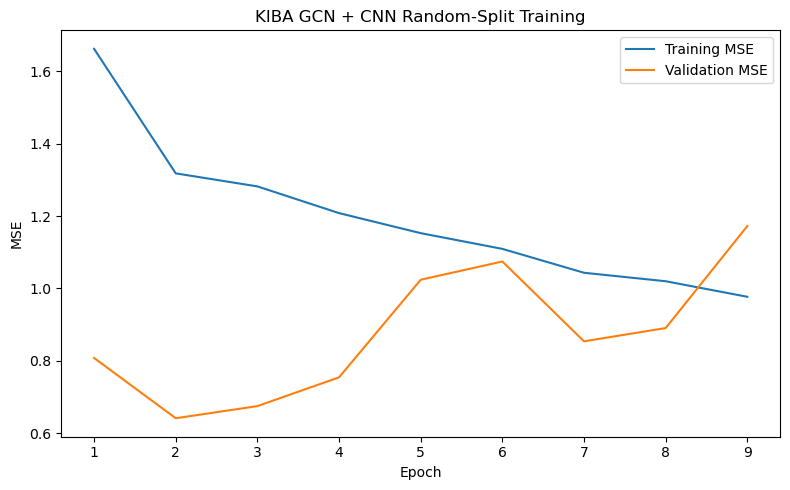

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gcn_cnn_random_history.png


In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gcn_random_history["epoch"],
    kiba_gcn_random_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    kiba_gcn_random_history["epoch"],
    kiba_gcn_random_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(
    "KIBA GCN + CNN Random-Split Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gcn_random_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gcn_random_history_plot_path)

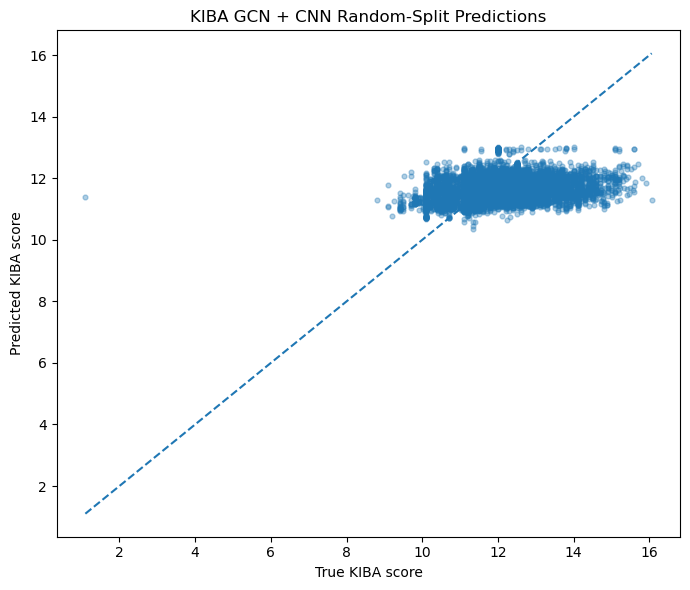

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gcn_cnn_random_predictions.png


In [60]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gcn_random_true_values,
    kiba_gcn_random_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gcn_random_true_values.min(),
    kiba_gcn_random_predicted_values.min(),
)

maximum_value = max(
    kiba_gcn_random_true_values.max(),
    kiba_gcn_random_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")
plt.title(
    "KIBA GCN + CNN Random-Split Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gcn_random_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gcn_random_scatter_plot_path)

In [61]:
kiba_gcn_random_outputs = [
    kiba_gcn_random_checkpoint,
    kiba_gcn_random_history_path,
    kiba_gcn_random_metrics_path,
    kiba_gcn_random_predictions_path,
    kiba_gcn_random_history_plot_path,
    kiba_gcn_random_scatter_plot_path,
]

for output_path in kiba_gcn_random_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in kiba_gcn_random_outputs
)

print()
print(
    "KIBA GCN + CNN random-split "
    "experiment completed successfully."
)

best_kiba_gcn_cnn_random.pt → True
kiba_gcn_cnn_random_history.csv → True
kiba_gcn_cnn_random_metrics.json → True
kiba_gcn_cnn_random_predictions.csv → True
kiba_gcn_cnn_random_history.png → True
kiba_gcn_cnn_random_predictions.png → True

KIBA GCN + CNN random-split experiment completed successfully.


## KIBA Random Split — GAT + CNN

A fresh GAT + CNN model is trained using the same KIBA random split and training settings used for GCN + CNN.

This ensures a fair comparison between the two drug graph encoders.

# Clear the previous model from memory

In [62]:
import gc

objects_to_remove = [
    "kiba_gcn_random_model",
    "kiba_gcn_random_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GCN training objects removed.")

Previous GCN training objects removed.


# Define GAT output paths

In [63]:
kiba_gat_random_checkpoint = (
    MODELS_DIR
    / "best_kiba_gat_cnn_random.pt"
)

kiba_gat_random_history_path = (
    METRICS_DIR
    / "kiba_gat_cnn_random_history.csv"
)

kiba_gat_random_metrics_path = (
    METRICS_DIR
    / "kiba_gat_cnn_random_metrics.json"
)

kiba_gat_random_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gat_cnn_random_predictions.csv"
)

kiba_gat_random_history_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_random_history.png"
)

kiba_gat_random_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_random_predictions.png"
)

print("Checkpoint:")
print(kiba_gat_random_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_cnn_random.pt


# Create a fresh GAT + CNN model

In [64]:
set_random_seed(RANDOM_SEED)

kiba_gat_random_model = create_dta_model(
    model_name="gat"
).to(device)

kiba_gat_random_optimizer = torch.optim.Adam(
    kiba_gat_random_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gat_random_parameter_count = (
    count_trainable_parameters(
        kiba_gat_random_model
    )
)

print("Model: GAT + CNN")
print("Dataset: KIBA")
print("Split: random")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gat_random_parameter_count:,}",
)

Model: GAT + CNN
Dataset: KIBA
Split: random
Device: mps
Trainable parameters: 300,033


In [65]:
gat_verification_batch = next(
    iter(kiba_random_train_loader)
).to(device)

kiba_gat_random_model.eval()

with torch.no_grad():
    gat_verification_predictions = (
        kiba_gat_random_model(
            gat_verification_batch
        )
        .view(-1)
    )

print(
    "Prediction shape:",
    gat_verification_predictions.shape,
)

print(
    "True-value shape:",
    gat_verification_batch.y.view(-1).shape,
)

assert gat_verification_predictions.shape == (
    gat_verification_batch.y.view(-1).shape
)

assert torch.isfinite(
    gat_verification_predictions
).all()

del gat_verification_batch
del gat_verification_predictions

if device.type == "mps":
    torch.mps.empty_cache()

print("Fresh KIBA GAT model verified.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
Fresh KIBA GAT model verified.


# Train GAT + CNN

In [66]:
kiba_gat_random_start_time = time.perf_counter()

kiba_gat_random_result = fit_model(
    model=kiba_gat_random_model,
    train_loader=kiba_random_train_loader,
    validation_loader=kiba_random_validation_loader,
    optimizer=kiba_gat_random_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=kiba_gat_random_checkpoint,
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gat_random_end_time = time.perf_counter()

kiba_gat_random_runtime_minutes = (
    kiba_gat_random_end_time
    - kiba_gat_random_start_time
) / 60

print()
print(
    "Total training time:",
    round(kiba_gat_random_runtime_minutes, 2),
    "minutes",
)

Epoch 001 | Train MSE: 1.6945 | Validation MSE: 0.7649 | RMSE: 0.8746 | MAE: 0.5671
Epoch 002 | Train MSE: 1.3089 | Validation MSE: 0.8043 | RMSE: 0.8968 | MAE: 0.5827
Epoch 003 | Train MSE: 1.2385 | Validation MSE: 0.6424 | RMSE: 0.8015 | MAE: 0.5841
Epoch 004 | Train MSE: 1.1627 | Validation MSE: 0.6562 | RMSE: 0.8100 | MAE: 0.6127
Epoch 005 | Train MSE: 1.1078 | Validation MSE: 0.6456 | RMSE: 0.8035 | MAE: 0.5056
Epoch 006 | Train MSE: 1.0459 | Validation MSE: 0.6291 | RMSE: 0.7932 | MAE: 0.5006
Epoch 007 | Train MSE: 0.9720 | Validation MSE: 0.6132 | RMSE: 0.7831 | MAE: 0.5057
Epoch 008 | Train MSE: 0.9344 | Validation MSE: 0.5884 | RMSE: 0.7671 | MAE: 0.5053
Epoch 009 | Train MSE: 0.8914 | Validation MSE: 0.6433 | RMSE: 0.8020 | MAE: 0.4976
Epoch 010 | Train MSE: 0.8414 | Validation MSE: 0.5801 | RMSE: 0.7617 | MAE: 0.4932
Epoch 011 | Train MSE: 0.8179 | Validation MSE: 0.5671 | RMSE: 0.7531 | MAE: 0.4934
Epoch 012 | Train MSE: 0.7869 | Validation MSE: 0.6457 | RMSE: 0.8035 | MAE:

# Inspect the result

In [74]:
print(kiba_gat_random_best_mse)
print(type(kiba_gat_random_best_mse))

None
<class 'NoneType'>


In [76]:
# print(kiba_gat_random_result)
# print(kiba_gat_random_result.keys())

In [77]:
kiba_gat_random_best_mse = kiba_gat_random_result["best_validation_mse"]

KeyError: 'best_validation_mse'

In [78]:
kiba_gat_random_best_mse = kiba_gat_random_result["best_val_loss"]

KeyError: 'best_val_loss'

In [79]:
kiba_gat_random_best_mse = kiba_gat_random_result.get("best_val_mse")

if kiba_gat_random_best_mse is not None:
    print(
        "Best validation MSE:",
        round(float(kiba_gat_random_best_mse), 4),
    )
else:
    print("Error: best validation MSE was not returned by fit_model().")

Error: best validation MSE was not returned by fit_model().


In [81]:
kiba_gat_random_best_mse = (
    kiba_gat_random_result["best_validation_metrics"]["mse"]
)

print(
    "Best validation MSE:",
    round(float(kiba_gat_random_best_mse), 4),
)

Best validation MSE: 0.4587


In [80]:
print(kiba_gat_random_result)

{'model': DTAModel(
  (drug_encoder): DrugGATEncoder(
    (conv1): GATConv(6, 32, heads=4)
    (conv2): GATConv(128, 32, heads=4)
    (conv3): GATConv(128, 128, heads=1)
  )
  (protein_encoder): ProteinCNNEncoder(
    (embedding): Embedding(21, 128, padding_idx=0)
    (conv1): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,))
    (conv2): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,))
    (pool): AdaptiveMaxPool1d(output_size=1)
  )
  (fusion): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
), 'history': {'epoch': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30], 'train_mse': [1.69452595900995, 1.3088718987842483, 1.2384975594675376, 1.1627404298413042, 1.1077838803865043, 1.0458685434012782, 0.9719864442657041, 0.9343746596648734, 0.8913574316851366, 0.

In [82]:
from pathlib import Path

# Extract the nested best validation metrics safely
best_validation_metrics = kiba_gat_random_result.get(
    "best_validation_metrics",
    {},
)

# Create the key expected by the next cell
if kiba_gat_random_result.get("best_validation_mse") is None:
    kiba_gat_random_result["best_validation_mse"] = (
        best_validation_metrics.get("mse")
    )

# Alternative compatibility key
if kiba_gat_random_result.get("best_val_mse") is None:
    kiba_gat_random_result["best_val_mse"] = (
        best_validation_metrics.get("mse")
    )

# Create checkpoint Path object
kiba_gat_random_checkpoint = Path(
    kiba_gat_random_result["checkpoint_path"]
)

# Validate that the required value exists
if kiba_gat_random_result["best_validation_mse"] is None:
    raise ValueError(
        "MSE was not found inside "
        "kiba_gat_random_result['best_validation_metrics']."
    )

print("Helper variables prepared successfully.")

Helper variables prepared successfully.


In [83]:
print(
    "Available result keys:",
    kiba_gat_random_result.keys(),
)

kiba_gat_random_best_mse = (
    kiba_gat_random_result.get(
        "best_validation_mse"
    )
)

if kiba_gat_random_best_mse is None:
    kiba_gat_random_best_mse = (
        kiba_gat_random_result.get(
            "best_val_mse"
        )
    )

print(
    "Best epoch:",
    kiba_gat_random_result["best_epoch"],
)

print(
    "Best validation MSE:",
    round(
        float(kiba_gat_random_best_mse),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gat_random_result["history"]),
)

print(
    "Checkpoint exists:",
    kiba_gat_random_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path', 'best_validation_mse', 'best_val_mse'])
Best epoch: 27
Best validation MSE: 0.4587
Completed epochs: 7
Checkpoint exists: True


# Save the training history

In [84]:
kiba_gat_random_history = pd.DataFrame(
    kiba_gat_random_result["history"]
)

display(
    kiba_gat_random_history.tail()
)

kiba_gat_random_history.to_csv(
    kiba_gat_random_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gat_random_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.569631,0.497487,0.705328,0.462077,0.724486,0.577450
26,27,0.560590,0.458653,0.677239,0.474281,0.733408,0.597791
27,28,0.549098,0.463916,0.681114,0.488037,0.731700,0.600910
28,29,0.546595,0.485986,0.697127,0.451891,0.728016,0.593057
29,30,0.533540,0.550866,0.742204,0.574571,0.732214,0.606190


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_cnn_random_history.csv


# Load the best GAT checkpoint

In [85]:
load_checkpoint(
    model=kiba_gat_random_model,
    checkpoint_path=kiba_gat_random_checkpoint,
    device=device,
)

kiba_gat_random_model.eval()

print("Best KIBA GAT checkpoint loaded.")

Best KIBA GAT checkpoint loaded.


# Evaluate on the test set

In [86]:
kiba_gat_random_metrics = evaluate_model(
    model=kiba_gat_random_model,
    data_loader=kiba_random_test_loader,
    device=device,
)

print("KIBA GAT random-split test results")
print("----------------------------------")

for metric_name, metric_value in (
    kiba_gat_random_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GAT random-split test results
----------------------------------
mse : 0.457
rmse : 0.676
mae : 0.476
concordance_index : 0.7295
pearson_correlation : 0.5918


# Save the metrics

In [87]:
kiba_gat_random_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gat_random_metrics.items()
}

kiba_gat_random_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GAT + CNN",
        "model_name": "gat",
        "split_type": "random",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gat_random_result[
                "best_epoch"
            ]
        ),
        "best_validation_mse": float(
            kiba_gat_random_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gat_random_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gat_random_parameter_count
        ),
    }
)

with open(
    kiba_gat_random_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gat_random_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gat_random_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_cnn_random_metrics.json


# Generate GAT test predictions

In [88]:
kiba_gat_random_true_values = []
kiba_gat_random_predicted_values = []

kiba_gat_random_model.eval()

with torch.no_grad():
    for batch in kiba_random_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gat_random_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gat_random_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gat_random_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gat_random_true_values = np.asarray(
    kiba_gat_random_true_values
)

kiba_gat_random_predicted_values = np.asarray(
    kiba_gat_random_predicted_values
)

print(
    "True values:",
    kiba_gat_random_true_values.shape,
)

print(
    "Predictions:",
    kiba_gat_random_predicted_values.shape,
)

assert len(kiba_gat_random_true_values) == len(
    kiba_random_test_df
)

assert len(
    kiba_gat_random_predicted_values
) == len(
    kiba_random_test_df
)

True values: (17739,)
Predictions: (17739,)


# Save the prediction table

In [89]:
kiba_gat_random_predictions_df = (
    kiba_random_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gat_random_predictions_df[
    "true_affinity"
] = kiba_gat_random_true_values

kiba_gat_random_predictions_df[
    "predicted_affinity"
] = kiba_gat_random_predicted_values

kiba_gat_random_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gat_random_predictions_df[
        "true_affinity"
    ]
    - kiba_gat_random_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gat_random_predictions_df.to_csv(
    kiba_gat_random_predictions_path,
    index=False,
)

display(
    kiba_gat_random_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gat_random_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL2001923,Q14012,C1COCCN1C2=CC=C(C=C2)OCCC3=CC4=C(C=C3)NC5=C(C=...,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLV...,11.200000,11.200000,KIBA_score,11.200000,11.331629,0.131629
1,kiba,CHEMBL248757,O75676,C1CCOC2=NC(=CN=C2C#N)NC(=O)NC3=CC(=C(C=C3OC1)N...,MGDEDDDESCAVELRITEANLTGHEEKVSVENFELLKVLGTGAYGK...,12.122734,12.122734,KIBA_score,12.122734,11.575705,0.547029
2,kiba,CHEMBL1993781,P51817,C1=CC=C(C=C1)COCC(COC2=CN=CC(=C2)C=CC3=CC=NC=C3)N,MEAPGLAQAAAAESDSRKVAEETPDGAPALCPSPEALSPEPPVYSL...,13.800057,13.800057,KIBA_score,13.800057,11.996363,1.803695
3,kiba,CHEMBL1998585,P05129,C1=CC(=CC=C1C2=CSC3=NC=NC(=C23)N)NC(=O)NC4=C(C...,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,11.200000,11.200000,KIBA_score,11.200000,11.670095,0.470096
4,kiba,CHEMBL2005528,P29317,CCOC(=O)C1=CC2=C(C=C1)NC3=C2CCNC3=O,MELQAARACFALLWGCALAAAAAAQGKEVVLLDFAAAGGELGWLTH...,11.600000,11.600000,KIBA_score,11.599999,11.410142,0.189857


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gat_cnn_random_predictions.csv


# Plot the training history

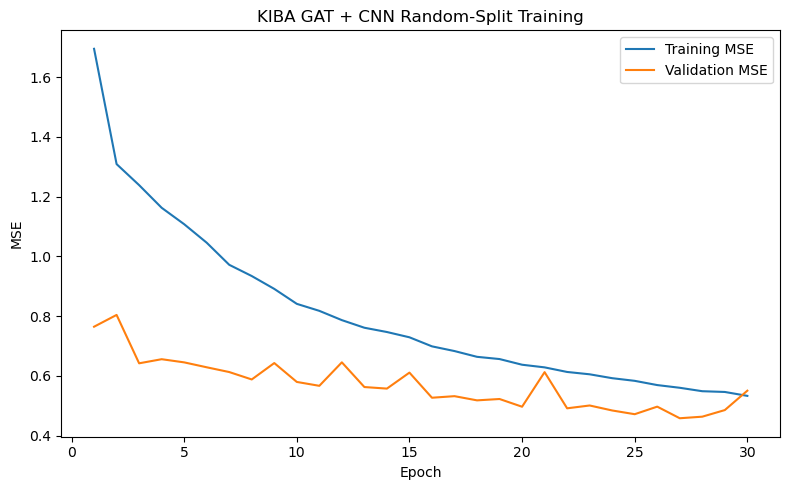

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_cnn_random_history.png


In [90]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gat_random_history["epoch"],
    kiba_gat_random_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    kiba_gat_random_history["epoch"],
    kiba_gat_random_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(
    "KIBA GAT + CNN Random-Split Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gat_random_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gat_random_history_plot_path)

# Plot predicted versus true KIBA scores

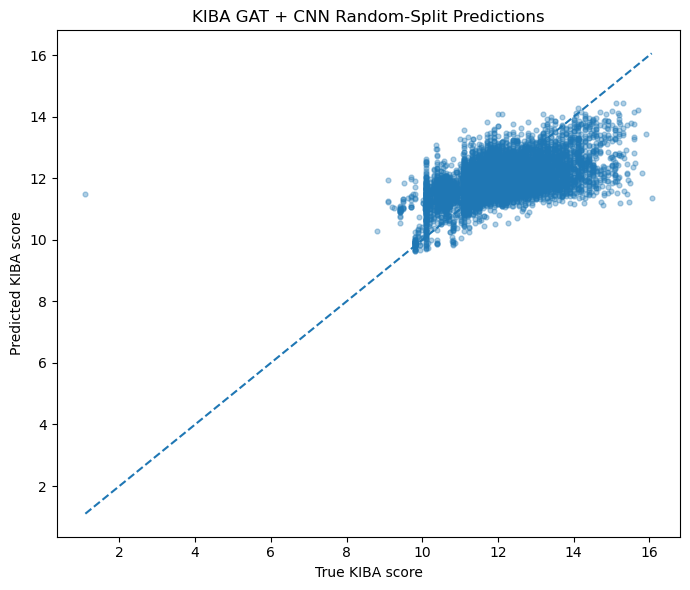

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_cnn_random_predictions.png


In [91]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gat_random_true_values,
    kiba_gat_random_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gat_random_true_values.min(),
    kiba_gat_random_predicted_values.min(),
)

maximum_value = max(
    kiba_gat_random_true_values.max(),
    kiba_gat_random_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")
plt.title(
    "KIBA GAT + CNN Random-Split Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gat_random_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gat_random_scatter_plot_path)

# Confirm all GAT outputs

In [92]:
kiba_gat_random_outputs = [
    kiba_gat_random_checkpoint,
    kiba_gat_random_history_path,
    kiba_gat_random_metrics_path,
    kiba_gat_random_predictions_path,
    kiba_gat_random_history_plot_path,
    kiba_gat_random_scatter_plot_path,
]

for output_path in kiba_gat_random_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in kiba_gat_random_outputs
)

print()
print(
    "KIBA GAT + CNN random-split "
    "experiment completed successfully."
)

best_kiba_gat_cnn_random.pt → True
kiba_gat_cnn_random_history.csv → True
kiba_gat_cnn_random_metrics.json → True
kiba_gat_cnn_random_predictions.csv → True
kiba_gat_cnn_random_history.png → True
kiba_gat_cnn_random_predictions.png → True

KIBA GAT + CNN random-split experiment completed successfully.


### KIBA GAT Random-Split Experiment Complete

The GAT + CNN model was trained and evaluated using the same KIBA random split as the GCN + CNN model.

The next experiment will train GIN + CNN before comparing all three random-split models.

## KIBA Random Split — GIN + CNN

A fresh GIN + CNN model is trained using the same KIBA random split and training configuration used for the GCN and GAT models.

This completes the three-model KIBA random-split experiment.

# Clear the previous GAT model

In [93]:
objects_to_remove = [
    "kiba_gat_random_model",
    "kiba_gat_random_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GAT training objects removed.")

Previous GAT training objects removed.


# Define GIN output paths

In [94]:
kiba_gin_random_checkpoint = (
    MODELS_DIR
    / "best_kiba_gin_cnn_random.pt"
)

kiba_gin_random_history_path = (
    METRICS_DIR
    / "kiba_gin_cnn_random_history.csv"
)

kiba_gin_random_metrics_path = (
    METRICS_DIR
    / "kiba_gin_cnn_random_metrics.json"
)

kiba_gin_random_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gin_cnn_random_predictions.csv"
)

kiba_gin_random_history_plot_path = (
    PLOTS_DIR
    / "kiba_gin_cnn_random_history.png"
)

kiba_gin_random_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gin_cnn_random_predictions.png"
)

print("Checkpoint:")
print(kiba_gin_random_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gin_cnn_random.pt


# Create a fresh GIN + CNN model

In [95]:
set_random_seed(RANDOM_SEED)

kiba_gin_random_model = create_dta_model(
    model_name="gin"
).to(device)

kiba_gin_random_optimizer = torch.optim.Adam(
    kiba_gin_random_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gin_random_parameter_count = (
    count_trainable_parameters(
        kiba_gin_random_model
    )
)

print("Model: GIN + CNN")
print("Dataset: KIBA")
print("Split: random")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gin_random_parameter_count:,}",
)

Model: GIN + CNN
Dataset: KIBA
Split: random
Device: mps
Trainable parameters: 348,801


# Test one forward pass

In [96]:
gin_verification_batch = next(
    iter(kiba_random_train_loader)
).to(device)

kiba_gin_random_model.eval()

with torch.no_grad():
    gin_verification_predictions = (
        kiba_gin_random_model(
            gin_verification_batch
        )
        .view(-1)
    )

print(
    "Prediction shape:",
    gin_verification_predictions.shape,
)

print(
    "True-value shape:",
    gin_verification_batch.y.view(-1).shape,
)

assert gin_verification_predictions.shape == (
    gin_verification_batch.y.view(-1).shape
)

assert torch.isfinite(
    gin_verification_predictions
).all()

del gin_verification_batch
del gin_verification_predictions

if device.type == "mps":
    torch.mps.empty_cache()

print("Fresh KIBA GIN model verified.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
Fresh KIBA GIN model verified.


# Train GIN + CNN

In [97]:
kiba_gin_random_start_time = time.perf_counter()

kiba_gin_random_result = fit_model(
    model=kiba_gin_random_model,
    train_loader=kiba_random_train_loader,
    validation_loader=kiba_random_validation_loader,
    optimizer=kiba_gin_random_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=kiba_gin_random_checkpoint,
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gin_random_end_time = time.perf_counter()

kiba_gin_random_runtime_minutes = (
    kiba_gin_random_end_time
    - kiba_gin_random_start_time
) / 60

print()
print(
    "Total training time:",
    round(kiba_gin_random_runtime_minutes, 2),
    "minutes",
)

Epoch 001 | Train MSE: 1.8027 | Validation MSE: 0.6567 | RMSE: 0.8104 | MAE: 0.5945
Epoch 002 | Train MSE: 1.4596 | Validation MSE: 1.4952 | RMSE: 1.2228 | MAE: 0.9749
Epoch 003 | Train MSE: 1.3741 | Validation MSE: 0.9063 | RMSE: 0.9520 | MAE: 0.6539
Epoch 004 | Train MSE: 1.3182 | Validation MSE: 0.6500 | RMSE: 0.8062 | MAE: 0.5258
Epoch 005 | Train MSE: 1.2456 | Validation MSE: 1.2115 | RMSE: 1.1007 | MAE: 0.8463
Epoch 006 | Train MSE: 1.1762 | Validation MSE: 1.0911 | RMSE: 1.0446 | MAE: 0.7763
Epoch 007 | Train MSE: 1.0999 | Validation MSE: 1.5740 | RMSE: 1.2546 | MAE: 1.0235
Epoch 008 | Train MSE: 1.0516 | Validation MSE: 1.3308 | RMSE: 1.1536 | MAE: 0.9135
Epoch 009 | Train MSE: 0.9870 | Validation MSE: 0.5922 | RMSE: 0.7695 | MAE: 0.5012
Epoch 010 | Train MSE: 0.9289 | Validation MSE: 0.6534 | RMSE: 0.8083 | MAE: 0.5205
Epoch 011 | Train MSE: 0.8760 | Validation MSE: 0.6671 | RMSE: 0.8168 | MAE: 0.5164
Epoch 012 | Train MSE: 0.8317 | Validation MSE: 0.6371 | RMSE: 0.7982 | MAE:

# Inspect the training result

In [102]:
from pathlib import Path

# Extract nested best validation metrics
best_validation_metrics = kiba_gin_random_result.get(
    "best_validation_metrics",
    {},
)

# Create the keys expected by the next cell
if kiba_gin_random_result.get("best_validation_mse") is None:
    kiba_gin_random_result["best_validation_mse"] = (
        best_validation_metrics.get("mse")
    )

if kiba_gin_random_result.get("best_val_mse") is None:
    kiba_gin_random_result["best_val_mse"] = (
        best_validation_metrics.get("mse")
    )

# Create checkpoint Path object
kiba_gin_random_checkpoint = Path(
    kiba_gin_random_result["checkpoint_path"]
)

# Confirm the MSE was found
if kiba_gin_random_result["best_validation_mse"] is None:
    raise ValueError(
        "MSE was not found inside "
        "kiba_gin_random_result['best_validation_metrics']."
    )

print("KIBA GIN random helper variables prepared successfully.")

KIBA GIN random helper variables prepared successfully.


In [103]:
print(
    "Available result keys:",
    kiba_gin_random_result.keys(),
)

kiba_gin_random_best_mse = (
    kiba_gin_random_result.get(
        "best_validation_mse"
    )
)

if kiba_gin_random_best_mse is None:
    kiba_gin_random_best_mse = (
        kiba_gin_random_result.get(
            "best_val_mse"
        )
    )

print(
    "Best epoch:",
    kiba_gin_random_result["best_epoch"],
)

print(
    "Best validation MSE:",
    round(
        float(kiba_gin_random_best_mse),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gin_random_result["history"]),
)

print(
    "Checkpoint exists:",
    kiba_gin_random_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path', 'best_validation_mse', 'best_val_mse'])
Best epoch: 30
Best validation MSE: 0.5023
Completed epochs: 7
Checkpoint exists: True


# Save the training history

In [104]:
kiba_gin_random_history = pd.DataFrame(
    kiba_gin_random_result["history"]
)

display(
    kiba_gin_random_history.tail()
)

kiba_gin_random_history.to_csv(
    kiba_gin_random_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gin_random_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.580253,0.520378,0.721372,0.464639,0.712037,0.530859
26,27,0.573551,0.516225,0.718488,0.474927,0.710875,0.517605
27,28,0.567537,0.546331,0.739142,0.466146,0.710287,0.526358
28,29,0.564847,0.518128,0.719811,0.472327,0.708949,0.526558
29,30,0.558693,0.502294,0.708727,0.470896,0.716051,0.537061


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gin_cnn_random_history.csv


# Load the best checkpoint

In [105]:
load_checkpoint(
    model=kiba_gin_random_model,
    checkpoint_path=kiba_gin_random_checkpoint,
    device=device,
)

kiba_gin_random_model.eval()

print("Best KIBA GIN checkpoint loaded.")

Best KIBA GIN checkpoint loaded.


# Evaluate on the test set

In [106]:
kiba_gin_random_metrics = evaluate_model(
    model=kiba_gin_random_model,
    data_loader=kiba_random_test_loader,
    device=device,
)

print("KIBA GIN random-split test results")
print("----------------------------------")

for metric_name, metric_value in (
    kiba_gin_random_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GIN random-split test results
----------------------------------
mse : 0.4955
rmse : 0.7039
mae : 0.4705
concordance_index : 0.7136
pearson_correlation : 0.5354


# Save the metrics

In [107]:
kiba_gin_random_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gin_random_metrics.items()
}

kiba_gin_random_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GIN + CNN",
        "model_name": "gin",
        "split_type": "random",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gin_random_result[
                "best_epoch"
            ]
        ),
        "best_validation_mse": float(
            kiba_gin_random_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gin_random_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gin_random_parameter_count
        ),
    }
)

with open(
    kiba_gin_random_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gin_random_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gin_random_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gin_cnn_random_metrics.json


# Generate test predictions

In [108]:
kiba_gin_random_true_values = []
kiba_gin_random_predicted_values = []

kiba_gin_random_model.eval()

with torch.no_grad():
    for batch in kiba_random_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gin_random_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gin_random_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gin_random_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gin_random_true_values = np.asarray(
    kiba_gin_random_true_values
)

kiba_gin_random_predicted_values = np.asarray(
    kiba_gin_random_predicted_values
)

print(
    "True values:",
    kiba_gin_random_true_values.shape,
)

print(
    "Predictions:",
    kiba_gin_random_predicted_values.shape,
)

assert len(kiba_gin_random_true_values) == len(
    kiba_random_test_df
)

assert len(
    kiba_gin_random_predicted_values
) == len(
    kiba_random_test_df
)

True values: (17739,)
Predictions: (17739,)


# Save the prediction table

In [109]:
kiba_gin_random_predictions_df = (
    kiba_random_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gin_random_predictions_df[
    "true_affinity"
] = kiba_gin_random_true_values

kiba_gin_random_predictions_df[
    "predicted_affinity"
] = kiba_gin_random_predicted_values

kiba_gin_random_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gin_random_predictions_df[
        "true_affinity"
    ]
    - kiba_gin_random_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gin_random_predictions_df.to_csv(
    kiba_gin_random_predictions_path,
    index=False,
)

display(
    kiba_gin_random_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gin_random_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL2001923,Q14012,C1COCCN1C2=CC=C(C=C2)OCCC3=CC4=C(C=C3)NC5=C(C=...,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLV...,11.200000,11.200000,KIBA_score,11.200000,11.385678,0.185678
1,kiba,CHEMBL248757,O75676,C1CCOC2=NC(=CN=C2C#N)NC(=O)NC3=CC(=C(C=C3OC1)N...,MGDEDDDESCAVELRITEANLTGHEEKVSVENFELLKVLGTGAYGK...,12.122734,12.122734,KIBA_score,12.122734,11.686192,0.436543
2,kiba,CHEMBL1993781,P51817,C1=CC=C(C=C1)COCC(COC2=CN=CC(=C2)C=CC3=CC=NC=C3)N,MEAPGLAQAAAAESDSRKVAEETPDGAPALCPSPEALSPEPPVYSL...,13.800057,13.800057,KIBA_score,13.800057,11.850730,1.949327
3,kiba,CHEMBL1998585,P05129,C1=CC(=CC=C1C2=CSC3=NC=NC(=C23)N)NC(=O)NC4=C(C...,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,11.200000,11.200000,KIBA_score,11.200000,11.456385,0.256385
4,kiba,CHEMBL2005528,P29317,CCOC(=O)C1=CC2=C(C=C1)NC3=C2CCNC3=O,MELQAARACFALLWGCALAAAAAAQGKEVVLLDFAAAGGELGWLTH...,11.600000,11.600000,KIBA_score,11.599999,11.564306,0.035693


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gin_cnn_random_predictions.csv


# Plot the training history

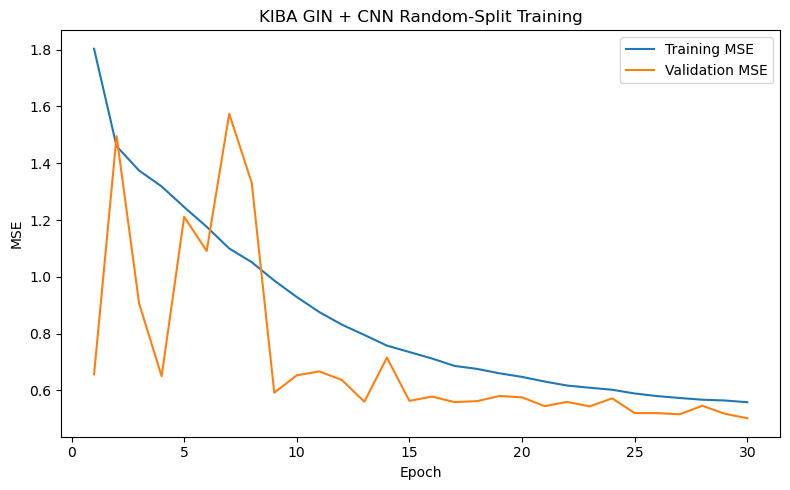

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gin_cnn_random_history.png


In [110]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gin_random_history["epoch"],
    kiba_gin_random_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    kiba_gin_random_history["epoch"],
    kiba_gin_random_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(
    "KIBA GIN + CNN Random-Split Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gin_random_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gin_random_history_plot_path)

# Plot predicted versus true KIBA scores

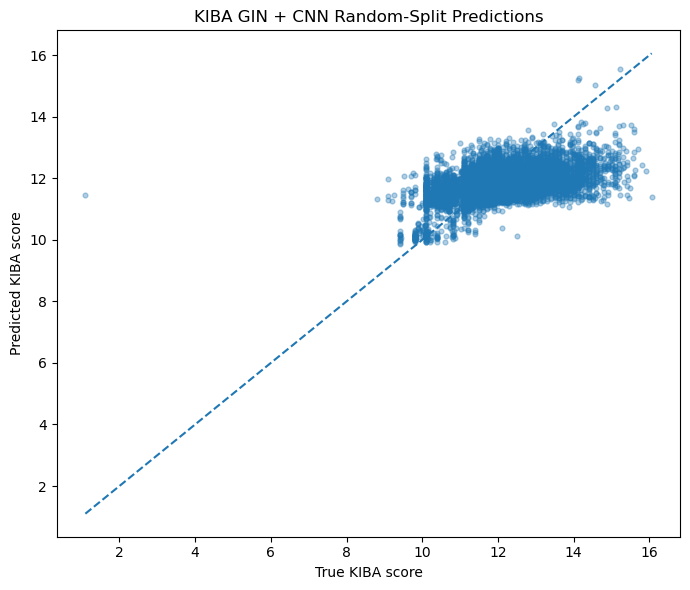

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gin_cnn_random_predictions.png


In [111]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gin_random_true_values,
    kiba_gin_random_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gin_random_true_values.min(),
    kiba_gin_random_predicted_values.min(),
)

maximum_value = max(
    kiba_gin_random_true_values.max(),
    kiba_gin_random_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")
plt.title(
    "KIBA GIN + CNN Random-Split Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gin_random_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gin_random_scatter_plot_path)

# Confirm all outputs

In [112]:
kiba_gin_random_outputs = [
    kiba_gin_random_checkpoint,
    kiba_gin_random_history_path,
    kiba_gin_random_metrics_path,
    kiba_gin_random_predictions_path,
    kiba_gin_random_history_plot_path,
    kiba_gin_random_scatter_plot_path,
]

for output_path in kiba_gin_random_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in kiba_gin_random_outputs
)

print()
print(
    "KIBA GIN + CNN random-split "
    "experiment completed successfully."
)

best_kiba_gin_cnn_random.pt → True
kiba_gin_cnn_random_history.csv → True
kiba_gin_cnn_random_metrics.json → True
kiba_gin_cnn_random_predictions.csv → True
kiba_gin_cnn_random_history.png → True
kiba_gin_cnn_random_predictions.png → True

KIBA GIN + CNN random-split experiment completed successfully.


### KIBA Random-Split Training Complete

GCN + CNN, GAT + CNN and GIN + CNN were trained and evaluated using the same KIBA random split.

The next section will compare the three models using validation performance and held-out test metrics.

## KIBA Random-Split Model Comparison

This section compares:

- GCN + CNN
- GAT + CNN
- GIN + CNN

All three models used the same KIBA random split, random seed and training configuration.

The preliminary winner is selected using the lowest validation MSE. Test metrics are used only for final reporting.

# Load the saved metric files

In [113]:
def load_metrics_json(file_path):
    with open(
        file_path,
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


kiba_gcn_random_saved_metrics = load_metrics_json(
    METRICS_DIR
    / "kiba_gcn_cnn_random_metrics.json"
)

kiba_gat_random_saved_metrics = load_metrics_json(
    METRICS_DIR
    / "kiba_gat_cnn_random_metrics.json"
)

kiba_gin_random_saved_metrics = load_metrics_json(
    METRICS_DIR
    / "kiba_gin_cnn_random_metrics.json"
)

print("GCN metrics loaded:", bool(kiba_gcn_random_saved_metrics))
print("GAT metrics loaded:", bool(kiba_gat_random_saved_metrics))
print("GIN metrics loaded:", bool(kiba_gin_random_saved_metrics))

GCN metrics loaded: True
GAT metrics loaded: True
GIN metrics loaded: True


# Inspect the available metric keys

In [114]:
print(
    "GCN keys:",
    kiba_gcn_random_saved_metrics.keys(),
)

print(
    "GAT keys:",
    kiba_gat_random_saved_metrics.keys(),
)

print(
    "GIN keys:",
    kiba_gin_random_saved_metrics.keys(),
)

GCN keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'training_runtime_minutes', 'trainable_parameters'])
GAT keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])
GIN keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])


# Create the comparison table

In [116]:
def get_experiment_summary(
    saved_metrics,
    history_path,
):
    history_df = pd.read_csv(history_path)

    # Support both possible validation column names.
    if "validation_mse" in history_df.columns:
        validation_column = "validation_mse"
    elif "val_mse" in history_df.columns:
        validation_column = "val_mse"
    else:
        raise KeyError(
            "No validation MSE column found in "
            f"{history_path.name}. "
            f"Available columns: {history_df.columns.tolist()}"
        )

    best_row_index = history_df[
        validation_column
    ].idxmin()

    best_validation_mse = saved_metrics.get(
        "best_validation_mse"
    )

    if best_validation_mse is None:
        best_validation_mse = saved_metrics.get(
            "best_val_mse"
        )

    if best_validation_mse is None:
        best_validation_mse = float(
            history_df.loc[
                best_row_index,
                validation_column,
            ]
        )

    best_epoch = saved_metrics.get(
        "best_epoch"
    )

    if best_epoch is None:
        best_epoch = int(
            history_df.loc[
                best_row_index,
                "epoch",
            ]
        )

    return {
        "best_epoch": int(best_epoch),
        "best_validation_mse": float(
            best_validation_mse
        ),
    }


kiba_gcn_random_summary = get_experiment_summary(
    saved_metrics=kiba_gcn_random_saved_metrics,
    history_path=(
        METRICS_DIR
        / "kiba_gcn_cnn_random_history.csv"
    ),
)

kiba_gat_random_summary = get_experiment_summary(
    saved_metrics=kiba_gat_random_saved_metrics,
    history_path=(
        METRICS_DIR
        / "kiba_gat_cnn_random_history.csv"
    ),
)

kiba_gin_random_summary = get_experiment_summary(
    saved_metrics=kiba_gin_random_saved_metrics,
    history_path=(
        METRICS_DIR
        / "kiba_gin_cnn_random_history.csv"
    ),
)


kiba_random_comparison_df = pd.DataFrame(
    [
        {
            "model": "GCN + CNN",
            "model_name": "gcn",
            "split_type": "random",
            "best_epoch": (
                kiba_gcn_random_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gcn_random_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gcn_random_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gcn_random_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gcn_random_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gcn_random_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gcn_random_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gcn_random_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gcn_random_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
        {
            "model": "GAT + CNN",
            "model_name": "gat",
            "split_type": "random",
            "best_epoch": (
                kiba_gat_random_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gat_random_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gat_random_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gat_random_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gat_random_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gat_random_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gat_random_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gat_random_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gat_random_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
        {
            "model": "GIN + CNN",
            "model_name": "gin",
            "split_type": "random",
            "best_epoch": (
                kiba_gin_random_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gin_random_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gin_random_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gin_random_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gin_random_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gin_random_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gin_random_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gin_random_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gin_random_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
    ]
)

kiba_random_comparison_df = (
    kiba_random_comparison_df
    .sort_values("best_validation_mse")
    .reset_index(drop=True)
)

kiba_random_comparison_df.insert(
    0,
    "validation_rank",
    range(
        1,
        len(kiba_random_comparison_df) + 1,
    ),
)

display(
    kiba_random_comparison_df.round(4)
)

,validation_rank,model,model_name,split_type,best_epoch,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,training_runtime_minutes,trainable_parameters
0,1,GAT + CNN,gat,random,27,0.4587,0.4570,0.6760,0.4760,0.7295,0.5918,87.0637,300033
1,2,GIN + CNN,gin,random,30,0.5023,0.4955,0.7039,0.4705,0.7136,0.5354,69.3248,348801
2,3,GCN + CNN,gcn,random,2,0.6412,0.6393,0.7995,0.5167,0.6568,0.3256,24.2249,299265


# Validate the comparison table

In [117]:
required_comparison_columns = [
    "model",
    "best_validation_mse",
    "test_mse",
    "test_rmse",
    "test_mae",
    "concordance_index",
    "pearson_correlation",
]

assert len(kiba_random_comparison_df) == 3

assert all(
    column_name in kiba_random_comparison_df.columns
    for column_name in required_comparison_columns
)

assert np.isfinite(
    kiba_random_comparison_df[
        required_comparison_columns[1:]
    ].to_numpy(
        dtype=float
    )
).all()

print("KIBA random comparison table validated.")

KIBA random comparison table validated.


# Display the preliminary random-split winner

In [118]:
kiba_random_best_model = (
    kiba_random_comparison_df.iloc[0]
)

print("KIBA random-split preliminary winner")
print("------------------------------------")

print(
    "Model:",
    kiba_random_best_model["model"],
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_random_best_model[
                "best_validation_mse"
            ]
        ),
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        float(
            kiba_random_best_model[
                "test_rmse"
            ]
        ),
        4,
    ),
)

print(
    "Test MAE:",
    round(
        float(
            kiba_random_best_model[
                "test_mae"
            ]
        ),
        4,
    ),
)

print(
    "Concordance index:",
    round(
        float(
            kiba_random_best_model[
                "concordance_index"
            ]
        ),
        4,
    ),
)

print(
    "Pearson correlation:",
    round(
        float(
            kiba_random_best_model[
                "pearson_correlation"
            ]
        ),
        4,
    ),
)

KIBA random-split preliminary winner
------------------------------------
Model: GAT + CNN
Best validation MSE: 0.4587
Test RMSE: 0.676
Test MAE: 0.476
Concordance index: 0.7295
Pearson correlation: 0.5918


# Save the comparison table

In [119]:
kiba_random_comparison_path = (
    METRICS_DIR
    / "kiba_random_model_comparison.csv"
)

kiba_random_comparison_df.to_csv(
    kiba_random_comparison_path,
    index=False,
)

print("Comparison saved to:")
print(kiba_random_comparison_path)

Comparison saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_random_model_comparison.csv


# Plot test RMSE

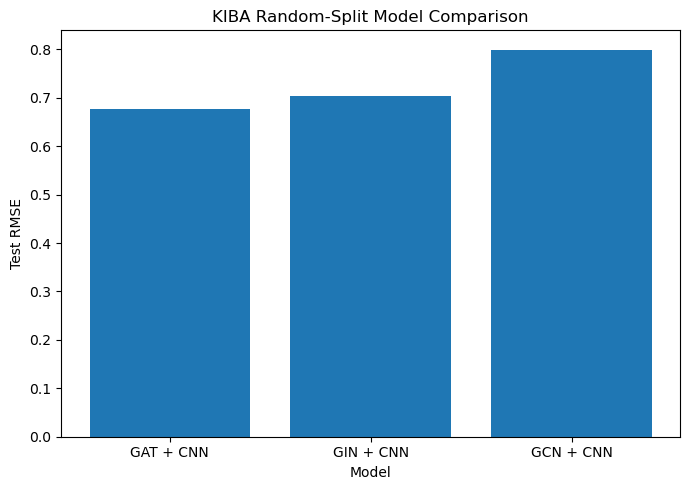

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_random_rmse_comparison.png


In [120]:
plt.figure(figsize=(7, 5))

plt.bar(
    kiba_random_comparison_df["model"],
    kiba_random_comparison_df["test_rmse"],
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")
plt.title(
    "KIBA Random-Split Model Comparison"
)

plt.tight_layout()

kiba_random_rmse_plot_path = (
    PLOTS_DIR
    / "kiba_random_rmse_comparison.png"
)

plt.savefig(
    kiba_random_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_random_rmse_plot_path)

# Plot concordance index

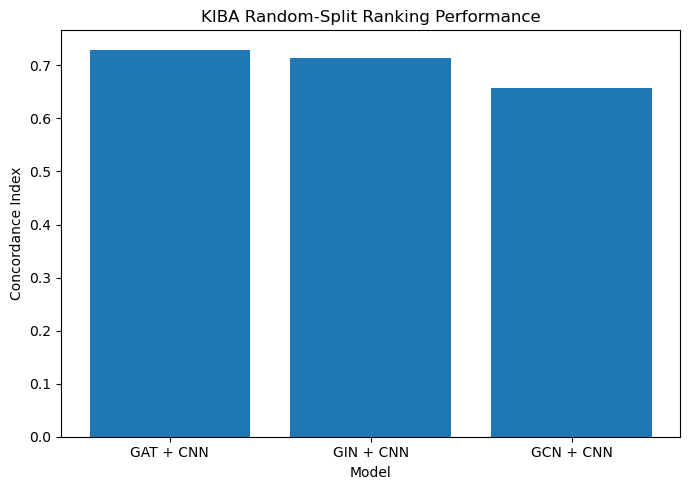

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_random_ci_comparison.png


In [121]:
plt.figure(figsize=(7, 5))

plt.bar(
    kiba_random_comparison_df["model"],
    kiba_random_comparison_df[
        "concordance_index"
    ],
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")
plt.title(
    "KIBA Random-Split Ranking Performance"
)

plt.tight_layout()

kiba_random_ci_plot_path = (
    PLOTS_DIR
    / "kiba_random_ci_comparison.png"
)

plt.savefig(
    kiba_random_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_random_ci_plot_path)

# Compare training time

In [122]:
runtime_comparison_df = (
    kiba_random_comparison_df[
        [
            "model",
            "best_epoch",
            "training_runtime_minutes",
            "trainable_parameters",
        ]
    ]
    .copy()
)

display(
    runtime_comparison_df.round(2)
)

,model,best_epoch,training_runtime_minutes,trainable_parameters
0,GAT + CNN,27,87.06,300033
1,GIN + CNN,30,69.32,348801
2,GCN + CNN,2,24.22,299265


# Confirm all outputs

In [123]:
kiba_random_comparison_outputs = [
    kiba_random_comparison_path,
    kiba_random_rmse_plot_path,
    kiba_random_ci_plot_path,
]

for output_path in (
    kiba_random_comparison_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in (
        kiba_random_comparison_outputs
    )
)

print()
print(
    "KIBA random-split model comparison "
    "completed successfully."
)

kiba_random_model_comparison.csv → True
kiba_random_rmse_comparison.png → True
kiba_random_ci_comparison.png → True

KIBA random-split model comparison completed successfully.


### KIBA Random-Split Comparison Complete

GCN + CNN, GAT + CNN and GIN + CNN were compared using the same KIBA random split.

The preliminary random-split winner was selected using validation MSE.

The next stage evaluates the three architectures using a cold-drug split, where all test drugs are unseen during training.

## KIBA Cold-Drug Evaluation

In the cold-drug split, validation and test drugs are completely absent from the training set.

This section first prepares the cold-drug DataLoaders and then trains GCN + CNN.

# Reload the cold-drug split if necessary

In [124]:
kiba_cold_drug_train_path = (
    SPLITS_DIR
    / "cold_drug"
    / "kiba_train.csv"
)

kiba_cold_drug_validation_path = (
    SPLITS_DIR
    / "cold_drug"
    / "kiba_validation.csv"
)

kiba_cold_drug_test_path = (
    SPLITS_DIR
    / "cold_drug"
    / "kiba_test.csv"
)

if "kiba_cold_drug_train_df" not in globals():
    kiba_cold_drug_train_df = pd.read_csv(
        kiba_cold_drug_train_path
    )

if "kiba_cold_drug_validation_df" not in globals():
    kiba_cold_drug_validation_df = pd.read_csv(
        kiba_cold_drug_validation_path
    )

if "kiba_cold_drug_test_df" not in globals():
    kiba_cold_drug_test_df = pd.read_csv(
        kiba_cold_drug_test_path
    )

print(
    "Training rows:",
    len(kiba_cold_drug_train_df),
)

print(
    "Validation rows:",
    len(kiba_cold_drug_validation_df),
)

print(
    "Test rows:",
    len(kiba_cold_drug_test_df),
)

Training rows: 83966
Validation rows: 17544
Test rows: 16744


# Create cold-drug datasets and DataLoaders

In [125]:
kiba_cold_drug_data = create_kiba_dataloaders(
    train_dataframe=kiba_cold_drug_train_df,
    validation_dataframe=(
        kiba_cold_drug_validation_df
    ),
    test_dataframe=kiba_cold_drug_test_df,
)

kiba_cold_drug_train_dataset = (
    kiba_cold_drug_data["train_dataset"]
)

kiba_cold_drug_validation_dataset = (
    kiba_cold_drug_data["validation_dataset"]
)

kiba_cold_drug_test_dataset = (
    kiba_cold_drug_data["test_dataset"]
)

kiba_cold_drug_train_loader = (
    kiba_cold_drug_data["train_loader"]
)

kiba_cold_drug_validation_loader = (
    kiba_cold_drug_data["validation_loader"]
)

kiba_cold_drug_test_loader = (
    kiba_cold_drug_data["test_loader"]
)

print("KIBA cold-drug DataLoaders created.")

KIBA cold-drug DataLoaders created.


# Validate the cold-drug DataLoaders

In [126]:
cold_drug_batch = next(
    iter(kiba_cold_drug_train_loader)
)

print(
    "Training samples:",
    len(kiba_cold_drug_train_dataset),
)

print(
    "Validation samples:",
    len(kiba_cold_drug_validation_dataset),
)

print(
    "Test samples:",
    len(kiba_cold_drug_test_dataset),
)

print()
print(
    "Graphs in batch:",
    cold_drug_batch.num_graphs,
)

print(
    "Protein shape:",
    cold_drug_batch.target.shape,
)

print(
    "Affinity shape:",
    cold_drug_batch.y.shape,
)

assert cold_drug_batch.x.shape[1] == 6
assert cold_drug_batch.target.shape[1] == 1000

print("Cold-drug DataLoaders verified.")

Training samples: 83966
Validation samples: 17544
Test samples: 16744

Graphs in batch: 32
Protein shape: torch.Size([32, 1000])
Affinity shape: torch.Size([32])
Cold-drug DataLoaders verified.


# Confirm that drugs do not overlap

In [127]:
cold_drug_train_ids = set(
    kiba_cold_drug_train_df[
        "drug_id"
    ].astype(str)
)

cold_drug_validation_ids = set(
    kiba_cold_drug_validation_df[
        "drug_id"
    ].astype(str)
)

cold_drug_test_ids = set(
    kiba_cold_drug_test_df[
        "drug_id"
    ].astype(str)
)

assert cold_drug_train_ids.isdisjoint(
    cold_drug_validation_ids
)

assert cold_drug_train_ids.isdisjoint(
    cold_drug_test_ids
)

assert cold_drug_validation_ids.isdisjoint(
    cold_drug_test_ids
)

print("Training drugs:", len(cold_drug_train_ids))
print(
    "Validation drugs:",
    len(cold_drug_validation_ids),
)
print("Test drugs:", len(cold_drug_test_ids))

print("No drug overlap detected.")

Training drugs: 1477
Validation drugs: 317
Test drugs: 317
No drug overlap detected.


### KIBA Cold-Drug — GCN + CNN

A fresh GCN + CNN model is trained using the KIBA cold-drug split.

The test drugs have not appeared during training.

# Clear the previous random-split model

In [128]:
objects_to_remove = [
    "kiba_gin_random_model",
    "kiba_gin_random_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous model objects removed.")

Previous model objects removed.


# Define the output paths

In [129]:
kiba_gcn_cold_drug_checkpoint = (
    MODELS_DIR
    / "best_kiba_gcn_cnn_cold_drug.pt"
)

kiba_gcn_cold_drug_history_path = (
    METRICS_DIR
    / "kiba_gcn_cnn_cold_drug_history.csv"
)

kiba_gcn_cold_drug_metrics_path = (
    METRICS_DIR
    / "kiba_gcn_cnn_cold_drug_metrics.json"
)

kiba_gcn_cold_drug_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gcn_cnn_cold_drug_predictions.csv"
)

kiba_gcn_cold_drug_history_plot_path = (
    PLOTS_DIR
    / "kiba_gcn_cnn_cold_drug_history.png"
)

kiba_gcn_cold_drug_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gcn_cnn_cold_drug_predictions.png"
)

print("Checkpoint:")
print(kiba_gcn_cold_drug_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gcn_cnn_cold_drug.pt


# Create a fresh GCN + CNN model

In [130]:
set_random_seed(RANDOM_SEED)

kiba_gcn_cold_drug_model = create_dta_model(
    model_name="gcn"
).to(device)

kiba_gcn_cold_drug_optimizer = (
    torch.optim.Adam(
        kiba_gcn_cold_drug_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
)

kiba_gcn_cold_drug_parameter_count = (
    count_trainable_parameters(
        kiba_gcn_cold_drug_model
    )
)

print("Model: GCN + CNN")
print("Dataset: KIBA")
print("Split: cold-drug")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gcn_cold_drug_parameter_count:,}",
)

Model: GCN + CNN
Dataset: KIBA
Split: cold-drug
Device: mps
Trainable parameters: 299,265


# Test one forward pass

In [131]:
gcn_cold_drug_batch = next(
    iter(kiba_cold_drug_train_loader)
).to(device)

kiba_gcn_cold_drug_model.eval()

with torch.no_grad():
    gcn_cold_drug_predictions = (
        kiba_gcn_cold_drug_model(
            gcn_cold_drug_batch
        )
        .view(-1)
    )

print(
    "Prediction shape:",
    gcn_cold_drug_predictions.shape,
)

print(
    "True-value shape:",
    gcn_cold_drug_batch.y.view(-1).shape,
)

assert gcn_cold_drug_predictions.shape == (
    gcn_cold_drug_batch.y.view(-1).shape
)

assert torch.isfinite(
    gcn_cold_drug_predictions
).all()

del gcn_cold_drug_batch
del gcn_cold_drug_predictions

if device.type == "mps":
    torch.mps.empty_cache()

print("GCN cold-drug forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GCN cold-drug forward pass successful.


# Train the model

In [132]:
kiba_gcn_cold_drug_start_time = (
    time.perf_counter()
)

kiba_gcn_cold_drug_result = fit_model(
    model=kiba_gcn_cold_drug_model,
    train_loader=kiba_cold_drug_train_loader,
    validation_loader=(
        kiba_cold_drug_validation_loader
    ),
    optimizer=kiba_gcn_cold_drug_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gcn_cold_drug_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gcn_cold_drug_end_time = (
    time.perf_counter()
)

kiba_gcn_cold_drug_runtime_minutes = (
    kiba_gcn_cold_drug_end_time
    - kiba_gcn_cold_drug_start_time
) / 60

print()
print(
    "Training time:",
    round(
        kiba_gcn_cold_drug_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.6590 | Validation MSE: 1.0154 | RMSE: 1.0077 | MAE: 0.7203
Epoch 002 | Train MSE: 1.3315 | Validation MSE: 0.7411 | RMSE: 0.8609 | MAE: 0.6780
Epoch 003 | Train MSE: 1.2644 | Validation MSE: 0.8519 | RMSE: 0.9230 | MAE: 0.7712
Epoch 004 | Train MSE: 1.2066 | Validation MSE: 0.6453 | RMSE: 0.8033 | MAE: 0.5099
Epoch 005 | Train MSE: 1.1476 | Validation MSE: 0.7796 | RMSE: 0.8829 | MAE: 0.5708
Epoch 006 | Train MSE: 1.0943 | Validation MSE: 0.8969 | RMSE: 0.9471 | MAE: 0.6393
Epoch 007 | Train MSE: 1.0491 | Validation MSE: 0.6379 | RMSE: 0.7987 | MAE: 0.5514
Epoch 008 | Train MSE: 1.0067 | Validation MSE: 0.6486 | RMSE: 0.8053 | MAE: 0.5012
Epoch 009 | Train MSE: 0.9590 | Validation MSE: 0.7300 | RMSE: 0.8544 | MAE: 0.5440
Epoch 010 | Train MSE: 0.9201 | Validation MSE: 0.8876 | RMSE: 0.9421 | MAE: 0.6446
Epoch 011 | Train MSE: 0.8884 | Validation MSE: 0.7134 | RMSE: 0.8446 | MAE: 0.5304
Epoch 012 | Train MSE: 0.8471 | Validation MSE: 0.7213 | RMSE: 0.8493 | MAE:

# Inspect the result safely

In [133]:
print(
    "Available result keys:",
    kiba_gcn_cold_drug_result.keys(),
)

kiba_gcn_cold_drug_history = pd.DataFrame(
    kiba_gcn_cold_drug_result["history"]
)

if (
    "validation_mse"
    in kiba_gcn_cold_drug_history.columns
):
    cold_drug_validation_column = (
        "validation_mse"
    )
elif (
    "val_mse"
    in kiba_gcn_cold_drug_history.columns
):
    cold_drug_validation_column = "val_mse"
else:
    raise KeyError(
        "No validation MSE column found. "
        f"Columns: "
        f"{kiba_gcn_cold_drug_history.columns.tolist()}"
    )

best_history_index = (
    kiba_gcn_cold_drug_history[
        cold_drug_validation_column
    ].idxmin()
)

kiba_gcn_cold_drug_best_mse = (
    kiba_gcn_cold_drug_result.get(
        "best_validation_mse"
    )
)

if kiba_gcn_cold_drug_best_mse is None:
    kiba_gcn_cold_drug_best_mse = (
        kiba_gcn_cold_drug_result.get(
            "best_val_mse"
        )
    )

if kiba_gcn_cold_drug_best_mse is None:
    kiba_gcn_cold_drug_best_mse = float(
        kiba_gcn_cold_drug_history.loc[
            best_history_index,
            cold_drug_validation_column,
        ]
    )

kiba_gcn_cold_drug_best_epoch = (
    kiba_gcn_cold_drug_result.get(
        "best_epoch"
    )
)

if kiba_gcn_cold_drug_best_epoch is None:
    kiba_gcn_cold_drug_best_epoch = int(
        kiba_gcn_cold_drug_history.loc[
            best_history_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gcn_cold_drug_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gcn_cold_drug_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gcn_cold_drug_history),
)

print(
    "Checkpoint exists:",
    kiba_gcn_cold_drug_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 29
Best validation MSE: 0.6043
Completed epochs: 30
Checkpoint exists: True


# Save the history

In [134]:
display(
    kiba_gcn_cold_drug_history.tail()
)

kiba_gcn_cold_drug_history.to_csv(
    kiba_gcn_cold_drug_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gcn_cold_drug_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.619505,0.607693,0.779546,0.504733,0.688278,0.398613
26,27,0.614424,0.626386,0.791445,0.489499,0.689402,0.410756
27,28,0.605570,0.607008,0.779107,0.484790,0.691535,0.413029
28,29,0.599738,0.604301,0.777368,0.493969,0.691445,0.406346
29,30,0.597423,0.610224,0.781168,0.491708,0.688420,0.402849


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gcn_cnn_cold_drug_history.csv


# Load the best checkpoint

In [135]:
load_checkpoint(
    model=kiba_gcn_cold_drug_model,
    checkpoint_path=(
        kiba_gcn_cold_drug_checkpoint
    ),
    device=device,
)

kiba_gcn_cold_drug_model.eval()

print("Best GCN cold-drug checkpoint loaded.")

Best GCN cold-drug checkpoint loaded.


# Evaluate on unseen test drugs

In [136]:
kiba_gcn_cold_drug_metrics = evaluate_model(
    model=kiba_gcn_cold_drug_model,
    data_loader=kiba_cold_drug_test_loader,
    device=device,
)

print("KIBA GCN cold-drug test results")
print("--------------------------------")

for metric_name, metric_value in (
    kiba_gcn_cold_drug_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GCN cold-drug test results
--------------------------------
mse : 0.5862
rmse : 0.7657
mae : 0.5004
concordance_index : 0.6786
pearson_correlation : 0.411


# Save the metrics

In [137]:
kiba_gcn_cold_drug_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gcn_cold_drug_metrics.items()
}

kiba_gcn_cold_drug_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GCN + CNN",
        "model_name": "gcn",
        "split_type": "cold_drug",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gcn_cold_drug_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gcn_cold_drug_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gcn_cold_drug_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gcn_cold_drug_parameter_count
        ),
    }
)

with open(
    kiba_gcn_cold_drug_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gcn_cold_drug_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gcn_cold_drug_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gcn_cnn_cold_drug_metrics.json


# Generate test predictions

In [138]:
kiba_gcn_cold_drug_true_values = []
kiba_gcn_cold_drug_predicted_values = []

kiba_gcn_cold_drug_model.eval()

with torch.no_grad():
    for batch in kiba_cold_drug_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gcn_cold_drug_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gcn_cold_drug_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gcn_cold_drug_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gcn_cold_drug_true_values = np.asarray(
    kiba_gcn_cold_drug_true_values
)

kiba_gcn_cold_drug_predicted_values = np.asarray(
    kiba_gcn_cold_drug_predicted_values
)

assert len(
    kiba_gcn_cold_drug_true_values
) == len(
    kiba_cold_drug_test_df
)

assert len(
    kiba_gcn_cold_drug_predicted_values
) == len(
    kiba_cold_drug_test_df
)

print(
    "Prediction count:",
    len(
        kiba_gcn_cold_drug_predicted_values
    ),
)

Prediction count: 16744


# Save the prediction table

In [139]:
kiba_gcn_cold_drug_predictions_df = (
    kiba_cold_drug_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gcn_cold_drug_predictions_df[
    "true_affinity"
] = kiba_gcn_cold_drug_true_values

kiba_gcn_cold_drug_predictions_df[
    "predicted_affinity"
] = kiba_gcn_cold_drug_predicted_values

kiba_gcn_cold_drug_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gcn_cold_drug_predictions_df[
        "true_affinity"
    ]
    - kiba_gcn_cold_drug_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gcn_cold_drug_predictions_df.to_csv(
    kiba_gcn_cold_drug_predictions_path,
    index=False,
)

display(
    kiba_gcn_cold_drug_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gcn_cold_drug_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1929238,O00141,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,10.821246,10.821246,KIBA_score,10.821246,11.207441,0.386195
1,kiba,CHEMBL1929238,O14757,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MAVPFVEDWDLVQTLGEGAYGEVQLAVNRVTEEAVAVKIVDMKRAV...,10.622879,10.622879,KIBA_score,10.622879,11.291563,0.668684
2,kiba,CHEMBL1929238,O14920,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,10.622879,10.622879,KIBA_score,10.622879,11.345501,0.722622
3,kiba,CHEMBL1929238,O14965,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MDRSKENCISGPVKATAPVGGPKRVLVTQQFPCQNPLPVNSGQAQR...,10.622879,10.622879,KIBA_score,10.622879,11.860678,1.237799
4,kiba,CHEMBL1929238,O15264,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MSLIRKKGFYKQDVNKTAWELPKTYVSPTHVGSGAYGSVCSAIDKR...,10.622879,10.622879,KIBA_score,10.622879,11.332864,0.709985


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gcn_cnn_cold_drug_predictions.csv


# Plot the training history

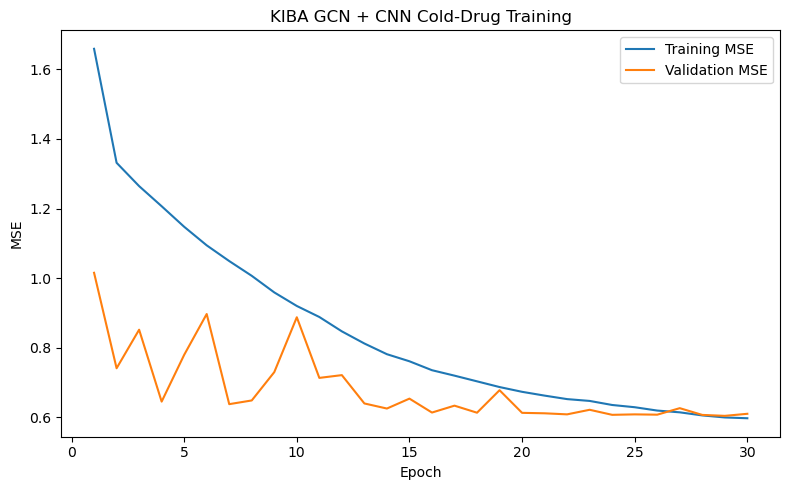

In [140]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gcn_cold_drug_history["epoch"],
    kiba_gcn_cold_drug_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gcn_cold_drug_history["epoch"],
    kiba_gcn_cold_drug_history[
        cold_drug_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(
    "KIBA GCN + CNN Cold-Drug Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gcn_cold_drug_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Plot true versus predicted scores

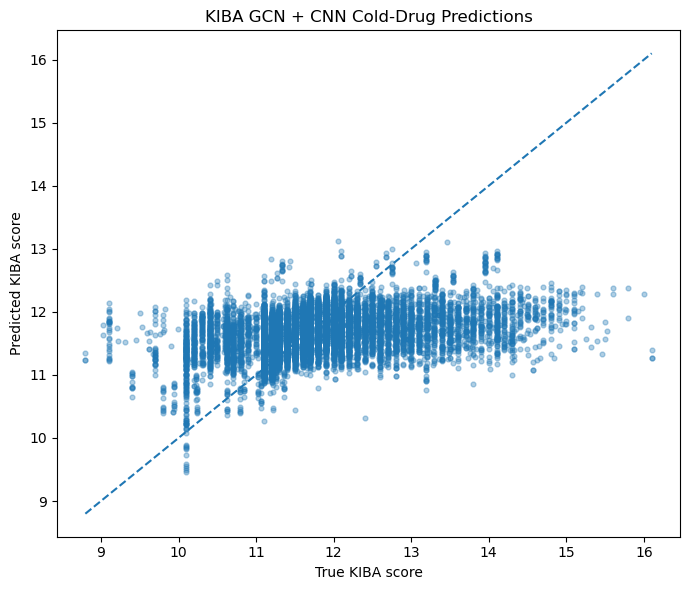

In [141]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gcn_cold_drug_true_values,
    kiba_gcn_cold_drug_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gcn_cold_drug_true_values.min(),
    kiba_gcn_cold_drug_predicted_values.min(),
)

maximum_value = max(
    kiba_gcn_cold_drug_true_values.max(),
    kiba_gcn_cold_drug_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")
plt.title(
    "KIBA GCN + CNN Cold-Drug Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gcn_cold_drug_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Confirm the outputs

In [142]:
kiba_gcn_cold_drug_outputs = [
    kiba_gcn_cold_drug_checkpoint,
    kiba_gcn_cold_drug_history_path,
    kiba_gcn_cold_drug_metrics_path,
    kiba_gcn_cold_drug_predictions_path,
    kiba_gcn_cold_drug_history_plot_path,
    kiba_gcn_cold_drug_scatter_plot_path,
]

for output_path in (
    kiba_gcn_cold_drug_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in (
        kiba_gcn_cold_drug_outputs
    )
)

print()
print(
    "KIBA GCN + CNN cold-drug "
    "experiment completed successfully."
)

best_kiba_gcn_cnn_cold_drug.pt → True
kiba_gcn_cnn_cold_drug_history.csv → True
kiba_gcn_cnn_cold_drug_metrics.json → True
kiba_gcn_cnn_cold_drug_predictions.csv → True
kiba_gcn_cnn_cold_drug_history.png → True
kiba_gcn_cnn_cold_drug_predictions.png → True

KIBA GCN + CNN cold-drug experiment completed successfully.


### KIBA GCN Cold-Drug Experiment Complete

GCN + CNN was trained and evaluated using unseen KIBA drugs.

The next experiment will train GAT + CNN using the identical cold-drug split.

### KIBA Cold-Drug — GAT + CNN

A fresh GAT + CNN model is trained using the identical KIBA cold-drug split used for GCN + CNN.

All validation and test drugs remain unseen during training.

# Remove the previous GCN model

In [144]:
objects_to_remove = [
    "kiba_gcn_cold_drug_model",
    "kiba_gcn_cold_drug_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GCN cold-drug objects removed.")

Previous GCN cold-drug objects removed.


# Define GAT output paths

In [145]:
kiba_gat_cold_drug_checkpoint = (
    MODELS_DIR
    / "best_kiba_gat_cnn_cold_drug.pt"
)

kiba_gat_cold_drug_history_path = (
    METRICS_DIR
    / "kiba_gat_cnn_cold_drug_history.csv"
)

kiba_gat_cold_drug_metrics_path = (
    METRICS_DIR
    / "kiba_gat_cnn_cold_drug_metrics.json"
)

kiba_gat_cold_drug_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gat_cnn_cold_drug_predictions.csv"
)

kiba_gat_cold_drug_history_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_cold_drug_history.png"
)

kiba_gat_cold_drug_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_cold_drug_predictions.png"
)

print("Checkpoint:")
print(kiba_gat_cold_drug_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_cnn_cold_drug.pt


# Create a fresh GAT + CNN model

In [146]:
set_random_seed(RANDOM_SEED)

kiba_gat_cold_drug_model = create_dta_model(
    model_name="gat"
).to(device)

kiba_gat_cold_drug_optimizer = torch.optim.Adam(
    kiba_gat_cold_drug_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gat_cold_drug_parameter_count = (
    count_trainable_parameters(
        kiba_gat_cold_drug_model
    )
)

print("Model: GAT + CNN")
print("Dataset: KIBA")
print("Split: cold-drug")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gat_cold_drug_parameter_count:,}",
)

Model: GAT + CNN
Dataset: KIBA
Split: cold-drug
Device: mps
Trainable parameters: 300,033


# Verify one forward pass

In [147]:
gat_cold_drug_batch = next(
    iter(kiba_cold_drug_train_loader)
).to(device)

kiba_gat_cold_drug_model.eval()

with torch.no_grad():
    gat_cold_drug_predictions = (
        kiba_gat_cold_drug_model(
            gat_cold_drug_batch
        )
        .view(-1)
    )

true_values = gat_cold_drug_batch.y.view(-1)

print(
    "Prediction shape:",
    gat_cold_drug_predictions.shape,
)

print(
    "True-value shape:",
    true_values.shape,
)

assert gat_cold_drug_predictions.shape == (
    true_values.shape
)

assert torch.isfinite(
    gat_cold_drug_predictions
).all()

del gat_cold_drug_batch
del gat_cold_drug_predictions
del true_values

if device.type == "mps":
    torch.mps.empty_cache()

print("GAT cold-drug forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT cold-drug forward pass successful.


# Train GAT + CNN

In [148]:
kiba_gat_cold_drug_start_time = (
    time.perf_counter()
)

kiba_gat_cold_drug_result = fit_model(
    model=kiba_gat_cold_drug_model,
    train_loader=kiba_cold_drug_train_loader,
    validation_loader=(
        kiba_cold_drug_validation_loader
    ),
    optimizer=kiba_gat_cold_drug_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gat_cold_drug_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gat_cold_drug_end_time = (
    time.perf_counter()
)

kiba_gat_cold_drug_runtime_minutes = (
    kiba_gat_cold_drug_end_time
    - kiba_gat_cold_drug_start_time
) / 60

print()
print(
    "Training time:",
    round(
        kiba_gat_cold_drug_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.7071 | Validation MSE: 0.6544 | RMSE: 0.8089 | MAE: 0.5244
Epoch 002 | Train MSE: 1.3164 | Validation MSE: 0.6435 | RMSE: 0.8022 | MAE: 0.5523
Epoch 003 | Train MSE: 1.2299 | Validation MSE: 0.6415 | RMSE: 0.8010 | MAE: 0.5388
Epoch 004 | Train MSE: 1.1512 | Validation MSE: 0.6931 | RMSE: 0.8325 | MAE: 0.6471
Epoch 005 | Train MSE: 1.0979 | Validation MSE: 0.6350 | RMSE: 0.7969 | MAE: 0.5145
Epoch 006 | Train MSE: 1.0401 | Validation MSE: 0.6436 | RMSE: 0.8022 | MAE: 0.5720
Epoch 007 | Train MSE: 0.9839 | Validation MSE: 0.6185 | RMSE: 0.7865 | MAE: 0.5108
Epoch 008 | Train MSE: 0.9336 | Validation MSE: 0.6140 | RMSE: 0.7836 | MAE: 0.5393
Epoch 009 | Train MSE: 0.8855 | Validation MSE: 0.6127 | RMSE: 0.7828 | MAE: 0.4968
Epoch 010 | Train MSE: 0.8336 | Validation MSE: 0.5910 | RMSE: 0.7688 | MAE: 0.5155
Epoch 011 | Train MSE: 0.8037 | Validation MSE: 0.6142 | RMSE: 0.7837 | MAE: 0.5697
Epoch 012 | Train MSE: 0.7772 | Validation MSE: 0.6063 | RMSE: 0.7786 | MAE:

# Inspect the result safely

In [149]:
print(
    "Available result keys:",
    kiba_gat_cold_drug_result.keys(),
)

kiba_gat_cold_drug_history = pd.DataFrame(
    kiba_gat_cold_drug_result["history"]
)

if (
    "validation_mse"
    in kiba_gat_cold_drug_history.columns
):
    gat_cold_drug_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gat_cold_drug_history.columns
):
    gat_cold_drug_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gat_cold_drug_history.columns.tolist()}"
    )

gat_best_history_index = (
    kiba_gat_cold_drug_history[
        gat_cold_drug_validation_column
    ].idxmin()
)

kiba_gat_cold_drug_best_mse = (
    kiba_gat_cold_drug_result.get(
        "best_validation_mse"
    )
)

if kiba_gat_cold_drug_best_mse is None:
    kiba_gat_cold_drug_best_mse = (
        kiba_gat_cold_drug_result.get(
            "best_val_mse"
        )
    )

if kiba_gat_cold_drug_best_mse is None:
    kiba_gat_cold_drug_best_mse = float(
        kiba_gat_cold_drug_history.loc[
            gat_best_history_index,
            gat_cold_drug_validation_column,
        ]
    )

kiba_gat_cold_drug_best_epoch = (
    kiba_gat_cold_drug_result.get(
        "best_epoch"
    )
)

if kiba_gat_cold_drug_best_epoch is None:
    kiba_gat_cold_drug_best_epoch = int(
        kiba_gat_cold_drug_history.loc[
            gat_best_history_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gat_cold_drug_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gat_cold_drug_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gat_cold_drug_history),
)

print(
    "Checkpoint exists:",
    kiba_gat_cold_drug_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 29
Best validation MSE: 0.4838
Completed epochs: 30
Checkpoint exists: True


# Save the training history

In [150]:
display(
    kiba_gat_cold_drug_history.tail()
)

kiba_gat_cold_drug_history.to_csv(
    kiba_gat_cold_drug_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gat_cold_drug_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.563710,0.507313,0.712259,0.493614,0.704410,0.541194
26,27,0.552792,0.495301,0.703777,0.480335,0.713077,0.559922
27,28,0.539380,0.518886,0.720337,0.473622,0.714445,0.568319
28,29,0.530091,0.483773,0.695538,0.474605,0.720015,0.572000
29,30,0.520491,0.502473,0.708853,0.511946,0.726526,0.571245


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_cnn_cold_drug_history.csv


# Load the best checkpoint

In [151]:
load_checkpoint(
    model=kiba_gat_cold_drug_model,
    checkpoint_path=(
        kiba_gat_cold_drug_checkpoint
    ),
    device=device,
)

kiba_gat_cold_drug_model.eval()

print("Best GAT cold-drug checkpoint loaded.")

Best GAT cold-drug checkpoint loaded.


# Evaluate on unseen test drugs

In [152]:
kiba_gat_cold_drug_metrics = evaluate_model(
    model=kiba_gat_cold_drug_model,
    data_loader=kiba_cold_drug_test_loader,
    device=device,
)

print("KIBA GAT cold-drug test results")
print("--------------------------------")

for metric_name, metric_value in (
    kiba_gat_cold_drug_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GAT cold-drug test results
--------------------------------
mse : 0.5238
rmse : 0.7238
mae : 0.4946
concordance_index : 0.7002
pearson_correlation : 0.5092


# Save the metrics

In [153]:
kiba_gat_cold_drug_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gat_cold_drug_metrics.items()
}

kiba_gat_cold_drug_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GAT + CNN",
        "model_name": "gat",
        "split_type": "cold_drug",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gat_cold_drug_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gat_cold_drug_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gat_cold_drug_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gat_cold_drug_parameter_count
        ),
    }
)

with open(
    kiba_gat_cold_drug_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gat_cold_drug_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gat_cold_drug_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_cnn_cold_drug_metrics.json


# Generate test predictions

In [154]:
kiba_gat_cold_drug_true_values = []
kiba_gat_cold_drug_predicted_values = []

kiba_gat_cold_drug_model.eval()

with torch.no_grad():
    for batch in kiba_cold_drug_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gat_cold_drug_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gat_cold_drug_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gat_cold_drug_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gat_cold_drug_true_values = np.asarray(
    kiba_gat_cold_drug_true_values
)

kiba_gat_cold_drug_predicted_values = np.asarray(
    kiba_gat_cold_drug_predicted_values
)

assert len(
    kiba_gat_cold_drug_true_values
) == len(
    kiba_cold_drug_test_df
)

assert len(
    kiba_gat_cold_drug_predicted_values
) == len(
    kiba_cold_drug_test_df
)

print(
    "Prediction count:",
    len(
        kiba_gat_cold_drug_predicted_values
    ),
)

Prediction count: 16744


# Save the prediction table

In [155]:
kiba_gat_cold_drug_predictions_df = (
    kiba_cold_drug_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gat_cold_drug_predictions_df[
    "true_affinity"
] = kiba_gat_cold_drug_true_values

kiba_gat_cold_drug_predictions_df[
    "predicted_affinity"
] = kiba_gat_cold_drug_predicted_values

kiba_gat_cold_drug_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gat_cold_drug_predictions_df[
        "true_affinity"
    ]
    - kiba_gat_cold_drug_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gat_cold_drug_predictions_df.to_csv(
    kiba_gat_cold_drug_predictions_path,
    index=False,
)

display(
    kiba_gat_cold_drug_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gat_cold_drug_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1929238,O00141,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,10.821246,10.821246,KIBA_score,10.821246,11.116171,0.294925
1,kiba,CHEMBL1929238,O14757,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MAVPFVEDWDLVQTLGEGAYGEVQLAVNRVTEEAVAVKIVDMKRAV...,10.622879,10.622879,KIBA_score,10.622879,11.253656,0.630777
2,kiba,CHEMBL1929238,O14920,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,10.622879,10.622879,KIBA_score,10.622879,11.260304,0.637425
3,kiba,CHEMBL1929238,O14965,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MDRSKENCISGPVKATAPVGGPKRVLVTQQFPCQNPLPVNSGQAQR...,10.622879,10.622879,KIBA_score,10.622879,11.790930,1.168051
4,kiba,CHEMBL1929238,O15264,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MSLIRKKGFYKQDVNKTAWELPKTYVSPTHVGSGAYGSVCSAIDKR...,10.622879,10.622879,KIBA_score,10.622879,11.042071,0.419192


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gat_cnn_cold_drug_predictions.csv


# Plot the training history

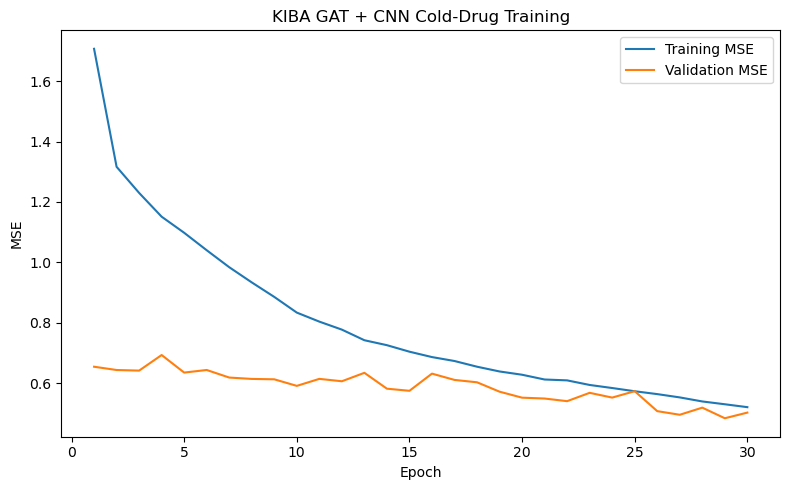

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_cnn_cold_drug_history.png


In [156]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gat_cold_drug_history["epoch"],
    kiba_gat_cold_drug_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gat_cold_drug_history["epoch"],
    kiba_gat_cold_drug_history[
        gat_cold_drug_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GAT + CNN Cold-Drug Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gat_cold_drug_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gat_cold_drug_history_plot_path)

# Plot true versus predicted scores

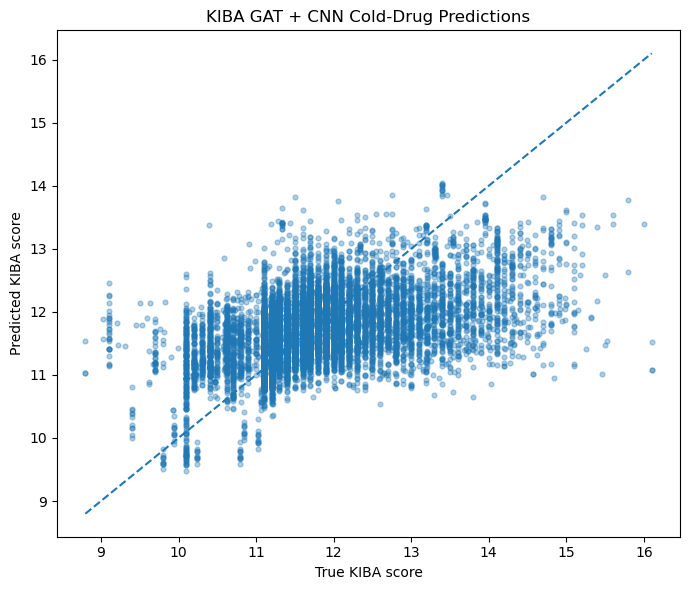

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_cnn_cold_drug_predictions.png


In [157]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gat_cold_drug_true_values,
    kiba_gat_cold_drug_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gat_cold_drug_true_values.min(),
    kiba_gat_cold_drug_predicted_values.min(),
)

maximum_value = max(
    kiba_gat_cold_drug_true_values.max(),
    kiba_gat_cold_drug_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GAT + CNN Cold-Drug Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gat_cold_drug_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gat_cold_drug_scatter_plot_path)

# Confirm all outputs

In [158]:
kiba_gat_cold_drug_outputs = [
    kiba_gat_cold_drug_checkpoint,
    kiba_gat_cold_drug_history_path,
    kiba_gat_cold_drug_metrics_path,
    kiba_gat_cold_drug_predictions_path,
    kiba_gat_cold_drug_history_plot_path,
    kiba_gat_cold_drug_scatter_plot_path,
]

for output_path in (
    kiba_gat_cold_drug_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in (
        kiba_gat_cold_drug_outputs
    )
)

print()
print(
    "KIBA GAT + CNN cold-drug "
    "experiment completed successfully."
)

best_kiba_gat_cnn_cold_drug.pt → True
kiba_gat_cnn_cold_drug_history.csv → True
kiba_gat_cnn_cold_drug_metrics.json → True
kiba_gat_cnn_cold_drug_predictions.csv → True
kiba_gat_cnn_cold_drug_history.png → True
kiba_gat_cnn_cold_drug_predictions.png → True

KIBA GAT + CNN cold-drug experiment completed successfully.


### KIBA GAT Cold-Drug Experiment Complete

GAT + CNN was trained and evaluated using unseen KIBA drugs.

The next experiment will train GIN + CNN using the identical cold-drug split.

### KIBA Cold-Drug — GIN + CNN

A fresh GIN + CNN model is trained using the identical KIBA cold-drug split used for GCN + CNN and GAT + CNN.

All validation and test drugs remain unseen during training.

# Remove the previous GAT model

In [159]:
objects_to_remove = [
    "kiba_gat_cold_drug_model",
    "kiba_gat_cold_drug_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GAT cold-drug objects removed.")

Previous GAT cold-drug objects removed.


# Define GIN output paths

In [160]:
kiba_gin_cold_drug_checkpoint = (
    MODELS_DIR
    / "best_kiba_gin_cnn_cold_drug.pt"
)

kiba_gin_cold_drug_history_path = (
    METRICS_DIR
    / "kiba_gin_cnn_cold_drug_history.csv"
)

kiba_gin_cold_drug_metrics_path = (
    METRICS_DIR
    / "kiba_gin_cnn_cold_drug_metrics.json"
)

kiba_gin_cold_drug_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gin_cnn_cold_drug_predictions.csv"
)

kiba_gin_cold_drug_history_plot_path = (
    PLOTS_DIR
    / "kiba_gin_cnn_cold_drug_history.png"
)

kiba_gin_cold_drug_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gin_cnn_cold_drug_predictions.png"
)

print("Checkpoint:")
print(kiba_gin_cold_drug_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gin_cnn_cold_drug.pt


# Create a fresh GIN + CNN model

In [161]:
set_random_seed(RANDOM_SEED)

kiba_gin_cold_drug_model = create_dta_model(
    model_name="gin"
).to(device)

kiba_gin_cold_drug_optimizer = torch.optim.Adam(
    kiba_gin_cold_drug_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gin_cold_drug_parameter_count = (
    count_trainable_parameters(
        kiba_gin_cold_drug_model
    )
)

print("Model: GIN + CNN")
print("Dataset: KIBA")
print("Split: cold-drug")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gin_cold_drug_parameter_count:,}",
)

Model: GIN + CNN
Dataset: KIBA
Split: cold-drug
Device: mps
Trainable parameters: 348,801


# Verify one forward pass

In [162]:
gin_cold_drug_batch = next(
    iter(kiba_cold_drug_train_loader)
).to(device)

kiba_gin_cold_drug_model.eval()

with torch.no_grad():
    gin_cold_drug_predictions = (
        kiba_gin_cold_drug_model(
            gin_cold_drug_batch
        )
        .view(-1)
    )

gin_cold_drug_true_values = (
    gin_cold_drug_batch.y.view(-1)
)

print(
    "Prediction shape:",
    gin_cold_drug_predictions.shape,
)

print(
    "True-value shape:",
    gin_cold_drug_true_values.shape,
)

assert gin_cold_drug_predictions.shape == (
    gin_cold_drug_true_values.shape
)

assert torch.isfinite(
    gin_cold_drug_predictions
).all()

del gin_cold_drug_batch
del gin_cold_drug_predictions
del gin_cold_drug_true_values

if device.type == "mps":
    torch.mps.empty_cache()

print("GIN cold-drug forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GIN cold-drug forward pass successful.


# Train GIN + CNN

In [163]:
kiba_gin_cold_drug_start_time = (
    time.perf_counter()
)

kiba_gin_cold_drug_result = fit_model(
    model=kiba_gin_cold_drug_model,
    train_loader=kiba_cold_drug_train_loader,
    validation_loader=(
        kiba_cold_drug_validation_loader
    ),
    optimizer=kiba_gin_cold_drug_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gin_cold_drug_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gin_cold_drug_end_time = (
    time.perf_counter()
)

kiba_gin_cold_drug_runtime_minutes = (
    kiba_gin_cold_drug_end_time
    - kiba_gin_cold_drug_start_time
) / 60

print()
print(
    "Training time:",
    round(
        kiba_gin_cold_drug_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.7062 | Validation MSE: 1.0017 | RMSE: 1.0009 | MAE: 0.7091
Epoch 002 | Train MSE: 1.3954 | Validation MSE: 0.6645 | RMSE: 0.8151 | MAE: 0.5305
Epoch 003 | Train MSE: 1.3204 | Validation MSE: 0.7709 | RMSE: 0.8780 | MAE: 0.5714
Epoch 004 | Train MSE: 1.2750 | Validation MSE: 0.8198 | RMSE: 0.9054 | MAE: 0.5890
Epoch 005 | Train MSE: 1.1849 | Validation MSE: 1.0583 | RMSE: 1.0288 | MAE: 0.7568
Epoch 006 | Train MSE: 1.1335 | Validation MSE: 1.2502 | RMSE: 1.1181 | MAE: 0.8587
Epoch 007 | Train MSE: 1.0907 | Validation MSE: 1.1757 | RMSE: 1.0843 | MAE: 0.8219
Epoch 008 | Train MSE: 1.0319 | Validation MSE: 0.8664 | RMSE: 0.9308 | MAE: 0.6315
Epoch 009 | Train MSE: 0.9651 | Validation MSE: 0.7161 | RMSE: 0.8462 | MAE: 0.5444
Early stopping triggered at epoch 9.

Training time: 23.82 minutes


# Inspect the result safely

In [164]:
print(
    "Available result keys:",
    kiba_gin_cold_drug_result.keys(),
)

kiba_gin_cold_drug_history = pd.DataFrame(
    kiba_gin_cold_drug_result["history"]
)

if (
    "validation_mse"
    in kiba_gin_cold_drug_history.columns
):
    gin_cold_drug_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gin_cold_drug_history.columns
):
    gin_cold_drug_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gin_cold_drug_history.columns.tolist()}"
    )

gin_best_history_index = (
    kiba_gin_cold_drug_history[
        gin_cold_drug_validation_column
    ].idxmin()
)

kiba_gin_cold_drug_best_mse = (
    kiba_gin_cold_drug_result.get(
        "best_validation_mse"
    )
)

if kiba_gin_cold_drug_best_mse is None:
    kiba_gin_cold_drug_best_mse = (
        kiba_gin_cold_drug_result.get(
            "best_val_mse"
        )
    )

if kiba_gin_cold_drug_best_mse is None:
    kiba_gin_cold_drug_best_mse = float(
        kiba_gin_cold_drug_history.loc[
            gin_best_history_index,
            gin_cold_drug_validation_column,
        ]
    )

kiba_gin_cold_drug_best_epoch = (
    kiba_gin_cold_drug_result.get(
        "best_epoch"
    )
)

if kiba_gin_cold_drug_best_epoch is None:
    kiba_gin_cold_drug_best_epoch = int(
        kiba_gin_cold_drug_history.loc[
            gin_best_history_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gin_cold_drug_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gin_cold_drug_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gin_cold_drug_history),
)

print(
    "Checkpoint exists:",
    kiba_gin_cold_drug_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 2
Best validation MSE: 0.6645
Completed epochs: 9
Checkpoint exists: True


# Save the training history

In [165]:
display(
    kiba_gin_cold_drug_history.tail()
)

kiba_gin_cold_drug_history.to_csv(
    kiba_gin_cold_drug_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gin_cold_drug_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
4,5,1.184887,1.058343,1.028758,0.756817,0.662733,0.346705
5,6,1.133509,1.250198,1.118122,0.858673,0.671560,0.357540
6,7,1.090746,1.175692,1.084293,0.821893,0.667706,0.362327
7,8,1.031913,0.866356,0.930783,0.631470,0.673698,0.360197
8,9,0.965136,0.716077,0.846214,0.544379,0.676073,0.359285


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gin_cnn_cold_drug_history.csv


# Load the best checkpoint

In [166]:
load_checkpoint(
    model=kiba_gin_cold_drug_model,
    checkpoint_path=(
        kiba_gin_cold_drug_checkpoint
    ),
    device=device,
)

kiba_gin_cold_drug_model.eval()

print("Best GIN cold-drug checkpoint loaded.")

Best GIN cold-drug checkpoint loaded.


# Evaluate on unseen test drugs

In [167]:
kiba_gin_cold_drug_metrics = evaluate_model(
    model=kiba_gin_cold_drug_model,
    data_loader=kiba_cold_drug_test_loader,
    device=device,
)

print("KIBA GIN cold-drug test results")
print("--------------------------------")

for metric_name, metric_value in (
    kiba_gin_cold_drug_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GIN cold-drug test results
--------------------------------
mse : 0.6685
rmse : 0.8176
mae : 0.5408
concordance_index : 0.6377
pearson_correlation : 0.2869


# Save the metrics

In [168]:
kiba_gin_cold_drug_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gin_cold_drug_metrics.items()
}

kiba_gin_cold_drug_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GIN + CNN",
        "model_name": "gin",
        "split_type": "cold_drug",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gin_cold_drug_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gin_cold_drug_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gin_cold_drug_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gin_cold_drug_parameter_count
        ),
    }
)

with open(
    kiba_gin_cold_drug_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gin_cold_drug_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gin_cold_drug_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gin_cnn_cold_drug_metrics.json


# Generate test predictions

In [169]:
kiba_gin_cold_drug_true_values = []
kiba_gin_cold_drug_predicted_values = []

kiba_gin_cold_drug_model.eval()

with torch.no_grad():
    for batch in kiba_cold_drug_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gin_cold_drug_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gin_cold_drug_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gin_cold_drug_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gin_cold_drug_true_values = np.asarray(
    kiba_gin_cold_drug_true_values
)

kiba_gin_cold_drug_predicted_values = np.asarray(
    kiba_gin_cold_drug_predicted_values
)

assert len(
    kiba_gin_cold_drug_true_values
) == len(
    kiba_cold_drug_test_df
)

assert len(
    kiba_gin_cold_drug_predicted_values
) == len(
    kiba_cold_drug_test_df
)

print(
    "Prediction count:",
    len(
        kiba_gin_cold_drug_predicted_values
    ),
)

Prediction count: 16744


# Save the prediction table

In [170]:
kiba_gin_cold_drug_predictions_df = (
    kiba_cold_drug_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gin_cold_drug_predictions_df[
    "true_affinity"
] = kiba_gin_cold_drug_true_values

kiba_gin_cold_drug_predictions_df[
    "predicted_affinity"
] = kiba_gin_cold_drug_predicted_values

kiba_gin_cold_drug_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gin_cold_drug_predictions_df[
        "true_affinity"
    ]
    - kiba_gin_cold_drug_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gin_cold_drug_predictions_df.to_csv(
    kiba_gin_cold_drug_predictions_path,
    index=False,
)

display(
    kiba_gin_cold_drug_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gin_cold_drug_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1929238,O00141,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,10.821246,10.821246,KIBA_score,10.821246,11.141003,0.319757
1,kiba,CHEMBL1929238,O14757,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MAVPFVEDWDLVQTLGEGAYGEVQLAVNRVTEEAVAVKIVDMKRAV...,10.622879,10.622879,KIBA_score,10.622879,11.166487,0.543608
2,kiba,CHEMBL1929238,O14920,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,10.622879,10.622879,KIBA_score,10.622879,11.346826,0.723947
3,kiba,CHEMBL1929238,O14965,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MDRSKENCISGPVKATAPVGGPKRVLVTQQFPCQNPLPVNSGQAQR...,10.622879,10.622879,KIBA_score,10.622879,12.382662,1.759783
4,kiba,CHEMBL1929238,O15264,CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl...,MSLIRKKGFYKQDVNKTAWELPKTYVSPTHVGSGAYGSVCSAIDKR...,10.622879,10.622879,KIBA_score,10.622879,10.965365,0.342486


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gin_cnn_cold_drug_predictions.csv


# Plot the training history

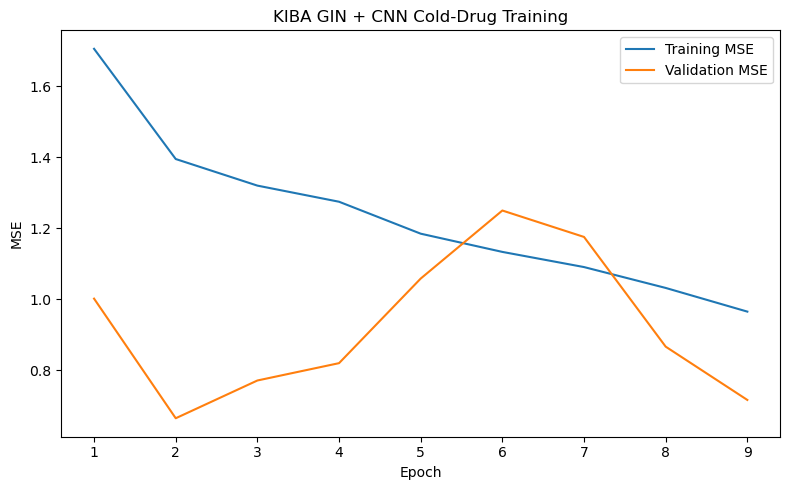

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gin_cnn_cold_drug_history.png


In [171]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gin_cold_drug_history["epoch"],
    kiba_gin_cold_drug_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gin_cold_drug_history["epoch"],
    kiba_gin_cold_drug_history[
        gin_cold_drug_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GIN + CNN Cold-Drug Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gin_cold_drug_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gin_cold_drug_history_plot_path)

# Plot true versus predicted scores

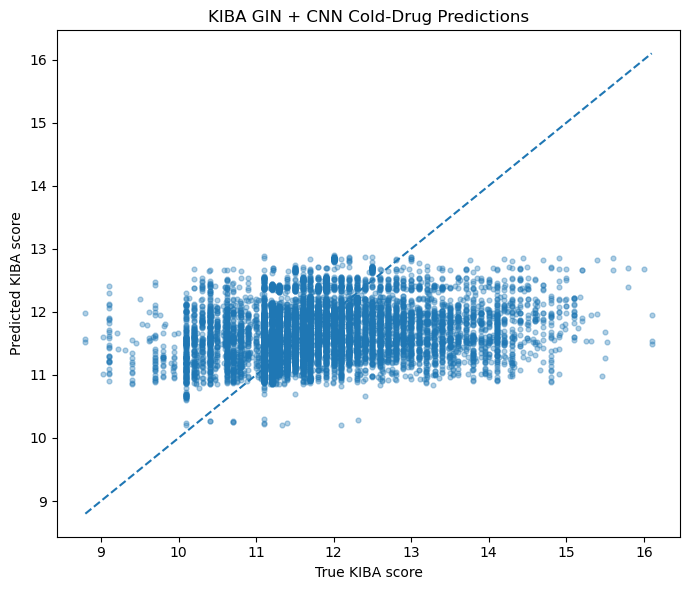

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gin_cnn_cold_drug_predictions.png


In [172]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gin_cold_drug_true_values,
    kiba_gin_cold_drug_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gin_cold_drug_true_values.min(),
    kiba_gin_cold_drug_predicted_values.min(),
)

maximum_value = max(
    kiba_gin_cold_drug_true_values.max(),
    kiba_gin_cold_drug_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GIN + CNN Cold-Drug Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gin_cold_drug_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gin_cold_drug_scatter_plot_path)

# Confirm all outputs

In [173]:
kiba_gin_cold_drug_outputs = [
    kiba_gin_cold_drug_checkpoint,
    kiba_gin_cold_drug_history_path,
    kiba_gin_cold_drug_metrics_path,
    kiba_gin_cold_drug_predictions_path,
    kiba_gin_cold_drug_history_plot_path,
    kiba_gin_cold_drug_scatter_plot_path,
]

for output_path in (
    kiba_gin_cold_drug_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in (
        kiba_gin_cold_drug_outputs
    )
)

print()
print(
    "KIBA GIN + CNN cold-drug "
    "experiment completed successfully."
)

best_kiba_gin_cnn_cold_drug.pt → True
kiba_gin_cnn_cold_drug_history.csv → True
kiba_gin_cnn_cold_drug_metrics.json → True
kiba_gin_cnn_cold_drug_predictions.csv → True
kiba_gin_cnn_cold_drug_history.png → True
kiba_gin_cnn_cold_drug_predictions.png → True

KIBA GIN + CNN cold-drug experiment completed successfully.


### KIBA Cold-Drug Training Complete

GCN + CNN, GAT + CNN and GIN + CNN were trained and evaluated using the same KIBA cold-drug split.

The next section compares all three cold-drug models using validation performance and held-out test metrics.

## KIBA Cold-Drug Model Comparison

This section compares:

- GCN + CNN
- GAT + CNN
- GIN + CNN

All three models used the same KIBA cold-drug split, random seed and training configuration.

The preliminary cold-drug winner is selected using the lowest validation MSE. Test metrics are reported after model selection.

# Load the saved metrics

In [174]:
def load_json_file(file_path):
    with open(
        file_path,
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


kiba_gcn_cold_drug_saved_metrics = (
    load_json_file(
        METRICS_DIR
        / "kiba_gcn_cnn_cold_drug_metrics.json"
    )
)

kiba_gat_cold_drug_saved_metrics = (
    load_json_file(
        METRICS_DIR
        / "kiba_gat_cnn_cold_drug_metrics.json"
    )
)

kiba_gin_cold_drug_saved_metrics = (
    load_json_file(
        METRICS_DIR
        / "kiba_gin_cnn_cold_drug_metrics.json"
    )
)

print(
    "GCN metrics loaded:",
    bool(kiba_gcn_cold_drug_saved_metrics),
)

print(
    "GAT metrics loaded:",
    bool(kiba_gat_cold_drug_saved_metrics),
)

print(
    "GIN metrics loaded:",
    bool(kiba_gin_cold_drug_saved_metrics),
)

GCN metrics loaded: True
GAT metrics loaded: True
GIN metrics loaded: True


# Inspect metric keys

In [175]:
print(
    "GCN keys:",
    kiba_gcn_cold_drug_saved_metrics.keys(),
)

print(
    "GAT keys:",
    kiba_gat_cold_drug_saved_metrics.keys(),
)

print(
    "GIN keys:",
    kiba_gin_cold_drug_saved_metrics.keys(),
)

GCN keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])
GAT keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])
GIN keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])


# Create a robust experiment-summary function

In [176]:
def get_saved_experiment_summary(
    saved_metrics,
    history_path,
):
    history_df = pd.read_csv(history_path)

    if "validation_mse" in history_df.columns:
        validation_column = "validation_mse"

    elif "val_mse" in history_df.columns:
        validation_column = "val_mse"

    else:
        raise KeyError(
            "No validation MSE column found in "
            f"{history_path.name}. "
            f"Available columns: "
            f"{history_df.columns.tolist()}"
        )

    best_history_index = (
        history_df[validation_column].idxmin()
    )

    best_validation_mse = saved_metrics.get(
        "best_validation_mse"
    )

    if best_validation_mse is None:
        best_validation_mse = (
            saved_metrics.get("best_val_mse")
        )

    if best_validation_mse is None:
        best_validation_mse = float(
            history_df.loc[
                best_history_index,
                validation_column,
            ]
        )

    best_epoch = saved_metrics.get(
        "best_epoch"
    )

    if best_epoch is None:
        best_epoch = int(
            history_df.loc[
                best_history_index,
                "epoch",
            ]
        )

    return {
        "best_epoch": int(best_epoch),
        "best_validation_mse": float(
            best_validation_mse
        ),
    }


print("Experiment-summary function ready.")

Experiment-summary function ready.


# Recover the three model summaries

In [177]:
kiba_gcn_cold_drug_summary = (
    get_saved_experiment_summary(
        saved_metrics=(
            kiba_gcn_cold_drug_saved_metrics
        ),
        history_path=(
            METRICS_DIR
            / "kiba_gcn_cnn_cold_drug_history.csv"
        ),
    )
)

kiba_gat_cold_drug_summary = (
    get_saved_experiment_summary(
        saved_metrics=(
            kiba_gat_cold_drug_saved_metrics
        ),
        history_path=(
            METRICS_DIR
            / "kiba_gat_cnn_cold_drug_history.csv"
        ),
    )
)

kiba_gin_cold_drug_summary = (
    get_saved_experiment_summary(
        saved_metrics=(
            kiba_gin_cold_drug_saved_metrics
        ),
        history_path=(
            METRICS_DIR
            / "kiba_gin_cnn_cold_drug_history.csv"
        ),
    )
)

print(
    "GCN summary:",
    kiba_gcn_cold_drug_summary,
)

print(
    "GAT summary:",
    kiba_gat_cold_drug_summary,
)

print(
    "GIN summary:",
    kiba_gin_cold_drug_summary,
)

GCN summary: {'best_epoch': 29, 'best_validation_mse': 0.6043014662895859}
GAT summary: {'best_epoch': 29, 'best_validation_mse': 0.4837728151793901}
GIN summary: {'best_epoch': 2, 'best_validation_mse': 0.6644570309125425}


# Create the comparison table

In [178]:
kiba_cold_drug_comparison_df = pd.DataFrame(
    [
        {
            "model": "GCN + CNN",
            "model_name": "gcn",
            "split_type": "cold_drug",
            "best_epoch": (
                kiba_gcn_cold_drug_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gcn_cold_drug_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gcn_cold_drug_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gcn_cold_drug_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gcn_cold_drug_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gcn_cold_drug_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gcn_cold_drug_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gcn_cold_drug_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gcn_cold_drug_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
        {
            "model": "GAT + CNN",
            "model_name": "gat",
            "split_type": "cold_drug",
            "best_epoch": (
                kiba_gat_cold_drug_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gat_cold_drug_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gat_cold_drug_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gat_cold_drug_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gat_cold_drug_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gat_cold_drug_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gat_cold_drug_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gat_cold_drug_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gat_cold_drug_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
        {
            "model": "GIN + CNN",
            "model_name": "gin",
            "split_type": "cold_drug",
            "best_epoch": (
                kiba_gin_cold_drug_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gin_cold_drug_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gin_cold_drug_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gin_cold_drug_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gin_cold_drug_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gin_cold_drug_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gin_cold_drug_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gin_cold_drug_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gin_cold_drug_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
    ]
)

kiba_cold_drug_comparison_df = (
    kiba_cold_drug_comparison_df
    .sort_values("best_validation_mse")
    .reset_index(drop=True)
)

kiba_cold_drug_comparison_df.insert(
    0,
    "validation_rank",
    range(
        1,
        len(kiba_cold_drug_comparison_df) + 1,
    ),
)

display(
    kiba_cold_drug_comparison_df.round(4)
)

,validation_rank,model,model_name,split_type,best_epoch,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,training_runtime_minutes,trainable_parameters
0,1,GAT + CNN,gat,cold_drug,29,0.4838,0.5238,0.7238,0.4946,0.7002,0.5092,94.0584,300033
1,2,GCN + CNN,gcn,cold_drug,29,0.6043,0.5862,0.7657,0.5004,0.6786,0.4110,73.9211,299265
2,3,GIN + CNN,gin,cold_drug,2,0.6645,0.6685,0.8176,0.5408,0.6377,0.2869,23.8159,348801


# Validate the comparison table

In [179]:
required_columns = [
    "best_validation_mse",
    "test_mse",
    "test_rmse",
    "test_mae",
    "concordance_index",
    "pearson_correlation",
]

assert len(
    kiba_cold_drug_comparison_df
) == 3

assert all(
    column_name
    in kiba_cold_drug_comparison_df.columns
    for column_name in required_columns
)

assert np.isfinite(
    kiba_cold_drug_comparison_df[
        required_columns
    ].to_numpy(dtype=float)
).all()

print(
    "KIBA cold-drug comparison "
    "table validated."
)

KIBA cold-drug comparison table validated.


# Display the cold-drug winner

In [180]:
kiba_cold_drug_best_model = (
    kiba_cold_drug_comparison_df.iloc[0]
)

print("KIBA cold-drug preliminary winner")
print("---------------------------------")

print(
    "Model:",
    kiba_cold_drug_best_model["model"],
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_cold_drug_best_model[
                "best_validation_mse"
            ]
        ),
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        float(
            kiba_cold_drug_best_model[
                "test_rmse"
            ]
        ),
        4,
    ),
)

print(
    "Test MAE:",
    round(
        float(
            kiba_cold_drug_best_model[
                "test_mae"
            ]
        ),
        4,
    ),
)

print(
    "Concordance index:",
    round(
        float(
            kiba_cold_drug_best_model[
                "concordance_index"
            ]
        ),
        4,
    ),
)

print(
    "Pearson correlation:",
    round(
        float(
            kiba_cold_drug_best_model[
                "pearson_correlation"
            ]
        ),
        4,
    ),
)

KIBA cold-drug preliminary winner
---------------------------------
Model: GAT + CNN
Best validation MSE: 0.4838
Test RMSE: 0.7238
Test MAE: 0.4946
Concordance index: 0.7002
Pearson correlation: 0.5092


# Save the comparison table

In [181]:
kiba_cold_drug_comparison_path = (
    METRICS_DIR
    / "kiba_cold_drug_model_comparison.csv"
)

kiba_cold_drug_comparison_df.to_csv(
    kiba_cold_drug_comparison_path,
    index=False,
)

print("Comparison saved to:")
print(kiba_cold_drug_comparison_path)

Comparison saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_cold_drug_model_comparison.csv


# Plot test RMSE

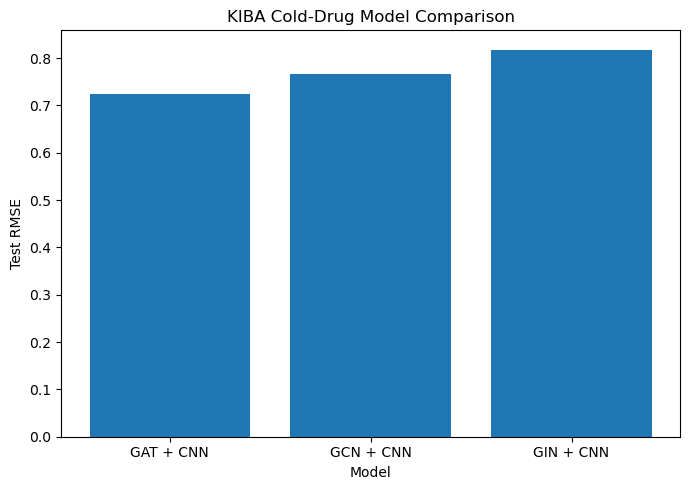

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_cold_drug_rmse_comparison.png


In [182]:
plt.figure(figsize=(7, 5))

plt.bar(
    kiba_cold_drug_comparison_df["model"],
    kiba_cold_drug_comparison_df[
        "test_rmse"
    ],
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")

plt.title(
    "KIBA Cold-Drug Model Comparison"
)

plt.tight_layout()

kiba_cold_drug_rmse_plot_path = (
    PLOTS_DIR
    / "kiba_cold_drug_rmse_comparison.png"
)

plt.savefig(
    kiba_cold_drug_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_cold_drug_rmse_plot_path)

# Plot concordance index

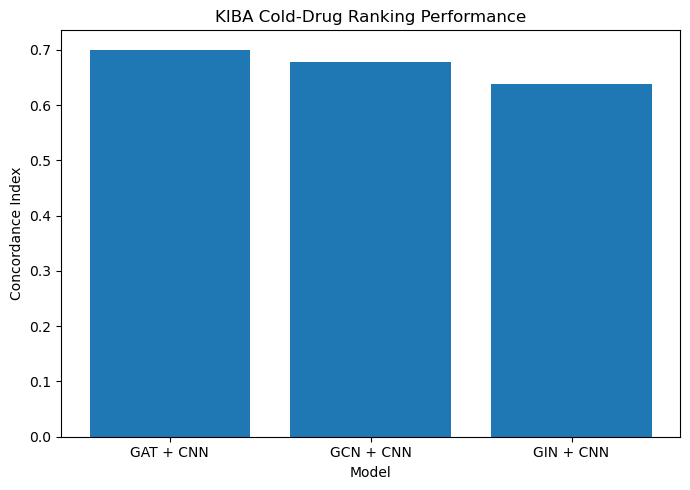

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_cold_drug_ci_comparison.png


In [183]:
plt.figure(figsize=(7, 5))

plt.bar(
    kiba_cold_drug_comparison_df["model"],
    kiba_cold_drug_comparison_df[
        "concordance_index"
    ],
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")

plt.title(
    "KIBA Cold-Drug Ranking Performance"
)

plt.tight_layout()

kiba_cold_drug_ci_plot_path = (
    PLOTS_DIR
    / "kiba_cold_drug_ci_comparison.png"
)

plt.savefig(
    kiba_cold_drug_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_cold_drug_ci_plot_path)

# Display computational comparison

In [184]:
kiba_cold_drug_runtime_df = (
    kiba_cold_drug_comparison_df[
        [
            "model",
            "best_epoch",
            "training_runtime_minutes",
            "trainable_parameters",
        ]
    ]
    .copy()
)

display(
    kiba_cold_drug_runtime_df.round(2)
)

,model,best_epoch,training_runtime_minutes,trainable_parameters
0,GAT + CNN,29,94.06,300033
1,GCN + CNN,29,73.92,299265
2,GIN + CNN,2,23.82,348801


# Confirm the outputs

In [185]:
kiba_cold_drug_comparison_outputs = [
    kiba_cold_drug_comparison_path,
    kiba_cold_drug_rmse_plot_path,
    kiba_cold_drug_ci_plot_path,
]

for output_path in (
    kiba_cold_drug_comparison_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_cold_drug_comparison_outputs
)

print()
print(
    "KIBA cold-drug model comparison "
    "completed successfully."
)

kiba_cold_drug_model_comparison.csv → True
kiba_cold_drug_rmse_comparison.png → True
kiba_cold_drug_ci_comparison.png → True

KIBA cold-drug model comparison completed successfully.


### KIBA Cold-Drug Comparison Complete

GCN + CNN, GAT + CNN and GIN + CNN were compared using the same cold-drug split.

The preliminary cold-drug winner was selected using validation MSE.

The next stage evaluates all three models using a cold-target split, where validation and test protein targets are completely unseen during training.

## KIBA Cold-Target Evaluation

In the cold-target split, validation and test protein targets are completely absent from the training set.

This evaluates whether the model can predict binding affinity for previously unseen proteins.

# Load the saved cold-target splits

In [186]:
kiba_cold_target_train_path = (
    SPLITS_DIR
    / "cold_target"
    / "kiba_train.csv"
)

kiba_cold_target_validation_path = (
    SPLITS_DIR
    / "cold_target"
    / "kiba_validation.csv"
)

kiba_cold_target_test_path = (
    SPLITS_DIR
    / "cold_target"
    / "kiba_test.csv"
)

if "kiba_cold_target_train_df" not in globals():
    kiba_cold_target_train_df = pd.read_csv(
        kiba_cold_target_train_path
    )

if "kiba_cold_target_validation_df" not in globals():
    kiba_cold_target_validation_df = pd.read_csv(
        kiba_cold_target_validation_path
    )

if "kiba_cold_target_test_df" not in globals():
    kiba_cold_target_test_df = pd.read_csv(
        kiba_cold_target_test_path
    )

print(
    "Training rows:",
    len(kiba_cold_target_train_df),
)

print(
    "Validation rows:",
    len(kiba_cold_target_validation_df),
)

print(
    "Test rows:",
    len(kiba_cold_target_test_df),
)

Training rows: 84964
Validation rows: 16513
Test rows: 16777


# Create the cold-target DataLoaders

In [187]:
kiba_cold_target_data = create_kiba_dataloaders(
    train_dataframe=kiba_cold_target_train_df,
    validation_dataframe=(
        kiba_cold_target_validation_df
    ),
    test_dataframe=kiba_cold_target_test_df,
)

kiba_cold_target_train_dataset = (
    kiba_cold_target_data["train_dataset"]
)

kiba_cold_target_validation_dataset = (
    kiba_cold_target_data["validation_dataset"]
)

kiba_cold_target_test_dataset = (
    kiba_cold_target_data["test_dataset"]
)

kiba_cold_target_train_loader = (
    kiba_cold_target_data["train_loader"]
)

kiba_cold_target_validation_loader = (
    kiba_cold_target_data["validation_loader"]
)

kiba_cold_target_test_loader = (
    kiba_cold_target_data["test_loader"]
)

print("KIBA cold-target DataLoaders created.")

KIBA cold-target DataLoaders created.


# Check the DataLoaders

In [188]:
cold_target_batch = next(
    iter(kiba_cold_target_train_loader)
)

print(
    "Training samples:",
    len(kiba_cold_target_train_dataset),
)

print(
    "Validation samples:",
    len(kiba_cold_target_validation_dataset),
)

print(
    "Test samples:",
    len(kiba_cold_target_test_dataset),
)

print()

print(
    "Graphs in batch:",
    cold_target_batch.num_graphs,
)

print(
    "Drug node shape:",
    cold_target_batch.x.shape,
)

print(
    "Protein shape:",
    cold_target_batch.target.shape,
)

print(
    "Affinity shape:",
    cold_target_batch.y.shape,
)

assert cold_target_batch.x.shape[1] == 6
assert cold_target_batch.target.shape[1] == 1000

print("Cold-target DataLoaders verified.")

Training samples: 84964
Validation samples: 16513
Test samples: 16777

Graphs in batch: 32
Drug node shape: torch.Size([933, 6])
Protein shape: torch.Size([32, 1000])
Affinity shape: torch.Size([32])
Cold-target DataLoaders verified.


# Confirm that targets do not overlap

In [189]:
cold_target_train_ids = set(
    kiba_cold_target_train_df[
        "target_id"
    ].astype(str)
)

cold_target_validation_ids = set(
    kiba_cold_target_validation_df[
        "target_id"
    ].astype(str)
)

cold_target_test_ids = set(
    kiba_cold_target_test_df[
        "target_id"
    ].astype(str)
)

assert cold_target_train_ids.isdisjoint(
    cold_target_validation_ids
)

assert cold_target_train_ids.isdisjoint(
    cold_target_test_ids
)

assert cold_target_validation_ids.isdisjoint(
    cold_target_test_ids
)

print(
    "Training targets:",
    len(cold_target_train_ids),
)

print(
    "Validation targets:",
    len(cold_target_validation_ids),
)

print(
    "Test targets:",
    len(cold_target_test_ids),
)

print("No target overlap detected.")

Training targets: 160
Validation targets: 34
Test targets: 35
No target overlap detected.


### KIBA Cold-Target — GCN + CNN

A fresh GCN + CNN model is trained using the KIBA cold-target split.

All validation and test proteins are unseen during training.

# Clear the previous cold-drug model

In [190]:
objects_to_remove = [
    "kiba_gin_cold_drug_model",
    "kiba_gin_cold_drug_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous cold-drug model objects removed.")

Previous cold-drug model objects removed.


# Define the output paths

In [191]:
kiba_gcn_cold_target_checkpoint = (
    MODELS_DIR
    / "best_kiba_gcn_cnn_cold_target.pt"
)

kiba_gcn_cold_target_history_path = (
    METRICS_DIR
    / "kiba_gcn_cnn_cold_target_history.csv"
)

kiba_gcn_cold_target_metrics_path = (
    METRICS_DIR
    / "kiba_gcn_cnn_cold_target_metrics.json"
)

kiba_gcn_cold_target_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gcn_cnn_cold_target_predictions.csv"
)

kiba_gcn_cold_target_history_plot_path = (
    PLOTS_DIR
    / "kiba_gcn_cnn_cold_target_history.png"
)

kiba_gcn_cold_target_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gcn_cnn_cold_target_predictions.png"
)

print("Checkpoint:")
print(kiba_gcn_cold_target_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gcn_cnn_cold_target.pt


# Create a fresh GCN + CNN model

In [192]:
set_random_seed(RANDOM_SEED)

kiba_gcn_cold_target_model = create_dta_model(
    model_name="gcn"
).to(device)

kiba_gcn_cold_target_optimizer = (
    torch.optim.Adam(
        kiba_gcn_cold_target_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
)

kiba_gcn_cold_target_parameter_count = (
    count_trainable_parameters(
        kiba_gcn_cold_target_model
    )
)

print("Model: GCN + CNN")
print("Dataset: KIBA")
print("Split: cold-target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gcn_cold_target_parameter_count:,}",
)

Model: GCN + CNN
Dataset: KIBA
Split: cold-target
Device: mps
Trainable parameters: 299,265


# Verify one forward pass

In [193]:
gcn_cold_target_batch = next(
    iter(kiba_cold_target_train_loader)
).to(device)

kiba_gcn_cold_target_model.eval()

with torch.no_grad():
    gcn_cold_target_predictions = (
        kiba_gcn_cold_target_model(
            gcn_cold_target_batch
        )
        .view(-1)
    )

gcn_cold_target_true_values = (
    gcn_cold_target_batch.y.view(-1)
)

print(
    "Prediction shape:",
    gcn_cold_target_predictions.shape,
)

print(
    "True-value shape:",
    gcn_cold_target_true_values.shape,
)

assert gcn_cold_target_predictions.shape == (
    gcn_cold_target_true_values.shape
)

assert torch.isfinite(
    gcn_cold_target_predictions
).all()

del gcn_cold_target_batch
del gcn_cold_target_predictions
del gcn_cold_target_true_values

if device.type == "mps":
    torch.mps.empty_cache()

print("GCN cold-target forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GCN cold-target forward pass successful.


# Train GCN + CNN

In [194]:
kiba_gcn_cold_target_start_time = (
    time.perf_counter()
)

kiba_gcn_cold_target_result = fit_model(
    model=kiba_gcn_cold_target_model,
    train_loader=kiba_cold_target_train_loader,
    validation_loader=(
        kiba_cold_target_validation_loader
    ),
    optimizer=kiba_gcn_cold_target_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gcn_cold_target_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gcn_cold_target_end_time = (
    time.perf_counter()
)

kiba_gcn_cold_target_runtime_minutes = (
    kiba_gcn_cold_target_end_time
    - kiba_gcn_cold_target_start_time
) / 60

print()

print(
    "Training time:",
    round(
        kiba_gcn_cold_target_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.6895 | Validation MSE: 0.7755 | RMSE: 0.8806 | MAE: 0.5878
Epoch 002 | Train MSE: 1.3834 | Validation MSE: 2.1721 | RMSE: 1.4738 | MAE: 1.2510
Epoch 003 | Train MSE: 1.3152 | Validation MSE: 1.0484 | RMSE: 1.0239 | MAE: 0.7235
Epoch 004 | Train MSE: 1.2431 | Validation MSE: 0.8395 | RMSE: 0.9162 | MAE: 0.6069
Epoch 005 | Train MSE: 1.1938 | Validation MSE: 1.3185 | RMSE: 1.1483 | MAE: 0.8858
Epoch 006 | Train MSE: 1.1405 | Validation MSE: 0.7440 | RMSE: 0.8625 | MAE: 0.6104
Epoch 007 | Train MSE: 1.0781 | Validation MSE: 0.9395 | RMSE: 0.9693 | MAE: 0.6751
Epoch 008 | Train MSE: 1.0366 | Validation MSE: 0.7461 | RMSE: 0.8637 | MAE: 0.5718
Epoch 009 | Train MSE: 0.9917 | Validation MSE: 0.9507 | RMSE: 0.9750 | MAE: 0.6780
Epoch 010 | Train MSE: 0.9399 | Validation MSE: 0.7452 | RMSE: 0.8632 | MAE: 0.6468
Epoch 011 | Train MSE: 0.8953 | Validation MSE: 0.7199 | RMSE: 0.8484 | MAE: 0.5750
Epoch 012 | Train MSE: 0.8606 | Validation MSE: 0.7685 | RMSE: 0.8766 | MAE:

# Inspect the result safely

In [195]:
print(
    "Available result keys:",
    kiba_gcn_cold_target_result.keys(),
)

kiba_gcn_cold_target_history = pd.DataFrame(
    kiba_gcn_cold_target_result["history"]
)

if (
    "validation_mse"
    in kiba_gcn_cold_target_history.columns
):
    gcn_cold_target_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gcn_cold_target_history.columns
):
    gcn_cold_target_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gcn_cold_target_history.columns.tolist()}"
    )

gcn_cold_target_best_index = (
    kiba_gcn_cold_target_history[
        gcn_cold_target_validation_column
    ].idxmin()
)

kiba_gcn_cold_target_best_mse = (
    kiba_gcn_cold_target_result.get(
        "best_validation_mse"
    )
)

if kiba_gcn_cold_target_best_mse is None:
    kiba_gcn_cold_target_best_mse = (
        kiba_gcn_cold_target_result.get(
            "best_val_mse"
        )
    )

if kiba_gcn_cold_target_best_mse is None:
    kiba_gcn_cold_target_best_mse = float(
        kiba_gcn_cold_target_history.loc[
            gcn_cold_target_best_index,
            gcn_cold_target_validation_column,
        ]
    )

kiba_gcn_cold_target_best_epoch = (
    kiba_gcn_cold_target_result.get(
        "best_epoch"
    )
)

if kiba_gcn_cold_target_best_epoch is None:
    kiba_gcn_cold_target_best_epoch = int(
        kiba_gcn_cold_target_history.loc[
            gcn_cold_target_best_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gcn_cold_target_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gcn_cold_target_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gcn_cold_target_history),
)

print(
    "Checkpoint exists:",
    kiba_gcn_cold_target_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 29
Best validation MSE: 0.668
Completed epochs: 30
Checkpoint exists: True


# Save the training history

In [196]:
display(
    kiba_gcn_cold_target_history.tail()
)

kiba_gcn_cold_target_history.to_csv(
    kiba_gcn_cold_target_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gcn_cold_target_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.644343,0.692305,0.832048,0.576364,0.601606,0.296776
26,27,0.636433,0.730730,0.854827,0.628134,0.593804,0.285771
27,28,0.629636,0.699783,0.836531,0.606156,0.605865,0.305624
28,29,0.626092,0.668021,0.817325,0.577796,0.615777,0.345098
29,30,0.622296,0.693313,0.832654,0.594705,0.599605,0.294499


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gcn_cnn_cold_target_history.csv


# Load the best checkpoint

In [197]:
load_checkpoint(
    model=kiba_gcn_cold_target_model,
    checkpoint_path=(
        kiba_gcn_cold_target_checkpoint
    ),
    device=device,
)

kiba_gcn_cold_target_model.eval()

print("Best GCN cold-target checkpoint loaded.")

Best GCN cold-target checkpoint loaded.


# Evaluate on unseen test targets

In [198]:
kiba_gcn_cold_target_metrics = evaluate_model(
    model=kiba_gcn_cold_target_model,
    data_loader=kiba_cold_target_test_loader,
    device=device,
)

print("KIBA GCN cold-target test results")
print("----------------------------------")

for metric_name, metric_value in (
    kiba_gcn_cold_target_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GCN cold-target test results
----------------------------------
mse : 0.4951
rmse : 0.7036
mae : 0.4748
concordance_index : 0.6175
pearson_correlation : 0.31


# Save the metrics

In [199]:
kiba_gcn_cold_target_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gcn_cold_target_metrics.items()
}

kiba_gcn_cold_target_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GCN + CNN",
        "model_name": "gcn",
        "split_type": "cold_target",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gcn_cold_target_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gcn_cold_target_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gcn_cold_target_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gcn_cold_target_parameter_count
        ),
    }
)

with open(
    kiba_gcn_cold_target_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gcn_cold_target_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gcn_cold_target_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gcn_cnn_cold_target_metrics.json


# Generate test predictions

In [200]:
kiba_gcn_cold_target_true_values = []
kiba_gcn_cold_target_predicted_values = []

kiba_gcn_cold_target_model.eval()

with torch.no_grad():
    for batch in kiba_cold_target_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gcn_cold_target_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gcn_cold_target_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gcn_cold_target_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gcn_cold_target_true_values = np.asarray(
    kiba_gcn_cold_target_true_values
)

kiba_gcn_cold_target_predicted_values = np.asarray(
    kiba_gcn_cold_target_predicted_values
)

assert len(
    kiba_gcn_cold_target_true_values
) == len(
    kiba_cold_target_test_df
)

assert len(
    kiba_gcn_cold_target_predicted_values
) == len(
    kiba_cold_target_test_df
)

print(
    "Prediction count:",
    len(
        kiba_gcn_cold_target_predicted_values
    ),
)

Prediction count: 16777


# Save the prediction table

In [201]:
kiba_gcn_cold_target_predictions_df = (
    kiba_cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gcn_cold_target_predictions_df[
    "true_affinity"
] = kiba_gcn_cold_target_true_values

kiba_gcn_cold_target_predictions_df[
    "predicted_affinity"
] = kiba_gcn_cold_target_predicted_values

kiba_gcn_cold_target_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gcn_cold_target_predictions_df[
        "true_affinity"
    ]
    - kiba_gcn_cold_target_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gcn_cold_target_predictions_df.to_csv(
    kiba_gcn_cold_target_predictions_path,
    index=False,
)

display(
    kiba_gcn_cold_target_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gcn_cold_target_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1087421,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.936076,1.836076
1,kiba,CHEMBL1087421,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,12.199999,12.199999,KIBA_score,12.199999,11.868812,0.331187
2,kiba,CHEMBL1088633,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.786980,1.686979
3,kiba,CHEMBL1088633,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,11.999998,11.999998,KIBA_score,11.999998,11.719717,0.280281
4,kiba,CHEMBL1090360,O60674,C1COCCN1C2=CC(=CC=C2)NC3=NC=CC(=N3)C4=C(N=C5N4...,MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHS...,12.175287,12.175287,KIBA_score,12.175287,11.757022,0.418265


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gcn_cnn_cold_target_predictions.csv


# Plot the training history

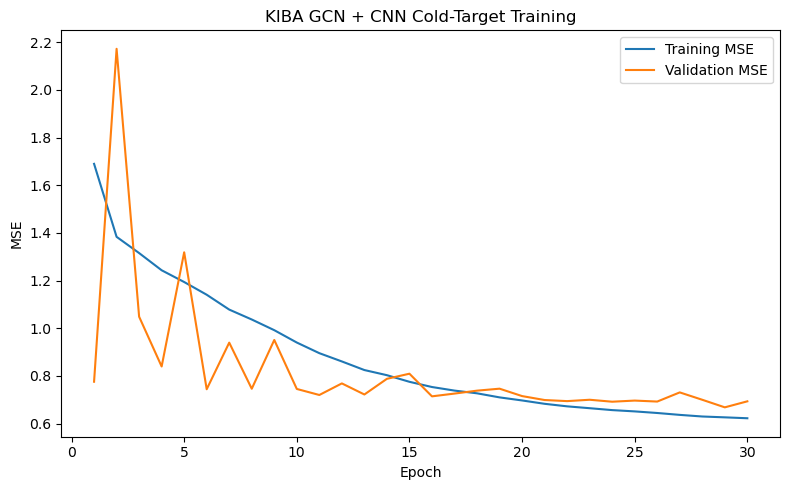

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gcn_cnn_cold_target_history.png


In [202]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gcn_cold_target_history["epoch"],
    kiba_gcn_cold_target_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gcn_cold_target_history["epoch"],
    kiba_gcn_cold_target_history[
        gcn_cold_target_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GCN + CNN Cold-Target Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gcn_cold_target_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gcn_cold_target_history_plot_path)

# Plot true versus predicted scores

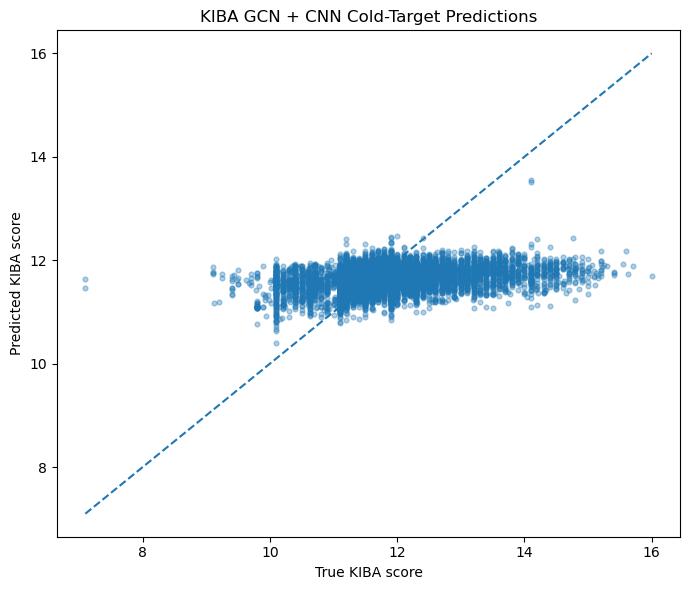

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gcn_cnn_cold_target_predictions.png


In [203]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gcn_cold_target_true_values,
    kiba_gcn_cold_target_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gcn_cold_target_true_values.min(),
    kiba_gcn_cold_target_predicted_values.min(),
)

maximum_value = max(
    kiba_gcn_cold_target_true_values.max(),
    kiba_gcn_cold_target_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GCN + CNN Cold-Target Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gcn_cold_target_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gcn_cold_target_scatter_plot_path)

# Confirm all outputs

In [204]:
kiba_gcn_cold_target_outputs = [
    kiba_gcn_cold_target_checkpoint,
    kiba_gcn_cold_target_history_path,
    kiba_gcn_cold_target_metrics_path,
    kiba_gcn_cold_target_predictions_path,
    kiba_gcn_cold_target_history_plot_path,
    kiba_gcn_cold_target_scatter_plot_path,
]

for output_path in (
    kiba_gcn_cold_target_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_gcn_cold_target_outputs
)

print()

print(
    "KIBA GCN + CNN cold-target "
    "experiment completed successfully."
)

best_kiba_gcn_cnn_cold_target.pt → True
kiba_gcn_cnn_cold_target_history.csv → True
kiba_gcn_cnn_cold_target_metrics.json → True
kiba_gcn_cnn_cold_target_predictions.csv → True
kiba_gcn_cnn_cold_target_history.png → True
kiba_gcn_cnn_cold_target_predictions.png → True

KIBA GCN + CNN cold-target experiment completed successfully.


### KIBA Cold-Target — GAT + CNN

A fresh GAT + CNN model is trained using the same KIBA cold-target split used for GCN + CNN.

All validation and test protein targets remain unseen during training.

# Remove the previous GCN model

In [205]:
objects_to_remove = [
    "kiba_gcn_cold_target_model",
    "kiba_gcn_cold_target_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GCN cold-target objects removed.")

Previous GCN cold-target objects removed.


# Define GAT output paths

In [206]:
kiba_gat_cold_target_checkpoint = (
    MODELS_DIR
    / "best_kiba_gat_cnn_cold_target.pt"
)

kiba_gat_cold_target_history_path = (
    METRICS_DIR
    / "kiba_gat_cnn_cold_target_history.csv"
)

kiba_gat_cold_target_metrics_path = (
    METRICS_DIR
    / "kiba_gat_cnn_cold_target_metrics.json"
)

kiba_gat_cold_target_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gat_cnn_cold_target_predictions.csv"
)

kiba_gat_cold_target_history_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_cold_target_history.png"
)

kiba_gat_cold_target_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gat_cnn_cold_target_predictions.png"
)

print("Checkpoint:")
print(kiba_gat_cold_target_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_cnn_cold_target.pt


# Create a fresh GAT + CNN model

In [207]:
set_random_seed(RANDOM_SEED)

kiba_gat_cold_target_model = create_dta_model(
    model_name="gat"
).to(device)

kiba_gat_cold_target_optimizer = torch.optim.Adam(
    kiba_gat_cold_target_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gat_cold_target_parameter_count = (
    count_trainable_parameters(
        kiba_gat_cold_target_model
    )
)

print("Model: GAT + CNN")
print("Dataset: KIBA")
print("Split: cold-target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gat_cold_target_parameter_count:,}",
)

Model: GAT + CNN
Dataset: KIBA
Split: cold-target
Device: mps
Trainable parameters: 300,033


# Verify one forward pass

In [208]:
gat_cold_target_batch = next(
    iter(kiba_cold_target_train_loader)
).to(device)

kiba_gat_cold_target_model.eval()

with torch.no_grad():
    gat_cold_target_predictions = (
        kiba_gat_cold_target_model(
            gat_cold_target_batch
        )
        .view(-1)
    )

gat_cold_target_true_values = (
    gat_cold_target_batch.y.view(-1)
)

print(
    "Prediction shape:",
    gat_cold_target_predictions.shape,
)

print(
    "True-value shape:",
    gat_cold_target_true_values.shape,
)

assert gat_cold_target_predictions.shape == (
    gat_cold_target_true_values.shape
)

assert torch.isfinite(
    gat_cold_target_predictions
).all()

del gat_cold_target_batch
del gat_cold_target_predictions
del gat_cold_target_true_values

if device.type == "mps":
    torch.mps.empty_cache()

print("GAT cold-target forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT cold-target forward pass successful.


# Train GAT + CNN

In [209]:
kiba_gat_cold_target_start_time = (
    time.perf_counter()
)

kiba_gat_cold_target_result = fit_model(
    model=kiba_gat_cold_target_model,
    train_loader=kiba_cold_target_train_loader,
    validation_loader=(
        kiba_cold_target_validation_loader
    ),
    optimizer=kiba_gat_cold_target_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gat_cold_target_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gat_cold_target_end_time = (
    time.perf_counter()
)

kiba_gat_cold_target_runtime_minutes = (
    kiba_gat_cold_target_end_time
    - kiba_gat_cold_target_start_time
) / 60

print()

print(
    "Training time:",
    round(
        kiba_gat_cold_target_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.7005 | Validation MSE: 0.7227 | RMSE: 0.8501 | MAE: 0.5931
Epoch 002 | Train MSE: 1.3103 | Validation MSE: 0.7461 | RMSE: 0.8638 | MAE: 0.6290
Epoch 003 | Train MSE: 1.2463 | Validation MSE: 0.7198 | RMSE: 0.8484 | MAE: 0.5862
Epoch 004 | Train MSE: 1.1643 | Validation MSE: 0.7881 | RMSE: 0.8877 | MAE: 0.6786
Epoch 005 | Train MSE: 1.1111 | Validation MSE: 0.8099 | RMSE: 0.8999 | MAE: 0.5915
Epoch 006 | Train MSE: 1.0660 | Validation MSE: 0.7216 | RMSE: 0.8494 | MAE: 0.5834
Epoch 007 | Train MSE: 1.0138 | Validation MSE: 0.7364 | RMSE: 0.8581 | MAE: 0.6317
Epoch 008 | Train MSE: 0.9579 | Validation MSE: 0.7397 | RMSE: 0.8601 | MAE: 0.5789
Epoch 009 | Train MSE: 0.9209 | Validation MSE: 0.7129 | RMSE: 0.8443 | MAE: 0.5671
Epoch 010 | Train MSE: 0.8769 | Validation MSE: 0.6667 | RMSE: 0.8165 | MAE: 0.5679
Epoch 011 | Train MSE: 0.8475 | Validation MSE: 0.7167 | RMSE: 0.8466 | MAE: 0.5659
Epoch 012 | Train MSE: 0.8167 | Validation MSE: 0.6885 | RMSE: 0.8297 | MAE:

# Inspect the result safely

In [210]:
print(
    "Available result keys:",
    kiba_gat_cold_target_result.keys(),
)

kiba_gat_cold_target_history = pd.DataFrame(
    kiba_gat_cold_target_result["history"]
)

if (
    "validation_mse"
    in kiba_gat_cold_target_history.columns
):
    gat_cold_target_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gat_cold_target_history.columns
):
    gat_cold_target_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gat_cold_target_history.columns.tolist()}"
    )

gat_cold_target_best_index = (
    kiba_gat_cold_target_history[
        gat_cold_target_validation_column
    ].idxmin()
)

kiba_gat_cold_target_best_mse = (
    kiba_gat_cold_target_result.get(
        "best_validation_mse"
    )
)

if kiba_gat_cold_target_best_mse is None:
    kiba_gat_cold_target_best_mse = (
        kiba_gat_cold_target_result.get(
            "best_val_mse"
        )
    )

if kiba_gat_cold_target_best_mse is None:
    kiba_gat_cold_target_best_mse = float(
        kiba_gat_cold_target_history.loc[
            gat_cold_target_best_index,
            gat_cold_target_validation_column,
        ]
    )

kiba_gat_cold_target_best_epoch = (
    kiba_gat_cold_target_result.get(
        "best_epoch"
    )
)

if kiba_gat_cold_target_best_epoch is None:
    kiba_gat_cold_target_best_epoch = int(
        kiba_gat_cold_target_history.loc[
            gat_cold_target_best_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gat_cold_target_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gat_cold_target_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gat_cold_target_history),
)

print(
    "Checkpoint exists:",
    kiba_gat_cold_target_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 30
Best validation MSE: 0.5469
Completed epochs: 30
Checkpoint exists: True


# Save the training history

In [211]:
display(
    kiba_gat_cold_target_history.tail()
)

kiba_gat_cold_target_history.to_csv(
    kiba_gat_cold_target_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gat_cold_target_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.593479,0.579532,0.761270,0.546470,0.670777,0.490845
26,27,0.584628,0.560292,0.748526,0.534606,0.681597,0.514505
27,28,0.571141,0.582728,0.763366,0.517781,0.670405,0.508644
28,29,0.557510,0.558357,0.747233,0.513580,0.679903,0.510386
29,30,0.549550,0.546912,0.739535,0.505015,0.679954,0.526597


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_cnn_cold_target_history.csv


# Load the best checkpoint

In [212]:
load_checkpoint(
    model=kiba_gat_cold_target_model,
    checkpoint_path=(
        kiba_gat_cold_target_checkpoint
    ),
    device=device,
)

kiba_gat_cold_target_model.eval()

print("Best GAT cold-target checkpoint loaded.")

Best GAT cold-target checkpoint loaded.


# Evaluate on unseen test targets

In [213]:
kiba_gat_cold_target_metrics = evaluate_model(
    model=kiba_gat_cold_target_model,
    data_loader=kiba_cold_target_test_loader,
    device=device,
)

print("KIBA GAT cold-target test results")
print("----------------------------------")

for metric_name, metric_value in (
    kiba_gat_cold_target_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GAT cold-target test results
----------------------------------
mse : 0.4769
rmse : 0.6906
mae : 0.4915
concordance_index : 0.6042
pearson_correlation : 0.3836


# Save the metrics

In [214]:
kiba_gat_cold_target_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gat_cold_target_metrics.items()
}

kiba_gat_cold_target_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GAT + CNN",
        "model_name": "gat",
        "split_type": "cold_target",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gat_cold_target_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gat_cold_target_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gat_cold_target_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gat_cold_target_parameter_count
        ),
    }
)

with open(
    kiba_gat_cold_target_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gat_cold_target_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gat_cold_target_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gat_cnn_cold_target_metrics.json


# Generate test predictions

In [215]:
kiba_gat_cold_target_true_values = []
kiba_gat_cold_target_predicted_values = []

kiba_gat_cold_target_model.eval()

with torch.no_grad():
    for batch in kiba_cold_target_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gat_cold_target_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gat_cold_target_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gat_cold_target_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gat_cold_target_true_values = np.asarray(
    kiba_gat_cold_target_true_values
)

kiba_gat_cold_target_predicted_values = np.asarray(
    kiba_gat_cold_target_predicted_values
)

assert len(
    kiba_gat_cold_target_true_values
) == len(
    kiba_cold_target_test_df
)

assert len(
    kiba_gat_cold_target_predicted_values
) == len(
    kiba_cold_target_test_df
)

print(
    "Prediction count:",
    len(
        kiba_gat_cold_target_predicted_values
    ),
)

Prediction count: 16777


# Save the prediction table

In [216]:
kiba_gat_cold_target_predictions_df = (
    kiba_cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gat_cold_target_predictions_df[
    "true_affinity"
] = kiba_gat_cold_target_true_values

kiba_gat_cold_target_predictions_df[
    "predicted_affinity"
] = kiba_gat_cold_target_predicted_values

kiba_gat_cold_target_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gat_cold_target_predictions_df[
        "true_affinity"
    ]
    - kiba_gat_cold_target_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gat_cold_target_predictions_df.to_csv(
    kiba_gat_cold_target_predictions_path,
    index=False,
)

display(
    kiba_gat_cold_target_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gat_cold_target_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1087421,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.320799,1.220798
1,kiba,CHEMBL1087421,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,12.199999,12.199999,KIBA_score,12.199999,11.319803,0.880196
2,kiba,CHEMBL1088633,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.330879,1.230879
3,kiba,CHEMBL1088633,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,11.999998,11.999998,KIBA_score,11.999998,11.329773,0.670225
4,kiba,CHEMBL1090360,O60674,C1COCCN1C2=CC(=CC=C2)NC3=NC=CC(=N3)C4=C(N=C5N4...,MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHS...,12.175287,12.175287,KIBA_score,12.175287,11.759856,0.415431


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gat_cnn_cold_target_predictions.csv


# Plot the training history

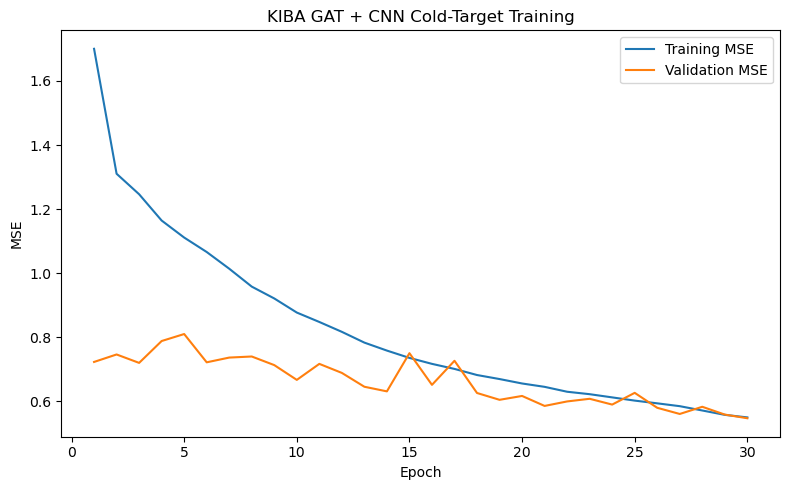

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_cnn_cold_target_history.png


In [217]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gat_cold_target_history["epoch"],
    kiba_gat_cold_target_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gat_cold_target_history["epoch"],
    kiba_gat_cold_target_history[
        gat_cold_target_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GAT + CNN Cold-Target Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gat_cold_target_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gat_cold_target_history_plot_path)

# Plot true versus predicted scores

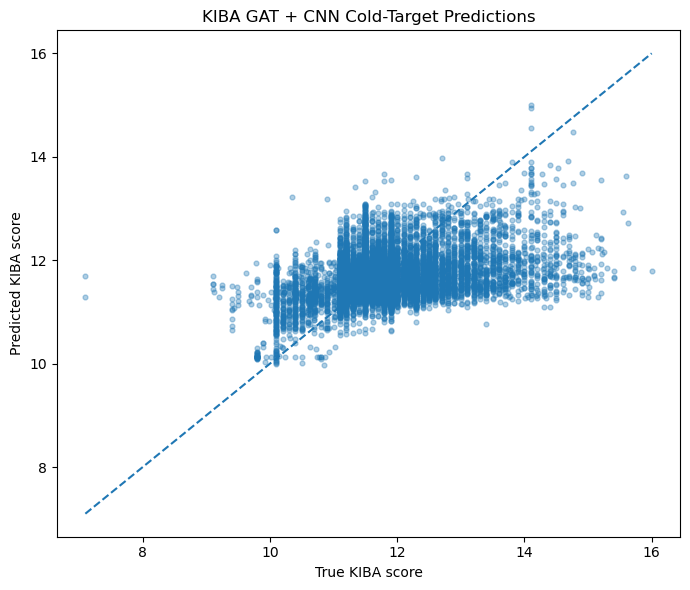

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gat_cnn_cold_target_predictions.png


In [218]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gat_cold_target_true_values,
    kiba_gat_cold_target_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gat_cold_target_true_values.min(),
    kiba_gat_cold_target_predicted_values.min(),
)

maximum_value = max(
    kiba_gat_cold_target_true_values.max(),
    kiba_gat_cold_target_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GAT + CNN Cold-Target Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gat_cold_target_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gat_cold_target_scatter_plot_path)

# Confirm all outputs

In [219]:
kiba_gat_cold_target_outputs = [
    kiba_gat_cold_target_checkpoint,
    kiba_gat_cold_target_history_path,
    kiba_gat_cold_target_metrics_path,
    kiba_gat_cold_target_predictions_path,
    kiba_gat_cold_target_history_plot_path,
    kiba_gat_cold_target_scatter_plot_path,
]

for output_path in (
    kiba_gat_cold_target_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_gat_cold_target_outputs
)

print()

print(
    "KIBA GAT + CNN cold-target "
    "experiment completed successfully."
)

best_kiba_gat_cnn_cold_target.pt → True
kiba_gat_cnn_cold_target_history.csv → True
kiba_gat_cnn_cold_target_metrics.json → True
kiba_gat_cnn_cold_target_predictions.csv → True
kiba_gat_cnn_cold_target_history.png → True
kiba_gat_cnn_cold_target_predictions.png → True

KIBA GAT + CNN cold-target experiment completed successfully.


### KIBA GAT Cold-Target Experiment Complete

GAT + CNN was trained and evaluated using unseen KIBA protein targets.

The next experiment will train GIN + CNN using the identical cold-target split.

### KIBA Cold-Target — GIN + CNN

A fresh GIN + CNN model is trained using the same KIBA cold-target split used for GCN + CNN and GAT + CNN.

All validation and test protein targets remain unseen during training.

# Remove the previous GAT model

In [220]:
objects_to_remove = [
    "kiba_gat_cold_target_model",
    "kiba_gat_cold_target_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GAT cold-target objects removed.")

Previous GAT cold-target objects removed.


# Define GIN output paths

In [221]:
kiba_gin_cold_target_checkpoint = (
    MODELS_DIR
    / "best_kiba_gin_cnn_cold_target.pt"
)

kiba_gin_cold_target_history_path = (
    METRICS_DIR
    / "kiba_gin_cnn_cold_target_history.csv"
)

kiba_gin_cold_target_metrics_path = (
    METRICS_DIR
    / "kiba_gin_cnn_cold_target_metrics.json"
)

kiba_gin_cold_target_predictions_path = (
    PREDICTIONS_DIR
    / "kiba_gin_cnn_cold_target_predictions.csv"
)

kiba_gin_cold_target_history_plot_path = (
    PLOTS_DIR
    / "kiba_gin_cnn_cold_target_history.png"
)

kiba_gin_cold_target_scatter_plot_path = (
    PLOTS_DIR
    / "kiba_gin_cnn_cold_target_predictions.png"
)

print("Checkpoint:")
print(kiba_gin_cold_target_checkpoint)

Checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gin_cnn_cold_target.pt


# Create a fresh GIN + CNN model

In [222]:
set_random_seed(RANDOM_SEED)

kiba_gin_cold_target_model = create_dta_model(
    model_name="gin"
).to(device)

kiba_gin_cold_target_optimizer = torch.optim.Adam(
    kiba_gin_cold_target_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

kiba_gin_cold_target_parameter_count = (
    count_trainable_parameters(
        kiba_gin_cold_target_model
    )
)

print("Model: GIN + CNN")
print("Dataset: KIBA")
print("Split: cold-target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{kiba_gin_cold_target_parameter_count:,}",
)

Model: GIN + CNN
Dataset: KIBA
Split: cold-target
Device: mps
Trainable parameters: 348,801


# Verify one forward pass

In [223]:
gin_cold_target_batch = next(
    iter(kiba_cold_target_train_loader)
).to(device)

kiba_gin_cold_target_model.eval()

with torch.no_grad():
    gin_cold_target_predictions = (
        kiba_gin_cold_target_model(
            gin_cold_target_batch
        )
        .view(-1)
    )

gin_cold_target_labels = (
    gin_cold_target_batch.y.view(-1)
)

print(
    "Prediction shape:",
    gin_cold_target_predictions.shape,
)

print(
    "True-value shape:",
    gin_cold_target_labels.shape,
)

assert gin_cold_target_predictions.shape == (
    gin_cold_target_labels.shape
)

assert torch.isfinite(
    gin_cold_target_predictions
).all()

del gin_cold_target_batch
del gin_cold_target_predictions
del gin_cold_target_labels

if device.type == "mps":
    torch.mps.empty_cache()

print("GIN cold-target forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GIN cold-target forward pass successful.


# Train GIN + CNN

In [224]:
kiba_gin_cold_target_start_time = (
    time.perf_counter()
)

kiba_gin_cold_target_result = fit_model(
    model=kiba_gin_cold_target_model,
    train_loader=kiba_cold_target_train_loader,
    validation_loader=(
        kiba_cold_target_validation_loader
    ),
    optimizer=kiba_gin_cold_target_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=(
        kiba_gin_cold_target_checkpoint
    ),
    patience=EARLY_STOPPING_PATIENCE,
)

kiba_gin_cold_target_end_time = (
    time.perf_counter()
)

kiba_gin_cold_target_runtime_minutes = (
    kiba_gin_cold_target_end_time
    - kiba_gin_cold_target_start_time
) / 60

print()

print(
    "Training time:",
    round(
        kiba_gin_cold_target_runtime_minutes,
        2,
    ),
    "minutes",
)

Epoch 001 | Train MSE: 1.7300 | Validation MSE: 1.7671 | RMSE: 1.3293 | MAE: 1.0905
Epoch 002 | Train MSE: 1.4191 | Validation MSE: 1.9052 | RMSE: 1.3803 | MAE: 1.1391
Epoch 003 | Train MSE: 1.3455 | Validation MSE: 1.2408 | RMSE: 1.1139 | MAE: 0.8396
Epoch 004 | Train MSE: 1.3030 | Validation MSE: 1.7543 | RMSE: 1.3245 | MAE: 1.0819
Epoch 005 | Train MSE: 1.2140 | Validation MSE: 1.4655 | RMSE: 1.2106 | MAE: 0.9423
Epoch 006 | Train MSE: 1.1418 | Validation MSE: 1.8218 | RMSE: 1.3497 | MAE: 1.1112
Epoch 007 | Train MSE: 1.1084 | Validation MSE: 0.9546 | RMSE: 0.9770 | MAE: 0.6886
Epoch 008 | Train MSE: 1.0431 | Validation MSE: 1.1857 | RMSE: 1.0889 | MAE: 0.8319
Epoch 009 | Train MSE: 0.9735 | Validation MSE: 0.7797 | RMSE: 0.8830 | MAE: 0.5843
Epoch 010 | Train MSE: 0.9213 | Validation MSE: 0.6583 | RMSE: 0.8113 | MAE: 0.5673
Epoch 011 | Train MSE: 0.8750 | Validation MSE: 0.6661 | RMSE: 0.8161 | MAE: 0.5453
Epoch 012 | Train MSE: 0.8386 | Validation MSE: 0.6752 | RMSE: 0.8217 | MAE:

# Inspect the result safely

In [225]:
print(
    "Available result keys:",
    kiba_gin_cold_target_result.keys(),
)

kiba_gin_cold_target_history = pd.DataFrame(
    kiba_gin_cold_target_result["history"]
)

if (
    "validation_mse"
    in kiba_gin_cold_target_history.columns
):
    gin_cold_target_validation_column = (
        "validation_mse"
    )

elif (
    "val_mse"
    in kiba_gin_cold_target_history.columns
):
    gin_cold_target_validation_column = (
        "val_mse"
    )

else:
    raise KeyError(
        "No validation MSE column found. "
        f"Available columns: "
        f"{kiba_gin_cold_target_history.columns.tolist()}"
    )

gin_cold_target_best_index = (
    kiba_gin_cold_target_history[
        gin_cold_target_validation_column
    ].idxmin()
)

kiba_gin_cold_target_best_mse = (
    kiba_gin_cold_target_result.get(
        "best_validation_mse"
    )
)

if kiba_gin_cold_target_best_mse is None:
    kiba_gin_cold_target_best_mse = (
        kiba_gin_cold_target_result.get(
            "best_val_mse"
        )
    )

if kiba_gin_cold_target_best_mse is None:
    kiba_gin_cold_target_best_mse = float(
        kiba_gin_cold_target_history.loc[
            gin_cold_target_best_index,
            gin_cold_target_validation_column,
        ]
    )

kiba_gin_cold_target_best_epoch = (
    kiba_gin_cold_target_result.get(
        "best_epoch"
    )
)

if kiba_gin_cold_target_best_epoch is None:
    kiba_gin_cold_target_best_epoch = int(
        kiba_gin_cold_target_history.loc[
            gin_cold_target_best_index,
            "epoch",
        ]
    )

print(
    "Best epoch:",
    kiba_gin_cold_target_best_epoch,
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_gin_cold_target_best_mse
        ),
        4,
    ),
)

print(
    "Completed epochs:",
    len(kiba_gin_cold_target_history),
)

print(
    "Checkpoint exists:",
    kiba_gin_cold_target_checkpoint.exists(),
)

Available result keys: dict_keys(['model', 'history', 'best_epoch', 'best_validation_metrics', 'checkpoint_path'])
Best epoch: 29
Best validation MSE: 0.5565
Completed epochs: 30
Checkpoint exists: True


# Save the training history

In [226]:
display(
    kiba_gin_cold_target_history.tail()
)

kiba_gin_cold_target_history.to_csv(
    kiba_gin_cold_target_history_path,
    index=False,
)

print("History saved to:")
print(kiba_gin_cold_target_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.585442,0.561211,0.749140,0.515496,0.676478,0.506119
26,27,0.579492,0.576226,0.759095,0.546536,0.679446,0.516317
27,28,0.572626,0.574152,0.757728,0.550667,0.670021,0.506049
28,29,0.564251,0.556511,0.745997,0.507419,0.669819,0.520769
29,30,0.550208,0.567271,0.753174,0.504306,0.675400,0.515104


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gin_cnn_cold_target_history.csv


# Load the best checkpoint

In [227]:
load_checkpoint(
    model=kiba_gin_cold_target_model,
    checkpoint_path=(
        kiba_gin_cold_target_checkpoint
    ),
    device=device,
)

kiba_gin_cold_target_model.eval()

print("Best GIN cold-target checkpoint loaded.")

Best GIN cold-target checkpoint loaded.


# Evaluate on unseen test targets

In [228]:
kiba_gin_cold_target_metrics = evaluate_model(
    model=kiba_gin_cold_target_model,
    data_loader=kiba_cold_target_test_loader,
    device=device,
)

print("KIBA GIN cold-target test results")
print("----------------------------------")

for metric_name, metric_value in (
    kiba_gin_cold_target_metrics.items()
):
    print(
        metric_name,
        ":",
        round(float(metric_value), 4),
    )

KIBA GIN cold-target test results
----------------------------------
mse : 0.4917
rmse : 0.7012
mae : 0.4853
concordance_index : 0.6096
pearson_correlation : 0.4043


# Save the metrics

In [229]:
kiba_gin_cold_target_metrics_to_save = {
    metric_name: float(metric_value)
    for metric_name, metric_value
    in kiba_gin_cold_target_metrics.items()
}

kiba_gin_cold_target_metrics_to_save.update(
    {
        "dataset": "kiba",
        "model": "GIN + CNN",
        "model_name": "gin",
        "split_type": "cold_target",
        "random_seed": int(RANDOM_SEED),
        "best_epoch": int(
            kiba_gin_cold_target_best_epoch
        ),
        "best_validation_mse": float(
            kiba_gin_cold_target_best_mse
        ),
        "training_runtime_minutes": float(
            kiba_gin_cold_target_runtime_minutes
        ),
        "trainable_parameters": int(
            kiba_gin_cold_target_parameter_count
        ),
    }
)

with open(
    kiba_gin_cold_target_metrics_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        kiba_gin_cold_target_metrics_to_save,
        file,
        indent=4,
    )

print("Metrics saved to:")
print(kiba_gin_cold_target_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_gin_cnn_cold_target_metrics.json


# Generate test predictions

In [230]:
kiba_gin_cold_target_true_values = []
kiba_gin_cold_target_predicted_values = []

kiba_gin_cold_target_model.eval()

with torch.no_grad():
    for batch in kiba_cold_target_test_loader:
        batch = batch.to(device)

        batch_predictions = (
            kiba_gin_cold_target_model(batch)
            .view(-1)
        )

        batch_true_values = (
            batch.y
            .view(-1)
        )

        kiba_gin_cold_target_predicted_values.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        kiba_gin_cold_target_true_values.extend(
            batch_true_values
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

kiba_gin_cold_target_true_values = np.asarray(
    kiba_gin_cold_target_true_values
)

kiba_gin_cold_target_predicted_values = np.asarray(
    kiba_gin_cold_target_predicted_values
)

assert len(
    kiba_gin_cold_target_true_values
) == len(
    kiba_cold_target_test_df
)

assert len(
    kiba_gin_cold_target_predicted_values
) == len(
    kiba_cold_target_test_df
)

print(
    "Prediction count:",
    len(
        kiba_gin_cold_target_predicted_values
    ),
)

Prediction count: 16777


# Save the prediction table

In [231]:
kiba_gin_cold_target_predictions_df = (
    kiba_cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

kiba_gin_cold_target_predictions_df[
    "true_affinity"
] = kiba_gin_cold_target_true_values

kiba_gin_cold_target_predictions_df[
    "predicted_affinity"
] = kiba_gin_cold_target_predicted_values

kiba_gin_cold_target_predictions_df[
    "absolute_error"
] = np.abs(
    kiba_gin_cold_target_predictions_df[
        "true_affinity"
    ]
    - kiba_gin_cold_target_predictions_df[
        "predicted_affinity"
    ]
)

kiba_gin_cold_target_predictions_df.to_csv(
    kiba_gin_cold_target_predictions_path,
    index=False,
)

display(
    kiba_gin_cold_target_predictions_df.head()
)

print("Predictions saved to:")
print(kiba_gin_cold_target_predictions_path)

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,kiba,CHEMBL1087421,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.333324,1.233324
1,kiba,CHEMBL1087421,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,12.199999,12.199999,KIBA_score,12.199999,11.312105,0.887894
2,kiba,CHEMBL1088633,P45983,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSRSKRDNNFYSVEIGDSTFTVLKRYQNLKPIGSGAQGIVCAAYDA...,10.100000,10.100000,KIBA_score,10.100000,11.337839,1.237839
3,kiba,CHEMBL1088633,P45984,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,MSDSKCDSQFYSVQVADSTFTVLKRYQQLKPIGSGAQGIVCAAFDT...,11.999998,11.999998,KIBA_score,11.999998,11.316619,0.683379
4,kiba,CHEMBL1090360,O60674,C1COCCN1C2=CC(=CC=C2)NC3=NC=CC(=N3)C4=C(N=C5N4...,MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHS...,12.175287,12.175287,KIBA_score,12.175287,11.685458,0.489829


Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/kiba_gin_cnn_cold_target_predictions.csv


# Plot the training history

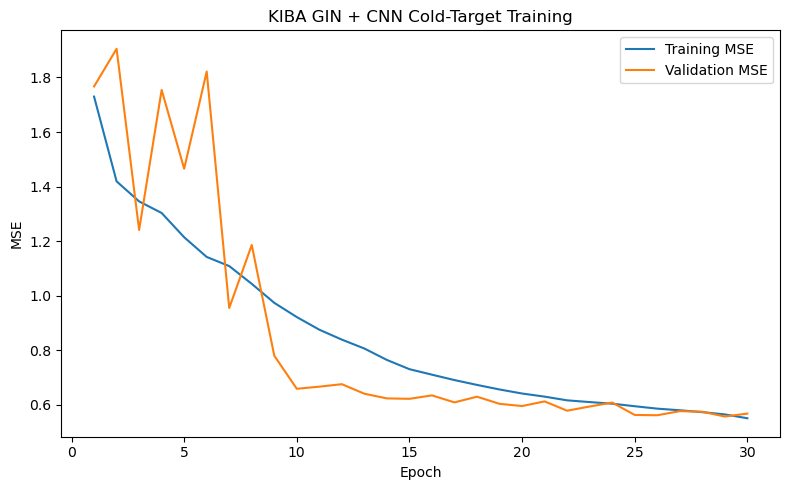

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gin_cnn_cold_target_history.png


In [232]:
plt.figure(figsize=(8, 5))

plt.plot(
    kiba_gin_cold_target_history["epoch"],
    kiba_gin_cold_target_history[
        "train_mse"
    ],
    label="Training MSE",
)

plt.plot(
    kiba_gin_cold_target_history["epoch"],
    kiba_gin_cold_target_history[
        gin_cold_target_validation_column
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.title(
    "KIBA GIN + CNN Cold-Target Training"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    kiba_gin_cold_target_history_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gin_cold_target_history_plot_path)

# Plot true versus predicted scores

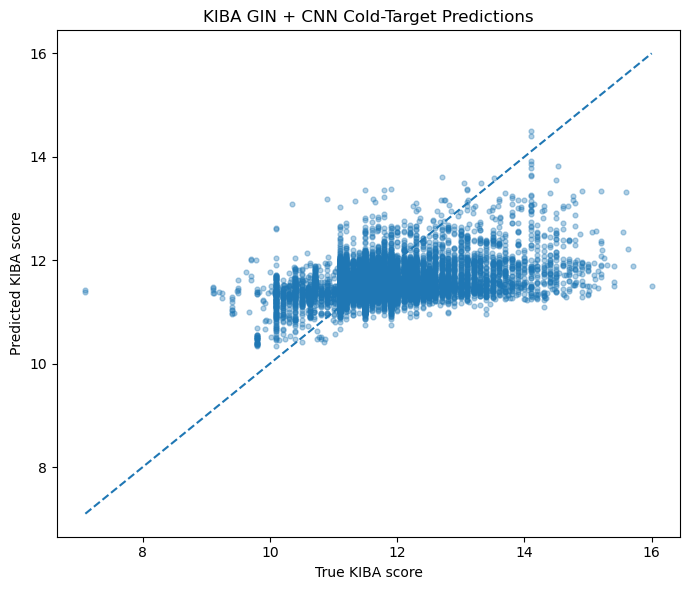

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_gin_cnn_cold_target_predictions.png


In [233]:
plt.figure(figsize=(7, 6))

plt.scatter(
    kiba_gin_cold_target_true_values,
    kiba_gin_cold_target_predicted_values,
    alpha=0.35,
    s=12,
)

minimum_value = min(
    kiba_gin_cold_target_true_values.min(),
    kiba_gin_cold_target_predicted_values.min(),
)

maximum_value = max(
    kiba_gin_cold_target_true_values.max(),
    kiba_gin_cold_target_predicted_values.max(),
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
)

plt.xlabel("True KIBA score")
plt.ylabel("Predicted KIBA score")

plt.title(
    "KIBA GIN + CNN Cold-Target Predictions"
)

plt.tight_layout()

plt.savefig(
    kiba_gin_cold_target_scatter_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_gin_cold_target_scatter_plot_path)

# Confirm all outputs

In [234]:
kiba_gin_cold_target_outputs = [
    kiba_gin_cold_target_checkpoint,
    kiba_gin_cold_target_history_path,
    kiba_gin_cold_target_metrics_path,
    kiba_gin_cold_target_predictions_path,
    kiba_gin_cold_target_history_plot_path,
    kiba_gin_cold_target_scatter_plot_path,
]

for output_path in (
    kiba_gin_cold_target_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_gin_cold_target_outputs
)

print()

print(
    "KIBA GIN + CNN cold-target "
    "experiment completed successfully."
)

best_kiba_gin_cnn_cold_target.pt → True
kiba_gin_cnn_cold_target_history.csv → True
kiba_gin_cnn_cold_target_metrics.json → True
kiba_gin_cnn_cold_target_predictions.csv → True
kiba_gin_cnn_cold_target_history.png → True
kiba_gin_cnn_cold_target_predictions.png → True

KIBA GIN + CNN cold-target experiment completed successfully.


### KIBA Cold-Target Training Complete

GCN + CNN, GAT + CNN and GIN + CNN were trained and evaluated using the same KIBA cold-target split.

The next section compares all three cold-target models using validation performance and held-out test metrics.

## KIBA Cold-Target Model Comparison

This section compares:

- GCN + CNN
- GAT + CNN
- GIN + CNN

All models used the same KIBA cold-target split, random seed and training configuration.

The preliminary winner is selected using the lowest validation MSE. Test metrics are reported after model selection.

# Load the saved cold-target metrics

In [235]:
def load_json_file(file_path):
    with open(
        file_path,
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


kiba_gcn_cold_target_saved_metrics = (
    load_json_file(
        METRICS_DIR
        / "kiba_gcn_cnn_cold_target_metrics.json"
    )
)

kiba_gat_cold_target_saved_metrics = (
    load_json_file(
        METRICS_DIR
        / "kiba_gat_cnn_cold_target_metrics.json"
    )
)

kiba_gin_cold_target_saved_metrics = (
    load_json_file(
        METRICS_DIR
        / "kiba_gin_cnn_cold_target_metrics.json"
    )
)

print(
    "GCN metrics loaded:",
    bool(kiba_gcn_cold_target_saved_metrics),
)

print(
    "GAT metrics loaded:",
    bool(kiba_gat_cold_target_saved_metrics),
)

print(
    "GIN metrics loaded:",
    bool(kiba_gin_cold_target_saved_metrics),
)

GCN metrics loaded: True
GAT metrics loaded: True
GIN metrics loaded: True


# Inspect the available keys

In [236]:
print(
    "GCN keys:",
    kiba_gcn_cold_target_saved_metrics.keys(),
)

print(
    "GAT keys:",
    kiba_gat_cold_target_saved_metrics.keys(),
)

print(
    "GIN keys:",
    kiba_gin_cold_target_saved_metrics.keys(),
)

GCN keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])
GAT keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])
GIN keys: dict_keys(['mse', 'rmse', 'mae', 'concordance_index', 'pearson_correlation', 'dataset', 'model', 'model_name', 'split_type', 'random_seed', 'best_epoch', 'best_validation_mse', 'training_runtime_minutes', 'trainable_parameters'])


# Create a robust summary helper

In [237]:
def get_cold_target_summary(
    saved_metrics,
    history_path,
):
    history_df = pd.read_csv(history_path)

    if "validation_mse" in history_df.columns:
        validation_column = "validation_mse"

    elif "val_mse" in history_df.columns:
        validation_column = "val_mse"

    else:
        raise KeyError(
            "No validation MSE column found in "
            f"{history_path.name}. "
            f"Available columns: "
            f"{history_df.columns.tolist()}"
        )

    best_history_index = (
        history_df[validation_column].idxmin()
    )

    best_validation_mse = saved_metrics.get(
        "best_validation_mse"
    )

    if best_validation_mse is None:
        best_validation_mse = saved_metrics.get(
            "best_val_mse"
        )

    if best_validation_mse is None:
        best_validation_mse = float(
            history_df.loc[
                best_history_index,
                validation_column,
            ]
        )

    best_epoch = saved_metrics.get(
        "best_epoch"
    )

    if best_epoch is None:
        best_epoch = int(
            history_df.loc[
                best_history_index,
                "epoch",
            ]
        )

    return {
        "best_epoch": int(best_epoch),
        "best_validation_mse": float(
            best_validation_mse
        ),
    }


print("Cold-target summary helper ready.")

Cold-target summary helper ready.


# Recover the three experiment summaries

In [238]:
kiba_gcn_cold_target_summary = (
    get_cold_target_summary(
        saved_metrics=(
            kiba_gcn_cold_target_saved_metrics
        ),
        history_path=(
            METRICS_DIR
            / "kiba_gcn_cnn_cold_target_history.csv"
        ),
    )
)

kiba_gat_cold_target_summary = (
    get_cold_target_summary(
        saved_metrics=(
            kiba_gat_cold_target_saved_metrics
        ),
        history_path=(
            METRICS_DIR
            / "kiba_gat_cnn_cold_target_history.csv"
        ),
    )
)

kiba_gin_cold_target_summary = (
    get_cold_target_summary(
        saved_metrics=(
            kiba_gin_cold_target_saved_metrics
        ),
        history_path=(
            METRICS_DIR
            / "kiba_gin_cnn_cold_target_history.csv"
        ),
    )
)

print(
    "GCN summary:",
    kiba_gcn_cold_target_summary,
)

print(
    "GAT summary:",
    kiba_gat_cold_target_summary,
)

print(
    "GIN summary:",
    kiba_gin_cold_target_summary,
)

GCN summary: {'best_epoch': 29, 'best_validation_mse': 0.6680205861464162}
GAT summary: {'best_epoch': 30, 'best_validation_mse': 0.5469121534426308}
GIN summary: {'best_epoch': 29, 'best_validation_mse': 0.5565114427450559}


# Create the cold-target comparison table

In [239]:
kiba_cold_target_comparison_df = pd.DataFrame(
    [
        {
            "model": "GCN + CNN",
            "model_name": "gcn",
            "split_type": "cold_target",
            "best_epoch": (
                kiba_gcn_cold_target_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gcn_cold_target_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gcn_cold_target_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gcn_cold_target_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gcn_cold_target_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gcn_cold_target_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gcn_cold_target_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gcn_cold_target_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gcn_cold_target_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
        {
            "model": "GAT + CNN",
            "model_name": "gat",
            "split_type": "cold_target",
            "best_epoch": (
                kiba_gat_cold_target_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gat_cold_target_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gat_cold_target_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gat_cold_target_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gat_cold_target_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gat_cold_target_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gat_cold_target_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gat_cold_target_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gat_cold_target_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
        {
            "model": "GIN + CNN",
            "model_name": "gin",
            "split_type": "cold_target",
            "best_epoch": (
                kiba_gin_cold_target_summary[
                    "best_epoch"
                ]
            ),
            "best_validation_mse": (
                kiba_gin_cold_target_summary[
                    "best_validation_mse"
                ]
            ),
            "test_mse": (
                kiba_gin_cold_target_saved_metrics[
                    "mse"
                ]
            ),
            "test_rmse": (
                kiba_gin_cold_target_saved_metrics[
                    "rmse"
                ]
            ),
            "test_mae": (
                kiba_gin_cold_target_saved_metrics[
                    "mae"
                ]
            ),
            "concordance_index": (
                kiba_gin_cold_target_saved_metrics[
                    "concordance_index"
                ]
            ),
            "pearson_correlation": (
                kiba_gin_cold_target_saved_metrics[
                    "pearson_correlation"
                ]
            ),
            "training_runtime_minutes": (
                kiba_gin_cold_target_saved_metrics.get(
                    "training_runtime_minutes",
                    np.nan,
                )
            ),
            "trainable_parameters": (
                kiba_gin_cold_target_saved_metrics.get(
                    "trainable_parameters",
                    np.nan,
                )
            ),
        },
    ]
)

kiba_cold_target_comparison_df = (
    kiba_cold_target_comparison_df
    .sort_values("best_validation_mse")
    .reset_index(drop=True)
)

kiba_cold_target_comparison_df.insert(
    0,
    "validation_rank",
    range(
        1,
        len(kiba_cold_target_comparison_df) + 1,
    ),
)

display(
    kiba_cold_target_comparison_df.round(4)
)

,validation_rank,model,model_name,split_type,best_epoch,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,training_runtime_minutes,trainable_parameters
0,1,GAT + CNN,gat,cold_target,30,0.5469,0.4769,0.6906,0.4915,0.6042,0.3836,90.3369,300033
1,2,GIN + CNN,gin,cold_target,29,0.5565,0.4917,0.7012,0.4853,0.6096,0.4043,70.0889,348801
2,3,GCN + CNN,gcn,cold_target,29,0.6680,0.4951,0.7036,0.4748,0.6175,0.3100,79.1072,299265


# Validate the comparison table

In [240]:
required_cold_target_columns = [
    "best_validation_mse",
    "test_mse",
    "test_rmse",
    "test_mae",
    "concordance_index",
    "pearson_correlation",
]

assert len(
    kiba_cold_target_comparison_df
) == 3

assert all(
    column_name
    in kiba_cold_target_comparison_df.columns
    for column_name
    in required_cold_target_columns
)

assert np.isfinite(
    kiba_cold_target_comparison_df[
        required_cold_target_columns
    ].to_numpy(dtype=float)
).all()

print(
    "KIBA cold-target comparison "
    "table validated."
)

KIBA cold-target comparison table validated.


# Show the preliminary cold-target winner

In [241]:
kiba_cold_target_best_model = (
    kiba_cold_target_comparison_df.iloc[0]
)

print("KIBA cold-target preliminary winner")
print("-----------------------------------")

print(
    "Model:",
    kiba_cold_target_best_model["model"],
)

print(
    "Best validation MSE:",
    round(
        float(
            kiba_cold_target_best_model[
                "best_validation_mse"
            ]
        ),
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        float(
            kiba_cold_target_best_model[
                "test_rmse"
            ]
        ),
        4,
    ),
)

print(
    "Test MAE:",
    round(
        float(
            kiba_cold_target_best_model[
                "test_mae"
            ]
        ),
        4,
    ),
)

print(
    "Concordance index:",
    round(
        float(
            kiba_cold_target_best_model[
                "concordance_index"
            ]
        ),
        4,
    ),
)

print(
    "Pearson correlation:",
    round(
        float(
            kiba_cold_target_best_model[
                "pearson_correlation"
            ]
        ),
        4,
    ),
)

KIBA cold-target preliminary winner
-----------------------------------
Model: GAT + CNN
Best validation MSE: 0.5469
Test RMSE: 0.6906
Test MAE: 0.4915
Concordance index: 0.6042
Pearson correlation: 0.3836


# Save the comparison table

In [242]:
kiba_cold_target_comparison_path = (
    METRICS_DIR
    / "kiba_cold_target_model_comparison.csv"
)

kiba_cold_target_comparison_df.to_csv(
    kiba_cold_target_comparison_path,
    index=False,
)

print("Comparison saved to:")
print(kiba_cold_target_comparison_path)

Comparison saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/kiba_cold_target_model_comparison.csv


# Plot test RMSE

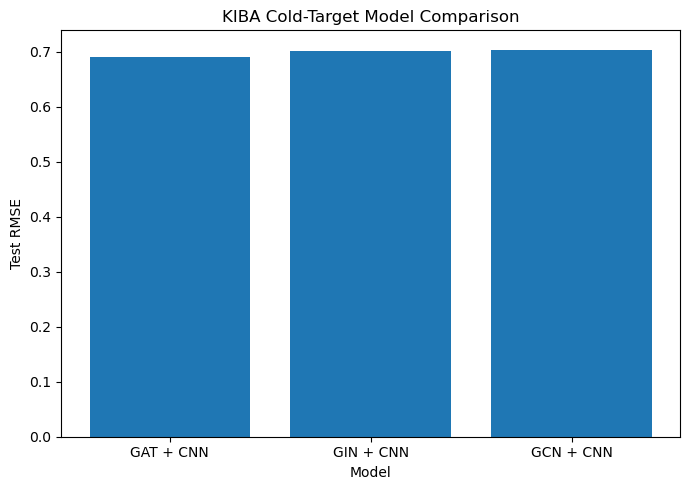

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_cold_target_rmse_comparison.png


In [243]:
plt.figure(figsize=(7, 5))

plt.bar(
    kiba_cold_target_comparison_df["model"],
    kiba_cold_target_comparison_df[
        "test_rmse"
    ],
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")

plt.title(
    "KIBA Cold-Target Model Comparison"
)

plt.tight_layout()

kiba_cold_target_rmse_plot_path = (
    PLOTS_DIR
    / "kiba_cold_target_rmse_comparison.png"
)

plt.savefig(
    kiba_cold_target_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_cold_target_rmse_plot_path)

# Plot concordance index

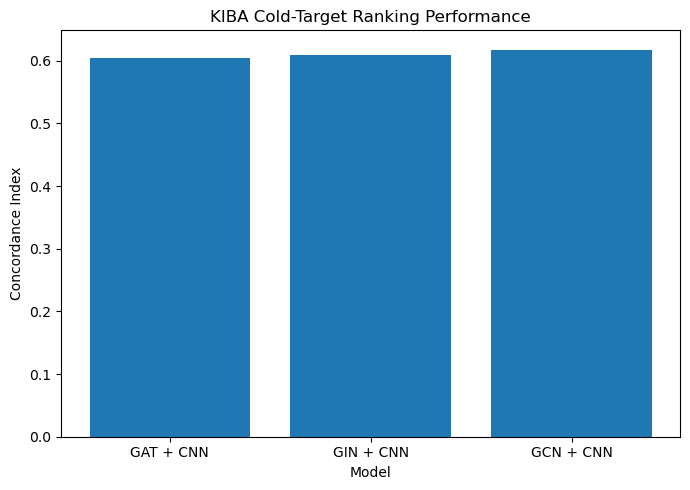

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_cold_target_ci_comparison.png


In [244]:
plt.figure(figsize=(7, 5))

plt.bar(
    kiba_cold_target_comparison_df["model"],
    kiba_cold_target_comparison_df[
        "concordance_index"
    ],
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")

plt.title(
    "KIBA Cold-Target Ranking Performance"
)

plt.tight_layout()

kiba_cold_target_ci_plot_path = (
    PLOTS_DIR
    / "kiba_cold_target_ci_comparison.png"
)

plt.savefig(
    kiba_cold_target_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_cold_target_ci_plot_path)

# Show computational comparison

In [245]:
kiba_cold_target_runtime_df = (
    kiba_cold_target_comparison_df[
        [
            "model",
            "best_epoch",
            "training_runtime_minutes",
            "trainable_parameters",
        ]
    ]
    .copy()
)

display(
    kiba_cold_target_runtime_df.round(2)
)

,model,best_epoch,training_runtime_minutes,trainable_parameters
0,GAT + CNN,30,90.34,300033
1,GIN + CNN,29,70.09,348801
2,GCN + CNN,29,79.11,299265


# Confirm all outputs

In [246]:
kiba_cold_target_comparison_outputs = [
    kiba_cold_target_comparison_path,
    kiba_cold_target_rmse_plot_path,
    kiba_cold_target_ci_plot_path,
]

for output_path in (
    kiba_cold_target_comparison_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in kiba_cold_target_comparison_outputs
)

print()

print(
    "KIBA cold-target model comparison "
    "completed successfully."
)

kiba_cold_target_model_comparison.csv → True
kiba_cold_target_rmse_comparison.png → True
kiba_cold_target_ci_comparison.png → True

KIBA cold-target model comparison completed successfully.


### KIBA Cold-Target Comparison Complete

GCN + CNN, GAT + CNN and GIN + CNN were compared using the same KIBA cold-target split.

The preliminary cold-target winner was selected using validation MSE.

The next section combines the random, cold-drug and cold-target KIBA results to evaluate overall model robustness.

## Final KIBA Comparison Across Split Types

This section combines results from:

- random splitting;
- cold-drug splitting;
- cold-target splitting.

The analysis compares prediction error, ranking performance and cold-start generalisation for GCN + CNN, GAT + CNN and GIN + CNN.

# Load the three KIBA comparison tables

In [247]:
kiba_random_comparison_df = pd.read_csv(
    METRICS_DIR
    / "kiba_random_model_comparison.csv"
)

kiba_cold_drug_comparison_df = pd.read_csv(
    METRICS_DIR
    / "kiba_cold_drug_model_comparison.csv"
)

kiba_cold_target_comparison_df = pd.read_csv(
    METRICS_DIR
    / "kiba_cold_target_model_comparison.csv"
)

print(
    "Random comparison:",
    kiba_random_comparison_df.shape,
)

print(
    "Cold-drug comparison:",
    kiba_cold_drug_comparison_df.shape,
)

print(
    "Cold-target comparison:",
    kiba_cold_target_comparison_df.shape,
)

Random comparison: (3, 13)
Cold-drug comparison: (3, 13)
Cold-target comparison: (3, 13)


# Standardise and validate the tables

In [248]:
kiba_random_comparison_df[
    "split_type"
] = "random"

kiba_cold_drug_comparison_df[
    "split_type"
] = "cold_drug"

kiba_cold_target_comparison_df[
    "split_type"
] = "cold_target"

required_kiba_columns = [
    "validation_rank",
    "model",
    "model_name",
    "split_type",
    "best_epoch",
    "best_validation_mse",
    "test_mse",
    "test_rmse",
    "test_mae",
    "concordance_index",
    "pearson_correlation",
]

for table_name, table_df in {
    "random": kiba_random_comparison_df,
    "cold_drug": kiba_cold_drug_comparison_df,
    "cold_target": kiba_cold_target_comparison_df,
}.items():

    missing_columns = [
        column_name
        for column_name in required_kiba_columns
        if column_name not in table_df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{table_name} table is missing: "
            f"{missing_columns}"
        )

print("All KIBA comparison tables validated.")

All KIBA comparison tables validated.


# Combine all nine KIBA results

In [249]:
kiba_all_splits_df = pd.concat(
    [
        kiba_random_comparison_df,
        kiba_cold_drug_comparison_df,
        kiba_cold_target_comparison_df,
    ],
    ignore_index=True,
)

split_order = [
    "random",
    "cold_drug",
    "cold_target",
]

kiba_all_splits_df[
    "split_type"
] = pd.Categorical(
    kiba_all_splits_df["split_type"],
    categories=split_order,
    ordered=True,
)

kiba_all_splits_df = (
    kiba_all_splits_df
    .sort_values(
        [
            "split_type",
            "validation_rank",
        ]
    )
    .reset_index(drop=True)
)

display(
    kiba_all_splits_df[
        [
            "split_type",
            "validation_rank",
            "model",
            "best_validation_mse",
            "test_rmse",
            "test_mae",
            "concordance_index",
            "pearson_correlation",
        ]
    ].round(4)
)

,split_type,validation_rank,model,best_validation_mse,test_rmse,test_mae,concordance_index,pearson_correlation
0,random,1,GAT + CNN,0.4587,0.6760,0.4760,0.7295,0.5918
1,random,2,GIN + CNN,0.5023,0.7039,0.4705,0.7136,0.5354
2,random,3,GCN + CNN,0.6412,0.7995,0.5167,0.6568,0.3256
3,cold_drug,1,GAT + CNN,0.4838,0.7238,0.4946,0.7002,0.5092
4,cold_drug,2,GCN + CNN,0.6043,0.7657,0.5004,0.6786,0.4110
5,cold_drug,3,GIN + CNN,0.6645,0.8176,0.5408,0.6377,0.2869
6,cold_target,1,GAT + CNN,0.5469,0.6906,0.4915,0.6042,0.3836
7,cold_target,2,GIN + CNN,0.5565,0.7012,0.4853,0.6096,0.4043
8,cold_target,3,GCN + CNN,0.6680,0.7036,0.4748,0.6175,0.3100


# Identify the validation winner for each split

In [250]:
kiba_split_winners_df = (
    kiba_all_splits_df[
        kiba_all_splits_df[
            "validation_rank"
        ] == 1
    ]
    [
        [
            "split_type",
            "model",
            "best_validation_mse",
            "test_rmse",
            "test_mae",
            "concordance_index",
            "pearson_correlation",
        ]
    ]
    .reset_index(drop=True)
)

display(
    kiba_split_winners_df.round(4)
)

,split_type,model,best_validation_mse,test_rmse,test_mae,concordance_index,pearson_correlation
0,random,GAT + CNN,0.4587,0.6760,0.4760,0.7295,0.5918
1,cold_drug,GAT + CNN,0.4838,0.7238,0.4946,0.7002,0.5092
2,cold_target,GAT + CNN,0.5469,0.6906,0.4915,0.6042,0.3836


# Create the KIBA RMSE comparison table

In [251]:
kiba_rmse_table = (
    kiba_all_splits_df
    .pivot(
        index="model",
        columns="split_type",
        values="test_rmse",
    )
)

kiba_rmse_table = kiba_rmse_table[
    [
        "random",
        "cold_drug",
        "cold_target",
    ]
]

display(
    kiba_rmse_table.round(4)
)

split_type,random,cold_drug,cold_target
model,,,
GAT + CNN,0.6760,0.7238,0.6906
GCN + CNN,0.7995,0.7657,0.7036
GIN + CNN,0.7039,0.8176,0.7012


# Calculate cold-start RMSE changes

In [252]:
kiba_generalisation_gap_df = (
    kiba_rmse_table
    .reset_index()
)

kiba_generalisation_gap_df[
    "cold_drug_rmse_change"
] = (
    kiba_generalisation_gap_df[
        "cold_drug"
    ]
    - kiba_generalisation_gap_df[
        "random"
    ]
)

kiba_generalisation_gap_df[
    "cold_target_rmse_change"
] = (
    kiba_generalisation_gap_df[
        "cold_target"
    ]
    - kiba_generalisation_gap_df[
        "random"
    ]
)

display(
    kiba_generalisation_gap_df.round(4)
)

split_type,model,random,cold_drug,cold_target,cold_drug_rmse_change,cold_target_rmse_change
0,GAT + CNN,0.6760,0.7238,0.6906,0.0478,0.0146
1,GCN + CNN,0.7995,0.7657,0.7036,-0.0339,-0.0959
2,GIN + CNN,0.7039,0.8176,0.7012,0.1137,-0.0027


# Create the KIBA robustness summary

In [253]:
kiba_robustness_summary_df = (
    kiba_all_splits_df
    .groupby(
        "model",
        observed=True,
    )
    .agg(
        average_validation_rank=(
            "validation_rank",
            "mean",
        ),
        split_wins=(
            "validation_rank",
            lambda values: int(
                (values == 1).sum()
            ),
        ),
        average_test_rmse=(
            "test_rmse",
            "mean",
        ),
        average_test_mae=(
            "test_mae",
            "mean",
        ),
        average_concordance_index=(
            "concordance_index",
            "mean",
        ),
        average_pearson_correlation=(
            "pearson_correlation",
            "mean",
        ),
    )
    .reset_index()
)

kiba_robustness_summary_df = (
    kiba_robustness_summary_df
    .sort_values(
        [
            "average_validation_rank",
            "split_wins",
            "average_test_rmse",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

kiba_robustness_summary_df.insert(
    0,
    "kiba_robustness_rank",
    range(
        1,
        len(
            kiba_robustness_summary_df
        ) + 1,
    ),
)

display(
    kiba_robustness_summary_df.round(4)
)

,kiba_robustness_rank,model,average_validation_rank,split_wins,average_test_rmse,average_test_mae,average_concordance_index,average_pearson_correlation
0,1,GAT + CNN,1.0000,3,0.6968,0.4873,0.6780,0.4949
1,2,GIN + CNN,2.3333,0,0.7409,0.4989,0.6536,0.4089
2,3,GCN + CNN,2.6667,0,0.7563,0.4973,0.6510,0.3489


# Show the preliminary KIBA robustness leader

In [254]:
kiba_robustness_leader = (
    kiba_robustness_summary_df.iloc[0]
)

print("KIBA robustness leader")
print("----------------------")

print(
    "Model:",
    kiba_robustness_leader["model"],
)

print(
    "Average validation rank:",
    round(
        float(
            kiba_robustness_leader[
                "average_validation_rank"
            ]
        ),
        4,
    ),
)

print(
    "Split wins:",
    int(
        kiba_robustness_leader[
            "split_wins"
        ]
    ),
)

print(
    "Average test RMSE:",
    round(
        float(
            kiba_robustness_leader[
                "average_test_rmse"
            ]
        ),
        4,
    ),
)

print(
    "Average concordance index:",
    round(
        float(
            kiba_robustness_leader[
                "average_concordance_index"
            ]
        ),
        4,
    ),
)

KIBA robustness leader
----------------------
Model: GAT + CNN
Average validation rank: 1.0
Split wins: 3
Average test RMSE: 0.6968
Average concordance index: 0.678


# Define and save the final KIBA tables

In [255]:
kiba_all_splits_path = (
    METRICS_DIR
    / "kiba_all_splits_model_comparison.csv"
)

kiba_split_winners_path = (
    METRICS_DIR
    / "kiba_split_winners.csv"
)

kiba_generalisation_gap_path = (
    METRICS_DIR
    / "kiba_generalisation_gap.csv"
)

kiba_robustness_summary_path = (
    METRICS_DIR
    / "kiba_model_robustness_summary.csv"
)

kiba_all_splits_df.to_csv(
    kiba_all_splits_path,
    index=False,
)

kiba_split_winners_df.to_csv(
    kiba_split_winners_path,
    index=False,
)

kiba_generalisation_gap_df.to_csv(
    kiba_generalisation_gap_path,
    index=False,
)

kiba_robustness_summary_df.to_csv(
    kiba_robustness_summary_path,
    index=False,
)

print("Final KIBA tables saved.")

Final KIBA tables saved.


# Plot RMSE across all KIBA splits

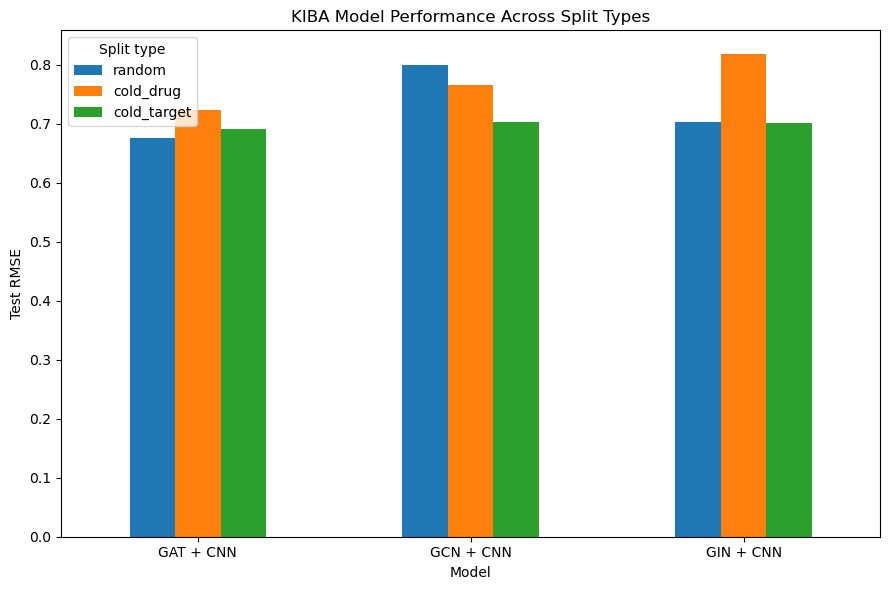

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_all_splits_rmse_comparison.png


In [256]:
kiba_rmse_plot_data = (
    kiba_all_splits_df
    .pivot(
        index="model",
        columns="split_type",
        values="test_rmse",
    )
)

kiba_rmse_plot_data = (
    kiba_rmse_plot_data[
        [
            "random",
            "cold_drug",
            "cold_target",
        ]
    ]
)

ax = kiba_rmse_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.set_xlabel("Model")
ax.set_ylabel("Test RMSE")
ax.set_title(
    "KIBA Model Performance Across Split Types"
)

plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

kiba_all_splits_rmse_plot_path = (
    PLOTS_DIR
    / "kiba_all_splits_rmse_comparison.png"
)

plt.savefig(
    kiba_all_splits_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_all_splits_rmse_plot_path)

# Plot concordance index across KIBA splits

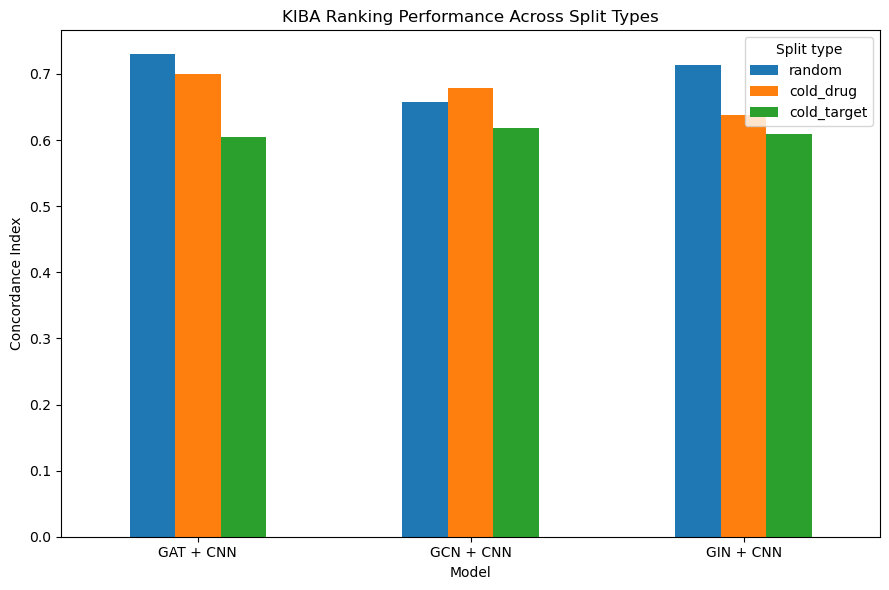

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_all_splits_ci_comparison.png


In [257]:
kiba_ci_plot_data = (
    kiba_all_splits_df
    .pivot(
        index="model",
        columns="split_type",
        values="concordance_index",
    )
)

kiba_ci_plot_data = (
    kiba_ci_plot_data[
        [
            "random",
            "cold_drug",
            "cold_target",
        ]
    ]
)

ax = kiba_ci_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.set_xlabel("Model")
ax.set_ylabel("Concordance Index")
ax.set_title(
    "KIBA Ranking Performance Across Split Types"
)

plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

kiba_all_splits_ci_plot_path = (
    PLOTS_DIR
    / "kiba_all_splits_ci_comparison.png"
)

plt.savefig(
    kiba_all_splits_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_all_splits_ci_plot_path)

# Plot the KIBA generalisation gaps

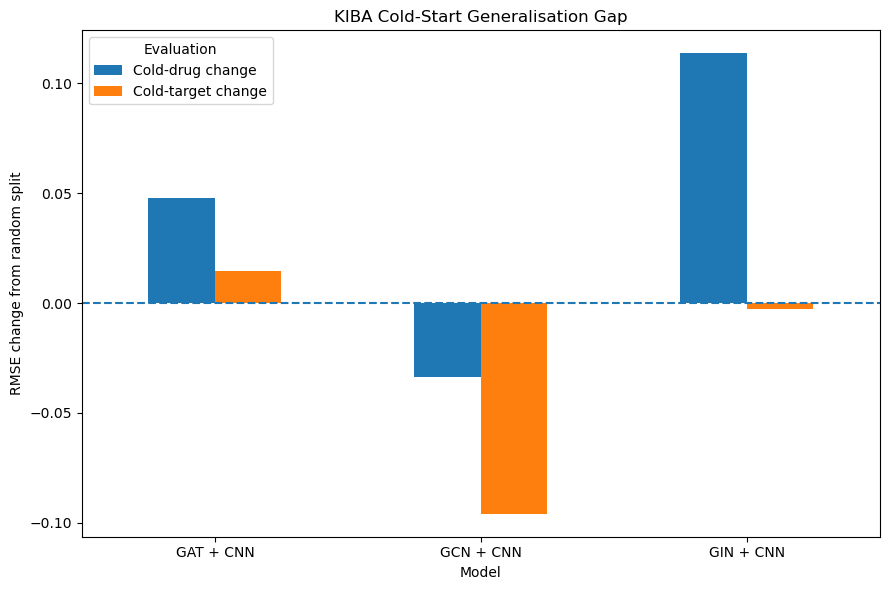

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/kiba_rmse_generalisation_gap.png


In [258]:
kiba_gap_plot_data = (
    kiba_generalisation_gap_df
    .set_index("model")
    [
        [
            "cold_drug_rmse_change",
            "cold_target_rmse_change",
        ]
    ]
    .rename(
        columns={
            "cold_drug_rmse_change": (
                "Cold-drug change"
            ),
            "cold_target_rmse_change": (
                "Cold-target change"
            ),
        }
    )
)

ax = kiba_gap_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.axhline(
    y=0,
    linestyle="--",
    label="_nolegend_",
)

ax.set_xlabel("Model")
ax.set_ylabel(
    "RMSE change from random split"
)

ax.set_title(
    "KIBA Cold-Start Generalisation Gap"
)

plt.xticks(rotation=0)
plt.legend(title="Evaluation")
plt.tight_layout()

kiba_generalisation_gap_plot_path = (
    PLOTS_DIR
    / "kiba_rmse_generalisation_gap.png"
)

plt.savefig(
    kiba_generalisation_gap_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(kiba_generalisation_gap_plot_path)

# Compare total recorded training time

In [259]:
kiba_runtime_summary_df = (
    kiba_all_splits_df
    .groupby(
        "model",
        observed=True,
    )
    .agg(
        total_training_minutes=(
            "training_runtime_minutes",
            "sum",
        ),
        average_training_minutes=(
            "training_runtime_minutes",
            "mean",
        ),
    )
    .reset_index()
)

display(
    kiba_runtime_summary_df.round(2)
)

,model,total_training_minutes,average_training_minutes
0,GAT + CNN,271.46,90.49
1,GCN + CNN,177.25,59.08
2,GIN + CNN,163.23,54.41


# Confirm all final KIBA outputs

In [260]:
final_kiba_outputs = [
    kiba_all_splits_path,
    kiba_split_winners_path,
    kiba_generalisation_gap_path,
    kiba_robustness_summary_path,
    kiba_all_splits_rmse_plot_path,
    kiba_all_splits_ci_plot_path,
    kiba_generalisation_gap_plot_path,
]

for output_path in final_kiba_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in final_kiba_outputs
)

print()

print(
    "Final KIBA comparison completed "
    "successfully."
)

kiba_all_splits_model_comparison.csv → True
kiba_split_winners.csv → True
kiba_generalisation_gap.csv → True
kiba_model_robustness_summary.csv → True
kiba_all_splits_rmse_comparison.png → True
kiba_all_splits_ci_comparison.png → True
kiba_rmse_generalisation_gap.png → True

Final KIBA comparison completed successfully.


## KIBA Evaluation Complete

The three architectures were evaluated using:

- random splitting;
- cold-drug splitting;
- cold-target splitting.

The final KIBA analysis includes:

- split-specific model selection;
- prediction-error comparison;
- ranking-performance comparison;
- cold-start generalisation gaps;
- computational runtime comparison;
- overall KIBA robustness ranking.

The next stage combines the Davis and KIBA findings to select the strongest drug graph architecture for the subsequent AML screening workflow.

In [261]:
objects_to_remove = [
    "kiba_gin_cold_target_model",
    "kiba_gin_cold_target_optimizer",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

print("Previous GIN cold-target objects removed.")

Previous GIN cold-target objects removed.


# Combined Davis and KIBA Model Selection

This section combines validation evidence from the Davis and KIBA datasets.

The final graph architecture is selected using:

1. Average validation rank across six experiments
2. Number of validation wins
3. Average validation-MSE ratio relative to the best model in each experiment
4. Worst validation rank as an additional robustness indicator

Raw RMSE values are not averaged across Davis and KIBA because the two datasets use different affinity-score scales.

Held-out test metrics are reported descriptively but are not used to select the architecture.

# Load the complete Davis and KIBA tables

In [262]:
davis_all_splits_path = (
    METRICS_DIR
    / "davis_all_splits_model_comparison.csv"
)

kiba_all_splits_path = (
    METRICS_DIR
    / "kiba_all_splits_model_comparison.csv"
)

assert davis_all_splits_path.exists(), (
    f"Missing file: {davis_all_splits_path}"
)

assert kiba_all_splits_path.exists(), (
    f"Missing file: {kiba_all_splits_path}"
)

davis_selection_df = pd.read_csv(
    davis_all_splits_path
)

kiba_selection_df = pd.read_csv(
    kiba_all_splits_path
)

print(
    "Davis results:",
    davis_selection_df.shape,
)

print(
    "KIBA results:",
    kiba_selection_df.shape,
)

display(davis_selection_df.head())
display(kiba_selection_df.head())

Davis results: (9, 10)
KIBA results: (9, 13)


,split_type,validation_rank,model,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,random,1,GAT + CNN,0.485106,0.509979,0.714128,0.498821,0.796301,0.605999,300033
1,random,2,GIN + CNN,0.556805,0.599863,0.774508,0.510113,0.749402,0.490215,348801
2,random,3,GCN + CNN,0.563250,0.606687,0.778901,0.502417,0.756204,0.482896,299265
3,cold_drug,1,GCN + CNN,0.756719,0.882943,0.939650,0.726541,0.734928,0.453585,299265
4,cold_drug,2,GIN + CNN,0.758438,0.879811,0.937983,0.665039,0.730261,0.432711,348801


,validation_rank,model,model_name,split_type,best_epoch,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,training_runtime_minutes,trainable_parameters
0,1,GAT + CNN,gat,random,27,0.458653,0.456951,0.675981,0.475973,0.729507,0.591792,87.063653,300033
1,2,GIN + CNN,gin,random,30,0.502294,0.495506,0.703922,0.470470,0.713552,0.535437,69.324823,348801
2,3,GCN + CNN,gcn,random,2,0.641185,0.639251,0.799532,0.516691,0.656824,0.325586,24.224905,299265
3,1,GAT + CNN,gat,cold_drug,29,0.483773,0.523832,0.723762,0.494554,0.700249,0.509231,94.058432,300033
4,2,GCN + CNN,gcn,cold_drug,29,0.604301,0.586246,0.765667,0.500399,0.678561,0.410960,73.921146,299265


# Standardise both result tables

In [263]:
def standardise_benchmark_results(
    dataframe,
    dataset_name,
):
    output_df = dataframe.copy()

    required_columns = [
        "model",
        "split_type",
        "best_validation_mse",
        "test_rmse",
        "test_mae",
        "concordance_index",
        "pearson_correlation",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in output_df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{dataset_name} table is missing: "
            f"{missing_columns}"
        )

    output_df["dataset"] = dataset_name

    # Extract and standardise the graph architecture.
    output_df["model_name"] = (
        output_df["model"]
        .astype(str)
        .str.extract(
            r"(GCN|GAT|GIN)",
            expand=False,
        )
        .str.lower()
    )

    if output_df["model_name"].isna().any():
        invalid_models = output_df.loc[
            output_df["model_name"].isna(),
            "model",
        ].tolist()

        raise ValueError(
            "Unrecognised model labels: "
            f"{invalid_models}"
        )

    output_df["model"] = (
        output_df["model_name"]
        .str.upper()
        + " + CNN"
    )

    output_df["split_type"] = (
        output_df["split_type"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace("-", "_")
    )

    numeric_columns = [
        "best_validation_mse",
        "test_rmse",
        "test_mae",
        "concordance_index",
        "pearson_correlation",
    ]

    for column in numeric_columns:
        output_df[column] = pd.to_numeric(
            output_df[column],
            errors="coerce",
        )

    if output_df[numeric_columns].isna().any().any():
        raise ValueError(
            f"{dataset_name} contains missing or "
            "invalid metric values."
        )

    # Recalculate ranks to ensure identical handling.
    output_df["validation_rank"] = (
        output_df
        .groupby(
            ["dataset", "split_type"]
        )["best_validation_mse"]
        .rank(
            method="min",
            ascending=True,
        )
        .astype(int)
    )

    return output_df


davis_selection_df = (
    standardise_benchmark_results(
        dataframe=davis_selection_df,
        dataset_name="davis",
    )
)

kiba_selection_df = (
    standardise_benchmark_results(
        dataframe=kiba_selection_df,
        dataset_name="kiba",
    )
)

print("Davis and KIBA tables standardised.")

Davis and KIBA tables standardised.


# Combine all 18 model results

In [264]:
combined_benchmark_df = pd.concat(
    [
        davis_selection_df,
        kiba_selection_df,
    ],
    ignore_index=True,
)

combined_benchmark_df["experiment"] = (
    combined_benchmark_df["dataset"]
    .str.upper()
    + " — "
    + combined_benchmark_df["split_type"]
    .map(
        {
            "random": "Random",
            "cold_drug": "Cold-drug",
            "cold_target": "Cold-target",
        }
    )
)

experiment_order = [
    "DAVIS — Random",
    "DAVIS — Cold-drug",
    "DAVIS — Cold-target",
    "KIBA — Random",
    "KIBA — Cold-drug",
    "KIBA — Cold-target",
]

combined_benchmark_df["experiment"] = (
    pd.Categorical(
        combined_benchmark_df["experiment"],
        categories=experiment_order,
        ordered=True,
    )
)

combined_benchmark_df = (
    combined_benchmark_df
    .sort_values(
        [
            "experiment",
            "validation_rank",
        ]
    )
    .reset_index(drop=True)
)

print(
    "Combined rows:",
    len(combined_benchmark_df),
)

display(
    combined_benchmark_df[
        [
            "experiment",
            "validation_rank",
            "model",
            "best_validation_mse",
            "test_rmse",
            "concordance_index",
        ]
    ].round(4)
)

Combined rows: 18


,experiment,validation_rank,model,best_validation_mse,test_rmse,concordance_index
0,DAVIS — Random,1,GAT + CNN,0.4851,0.7141,0.7963
1,DAVIS — Random,2,GIN + CNN,0.5568,0.7745,0.7494
2,DAVIS — Random,3,GCN + CNN,0.5633,0.7789,0.7562
3,DAVIS — Cold-drug,1,GCN + CNN,0.7567,0.9397,0.7349
4,DAVIS — Cold-drug,2,GIN + CNN,0.7584,0.9380,0.7303
5,DAVIS — Cold-drug,3,GAT + CNN,0.7904,0.9744,0.6804
6,DAVIS — Cold-target,1,GAT + CNN,0.5124,0.6371,0.8031
7,DAVIS — Cold-target,2,GIN + CNN,0.6342,0.6973,0.7631
8,DAVIS — Cold-target,3,GCN + CNN,0.6870,0.7286,0.7126
9,KIBA — Random,1,GAT + CNN,0.4587,0.6760,0.7295


# Calculate dimensionless validation performance

In [265]:
best_validation_mse_per_experiment = (
    combined_benchmark_df
    .groupby(
        "experiment",
        observed=True,
    )["best_validation_mse"]
    .transform("min")
)

combined_benchmark_df[
    "validation_mse_ratio_to_best"
] = (
    combined_benchmark_df[
        "best_validation_mse"
    ]
    / best_validation_mse_per_experiment
)

combined_benchmark_df[
    "validation_percent_above_best"
] = (
    combined_benchmark_df[
        "validation_mse_ratio_to_best"
    ]
    - 1
) * 100

display(
    combined_benchmark_df[
        [
            "experiment",
            "model",
            "validation_rank",
            "best_validation_mse",
            "validation_mse_ratio_to_best",
            "validation_percent_above_best",
        ]
    ].round(4)
)

,experiment,model,validation_rank,best_validation_mse,validation_mse_ratio_to_best,validation_percent_above_best
0,DAVIS — Random,GAT + CNN,1,0.4851,1.0000,0.0000
1,DAVIS — Random,GIN + CNN,2,0.5568,1.1478,14.7801
2,DAVIS — Random,GCN + CNN,3,0.5633,1.1611,16.1086
3,DAVIS — Cold-drug,GCN + CNN,1,0.7567,1.0000,0.0000
4,DAVIS — Cold-drug,GIN + CNN,2,0.7584,1.0023,0.2272
5,DAVIS — Cold-drug,GAT + CNN,3,0.7904,1.0445,4.4534
6,DAVIS — Cold-target,GAT + CNN,1,0.5124,1.0000,0.0000
7,DAVIS — Cold-target,GIN + CNN,2,0.6342,1.2377,23.7697
8,DAVIS — Cold-target,GCN + CNN,3,0.6870,1.3407,34.0727
9,KIBA — Random,GAT + CNN,1,0.4587,1.0000,0.0000


# Identify the six validation winners

In [266]:
combined_split_winners_df = (
    combined_benchmark_df[
        combined_benchmark_df[
            "validation_rank"
        ] == 1
    ]
    [
        [
            "dataset",
            "split_type",
            "experiment",
            "model",
            "best_validation_mse",
            "test_rmse",
            "concordance_index",
        ]
    ]
    .reset_index(drop=True)
)

display(
    combined_split_winners_df.round(4)
)

,dataset,split_type,experiment,model,best_validation_mse,test_rmse,concordance_index
0,davis,random,DAVIS — Random,GAT + CNN,0.4851,0.7141,0.7963
1,davis,cold_drug,DAVIS — Cold-drug,GCN + CNN,0.7567,0.9397,0.7349
2,davis,cold_target,DAVIS — Cold-target,GAT + CNN,0.5124,0.6371,0.8031
3,kiba,random,KIBA — Random,GAT + CNN,0.4587,0.6760,0.7295
4,kiba,cold_drug,KIBA — Cold-drug,GAT + CNN,0.4838,0.7238,0.7002
5,kiba,cold_target,KIBA — Cold-target,GAT + CNN,0.5469,0.6906,0.6042


# Create the validation-rank matrix

In [267]:
combined_validation_rank_matrix = (
    combined_benchmark_df
    .pivot(
        index="model",
        columns="experiment",
        values="validation_rank",
    )
)

combined_validation_rank_matrix = (
    combined_validation_rank_matrix
    .reindex(columns=experiment_order)
)

display(
    combined_validation_rank_matrix
)

experiment,DAVIS — Random,DAVIS — Cold-drug,DAVIS — Cold-target,KIBA — Random,KIBA — Cold-drug,KIBA — Cold-target
model,,,,,,
GAT + CNN,1,3,1,1,1,1
GCN + CNN,3,1,3,3,2,3
GIN + CNN,2,2,2,2,3,2


# Create the combined architecture ranking

In [268]:
combined_model_selection_df = (
    combined_benchmark_df
    .groupby(
        [
            "model",
            "model_name",
        ],
        observed=True,
    )
    .agg(
        average_validation_rank=(
            "validation_rank",
            "mean",
        ),
        median_validation_rank=(
            "validation_rank",
            "median",
        ),
        validation_wins=(
            "validation_rank",
            lambda values: int(
                (values == 1).sum()
            ),
        ),
        second_place_finishes=(
            "validation_rank",
            lambda values: int(
                (values == 2).sum()
            ),
        ),
        worst_validation_rank=(
            "validation_rank",
            "max",
        ),
        average_validation_ratio_to_best=(
            "validation_mse_ratio_to_best",
            "mean",
        ),
        maximum_validation_ratio_to_best=(
            "validation_mse_ratio_to_best",
            "max",
        ),
    )
    .reset_index()
)

combined_model_selection_df = (
    combined_model_selection_df
    .sort_values(
        [
            "average_validation_rank",
            "validation_wins",
            "average_validation_ratio_to_best",
            "worst_validation_rank",
        ],
        ascending=[
            True,
            False,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

combined_model_selection_df.insert(
    0,
    "combined_model_rank",
    range(
        1,
        len(
            combined_model_selection_df
        ) + 1,
    ),
)

display(
    combined_model_selection_df.round(4)
)

,combined_model_rank,model,model_name,average_validation_rank,median_validation_rank,validation_wins,second_place_finishes,worst_validation_rank,average_validation_ratio_to_best,maximum_validation_ratio_to_best
0,1,GAT + CNN,gat,1.3333,1.0,5,0,3,1.0074,1.0445
1,2,GIN + CNN,gin,2.1667,2.0,0,5,3,1.1457,1.3735
2,3,GCN + CNN,gcn,2.5000,3.0,1,1,3,1.2284,1.3980


# Show the selected graph architecture

In [269]:
selected_architecture = (
    combined_model_selection_df.iloc[0]
)

selected_model_label = str(
    selected_architecture["model"]
)

selected_model_name = str(
    selected_architecture["model_name"]
)

print("Selected graph architecture")
print("---------------------------")

print(
    "Model:",
    selected_model_label,
)

print(
    "Model name:",
    selected_model_name,
)

print(
    "Average validation rank:",
    round(
        float(
            selected_architecture[
                "average_validation_rank"
            ]
        ),
        4,
    ),
)

print(
    "Validation wins:",
    int(
        selected_architecture[
            "validation_wins"
        ]
    ),
    "out of 6 experiments",
)

print(
    "Second-place finishes:",
    int(
        selected_architecture[
            "second_place_finishes"
        ]
    ),
)

print(
    "Worst validation rank:",
    int(
        selected_architecture[
            "worst_validation_rank"
        ]
    ),
)

print(
    "Average validation ratio to best:",
    round(
        float(
            selected_architecture[
                "average_validation_ratio_to_best"
            ]
        ),
        4,
    ),
)

Selected graph architecture
---------------------------
Model: GAT + CNN
Model name: gat
Average validation rank: 1.3333
Validation wins: 5 out of 6 experiments
Second-place finishes: 0
Worst validation rank: 3
Average validation ratio to best: 1.0074


# Create a descriptive test-rank summary

In [270]:
combined_benchmark_df["test_rmse_rank"] = (
    combined_benchmark_df
    .groupby(
        [
            "dataset",
            "split_type",
        ]
    )["test_rmse"]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

combined_test_rank_summary_df = (
    combined_benchmark_df
    .groupby(
        "model",
        observed=True,
    )
    .agg(
        average_test_rmse_rank=(
            "test_rmse_rank",
            "mean",
        ),
        test_rmse_wins=(
            "test_rmse_rank",
            lambda values: int(
                (values == 1).sum()
            ),
        ),
        average_concordance_index=(
            "concordance_index",
            "mean",
        ),
        average_pearson_correlation=(
            "pearson_correlation",
            "mean",
        ),
    )
    .reset_index()
    .sort_values(
        "average_test_rmse_rank"
    )
    .reset_index(drop=True)
)

display(
    combined_test_rank_summary_df.round(4)
)

,model,average_test_rmse_rank,test_rmse_wins,average_concordance_index,average_pearson_correlation
0,GAT + CNN,1.3333,5,0.7190,0.5065
1,GIN + CNN,2.0000,1,0.7006,0.4425
2,GCN + CNN,2.6667,0,0.6928,0.3978


# Save the final selection files

In [271]:
combined_experiment_table_path = (
    METRICS_DIR
    / "combined_davis_kiba_experiment_table.csv"
)

combined_model_selection_path = (
    METRICS_DIR
    / "combined_davis_kiba_model_selection.csv"
)

combined_split_winners_path = (
    METRICS_DIR
    / "combined_davis_kiba_split_winners.csv"
)

combined_test_rank_summary_path = (
    METRICS_DIR
    / "combined_davis_kiba_test_rank_summary.csv"
)

selected_architecture_path = (
    METRICS_DIR
    / "selected_gnn_architecture.json"
)

combined_benchmark_df.to_csv(
    combined_experiment_table_path,
    index=False,
)

combined_model_selection_df.to_csv(
    combined_model_selection_path,
    index=False,
)

combined_split_winners_df.to_csv(
    combined_split_winners_path,
    index=False,
)

combined_test_rank_summary_df.to_csv(
    combined_test_rank_summary_path,
    index=False,
)

selected_architecture_payload = {
    "selected_model": selected_model_label,
    "selected_model_name": selected_model_name,
    "selection_basis": (
        "Average validation rank across Davis "
        "and KIBA random, cold-drug and "
        "cold-target experiments"
    ),
    "number_of_validation_experiments": 6,
    "average_validation_rank": float(
        selected_architecture[
            "average_validation_rank"
        ]
    ),
    "median_validation_rank": float(
        selected_architecture[
            "median_validation_rank"
        ]
    ),
    "validation_wins": int(
        selected_architecture[
            "validation_wins"
        ]
    ),
    "second_place_finishes": int(
        selected_architecture[
            "second_place_finishes"
        ]
    ),
    "worst_validation_rank": int(
        selected_architecture[
            "worst_validation_rank"
        ]
    ),
    "average_validation_ratio_to_best": float(
        selected_architecture[
            "average_validation_ratio_to_best"
        ]
    ),
}

with open(
    selected_architecture_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        selected_architecture_payload,
        file,
        indent=4,
    )

print("Combined selection files saved.")

Combined selection files saved.


# Plot validation ranks across six experiments

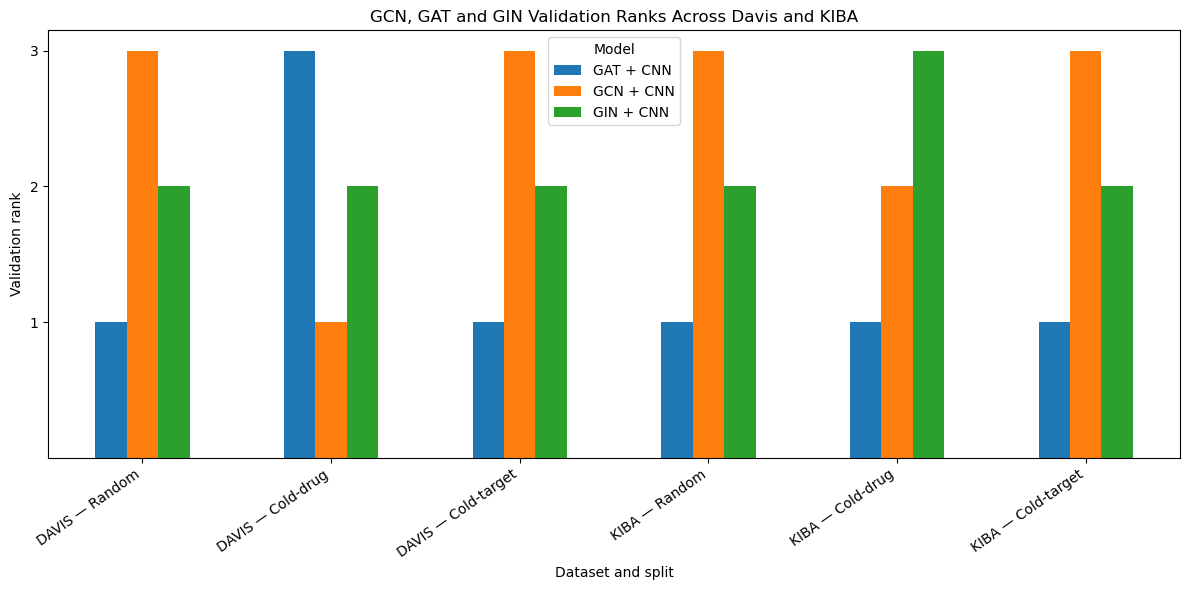

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/combined_davis_kiba_validation_ranks.png


In [272]:
validation_rank_plot_data = (
    combined_validation_rank_matrix
    .transpose()
)

ax = validation_rank_plot_data.plot(
    kind="bar",
    figsize=(12, 6),
)

ax.set_xlabel("Dataset and split")
ax.set_ylabel("Validation rank")
ax.set_title(
    "GCN, GAT and GIN Validation Ranks "
    "Across Davis and KIBA"
)

ax.set_yticks([1, 2, 3])

plt.xticks(
    rotation=35,
    ha="right",
)

plt.legend(title="Model")
plt.tight_layout()

combined_validation_rank_plot_path = (
    PLOTS_DIR
    / "combined_davis_kiba_validation_ranks.png"
)

plt.savefig(
    combined_validation_rank_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(combined_validation_rank_plot_path)

# Plot average validation rank

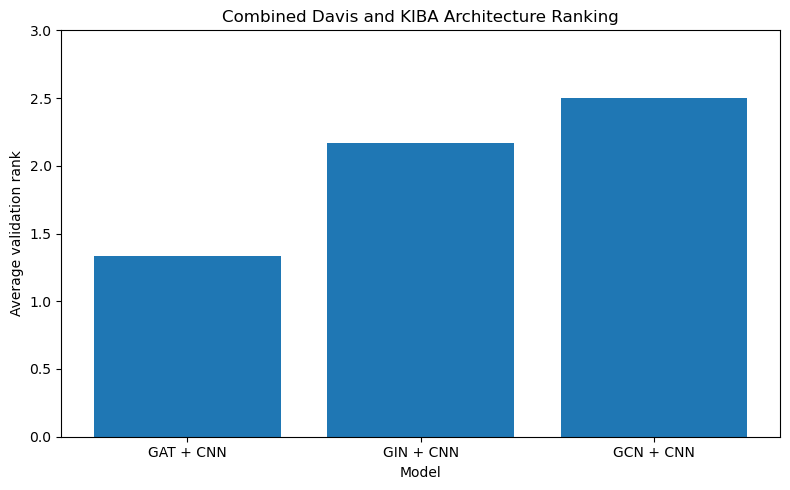

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/combined_davis_kiba_average_validation_rank.png


In [273]:
average_rank_plot_df = (
    combined_model_selection_df
    .sort_values(
        "average_validation_rank"
    )
)

plt.figure(figsize=(8, 5))

plt.bar(
    average_rank_plot_df["model"],
    average_rank_plot_df[
        "average_validation_rank"
    ],
)

plt.xlabel("Model")
plt.ylabel("Average validation rank")

plt.title(
    "Combined Davis and KIBA "
    "Architecture Ranking"
)

plt.ylim(
    0,
    max(
        3,
        average_rank_plot_df[
            "average_validation_rank"
        ].max() + 0.5,
    ),
)

plt.tight_layout()

combined_average_rank_plot_path = (
    PLOTS_DIR
    / "combined_davis_kiba_average_validation_rank.png"
)

plt.savefig(
    combined_average_rank_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(combined_average_rank_plot_path)

# Confirm all outputs

In [274]:
combined_selection_outputs = [
    combined_experiment_table_path,
    combined_model_selection_path,
    combined_split_winners_path,
    combined_test_rank_summary_path,
    selected_architecture_path,
    combined_validation_rank_plot_path,
    combined_average_rank_plot_path,
]

for output_path in combined_selection_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in combined_selection_outputs
)

print()
print(
    "Combined Davis and KIBA model "
    "selection completed successfully."
)

print(
    "Selected architecture:",
    selected_model_label,
)

combined_davis_kiba_experiment_table.csv → True
combined_davis_kiba_model_selection.csv → True
combined_davis_kiba_split_winners.csv → True
combined_davis_kiba_test_rank_summary.csv → True
selected_gnn_architecture.json → True
combined_davis_kiba_validation_ranks.png → True
combined_davis_kiba_average_validation_rank.png → True

Combined Davis and KIBA model selection completed successfully.
Selected architecture: GAT + CNN


# Combined Benchmark Selection Complete

The GCN + CNN, GAT + CNN and GIN + CNN architectures were compared across six validation experiments:

- Davis random split
- Davis cold-drug split
- Davis cold-target split
- KIBA random split
- KIBA cold-drug split
- KIBA cold-target split

The final graph architecture was selected using validation evidence rather than held-out test performance.

Raw Davis and KIBA errors were not directly averaged because the datasets use different affinity-score scales.

The selected graph encoder will be used in the next representation experiment and subsequent AML screening workflow.